In [1]:
import scipy
import sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import skew
from scipy.stats import kurtosis
from sklearn import linear_model
from itertools import combinations

# import equivariant steerable cnn
import escnn.gspaces
import escnn.nn

import torch
import torch.nn as nn
import torch.nn.functional as F

from tqdm import tqdm
# Checking if you have a GPU and CUDA set up -- if not, training will take longer by running on the CPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'
# device = 'cpu'
# Set the plotting style
#plt.style.use('seaborn-poster')

In the filter weights training phase, why force beta hyperparameters in the nn.Linear to be positive can pick up characteristics from class A? Is it a special set-up such that only for structured data vs. random? In a binary classification task between gaussian and random, take absbeta to be True or not does not affect the validation accuracy in the training. But it will make both filters have some features instead of force the filter to learn gaussian only?

### Plot an example of the prepared data set

In [2]:
log_example = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/maps_takahashi_cosmo/gaussian_lognormal_z10_z16/lognormal_data_12180_maps_200_by_200pixels_20_by_20deg_zs10_zs16_gnom_projection.npy')[:5000,1,:,:]
grf_example = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/maps_takahashi_cosmo/gaussian_lognormal_z10_z16/gaussian_data_12180_maps_200_by_200pixels_20_by_20deg_zs10_zs16_gnom_projection.npy')[:5000,1,:,:]
#log_example_s = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/maps_takahashi_cosmo/gaussian_lognormal_z10_z16/lognormal_data_12180_maps_100_by_100pixels_10_by_10deg_zs10_zs16_gnom_projection.npy')[3780:10780,1,:,:]
#grf_example_s = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/maps_takahashi_cosmo/gaussian_lognormal_z10_z16/gaussian_data_12180_maps_100_by_100pixels_10_by_10deg_zs10_zs16_gnom_projection.npy')[3780:10780,1,:,:]
#log_example_l = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/maps_takahashi_cosmo/gaussian_lognormal_z10_z16/lognormal_data_3780_maps_400_by_400pixels_40_by_40deg_zs10_zs16_gnom_projection.npy')[:2000,1,:,:]
#grf_example_l = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/maps_takahashi_cosmo/gaussian_lognormal_z10_z16/gaussian_data_3780_maps_400_by_400pixels_40_by_40deg_zs10_zs16_gnom_projection.npy')[:2000,1,:,:]

#log_example_lambda1 = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/maps_takahashi_cosmo/gaussian_lognormal_z10_z16/lognormal_data_12180_maps_200_by_200pixels_20_by_20deg_zs10_zs16_gnom_projection.npy')[:,1,:,:]
#log_example_lambda2 = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/maps_takahashi_cosmo/gaussian_lognormal_z10_z16/lognormal_data_12180_maps_200_by_200pixels_20_by_20deg_zs10_zs16_new_lambda_gnom_projection.npy')[:,1,:,:]

#grf_example_s = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/grf_data_10000_maps_120_by_120_pixels_var_1.0_corrlen_5.0.npy')[:5000]
#grf_example_s1 = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/grf_data_10000_maps_60_by_60_pixels_var_1.0_corrlen_5.0.npy')
#grf_example_m = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/grf_data_10000_maps_120_by_120_pixels_var_1.0_corrlen_10.0.npy')
#grf_example_l = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/grf_data_10000_maps_120_by_120_pixels_var_1.0_corrlen_20.0.npy')[:5000]

#massivenus_00 = np.load('/e/ocean1/users/lgong/CCNN/massivenus_data/mv0.0_omega0.3/kappa_maps_zs10_128_by_128pixels_3.5_by_3.5deg.npy')
#massivenus_01 = np.load('/e/ocean1/users/lgong/CCNN/massivenus_data/mv0.1_omega0.3/kappa_maps_zs10_128_by_128pixels_3.5_by_3.5deg.npy')

#kappa_no_IA = np.load('/e/ocean1/users/lgong/CCNN/cosmogrid/kappa_plus_IA_NLA_A0.0_alpha_1.66_data_11600_maps_200_by_200pixels_20_by_20deg_4_des_zsbin_gnom_projection.npy')
#kappa_IA_Aamp = np.load('/e/ocean1/users/lgong/CCNN/cosmogrid/kappa_plus_IA_NLA_A0.36_alpha_1.66_data_11600_maps_200_by_200pixels_20_by_20deg_4_des_zsbin_gnom_projection.npy')

#kappa_omega_p = np.load('/e/ocean1/users/lgong/CCNN/cosmogrid/kappa_delta_omegam_plus_data_11600_maps_200_by_200pixels_20_by_20deg_4_des_zsbin_gnom_projection.npy')[:5800,2,:,:]
#kappa_omega_m = np.load('/e/ocean1/users/lgong/CCNN/cosmogrid/kappa_delta_omegam_minus_data_11600_maps_200_by_200pixels_20_by_20deg_4_des_zsbin_gnom_projection.npy')[:5800,2,:,:]
#kappa_omega_p_noisy = np.load('/e/ocean1/users/lgong/CCNN/cosmogrid/kappa_noisy_delta_omegam_plus_data_11600_maps_200_by_200pixels_20_by_20deg_4_des_zsbin_gnom_projection.npy')[:5800,:,:,:]
#kappa_omega_m_noisy = np.load('/e/ocean1/users/lgong/CCNN/cosmogrid/kappa_noisy_delta_omegam_minus_data_11600_maps_200_by_200pixels_20_by_20deg_4_des_zsbin_gnom_projection.npy')[:5800,:,:,:]

#kappa_w0_p = np.load('/e/ocean1/users/lgong/CCNN/cosmogrid/kappa_delta_w0_plus_data_11600_maps_200_by_200pixels_20_by_20deg_smooth_40_arcmin_4_des_zsbin_gnom_projection.npy')[:5800,:,:,:]
#kappa_w0_noise_p = np.load('/e/ocean1/users/lgong/CCNN/cosmogrid/kappa_noisy_delta_w0_plus_data_11600_maps_200_by_200pixels_20_by_20deg_smooth_10_arcmin_4_des_zsbin_gnom_projection.npy')[:5800,:,:,:]
#kappa_w0_m = np.load('/e/ocean1/users/lgong/CCNN/cosmogrid/kappa_delta_w0_minus_data_11600_maps_200_by_200pixels_20_by_20deg_smooth_40_arcmin_4_des_zsbin_gnom_projection.npy')[:5800,:,:,:]

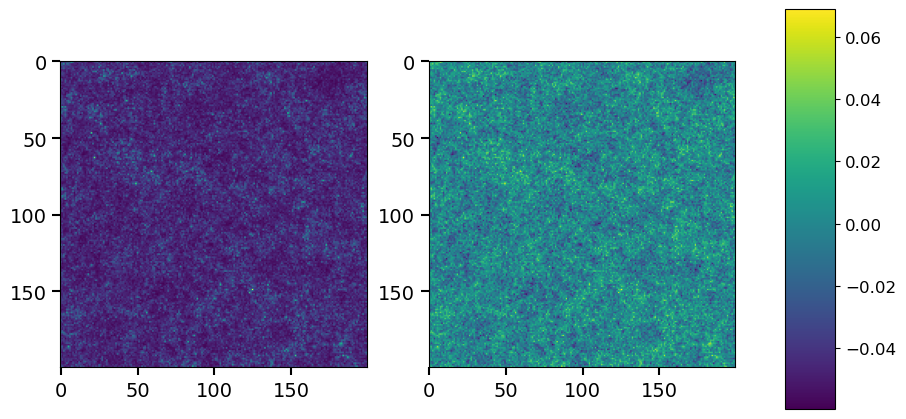

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10,10))
#im1 = axes[0].imshow(grf_example_s[3])
#im2 = axes[1].imshow(grf_example_l[3])

im1 = axes[0].imshow(log_example[3])
im2 = axes[1].imshow(grf_example[3])

#im1 = axes[0].imshow(log_example_lambda1[3])
#im2 = axes[1].imshow(log_example_lambda2[3])

#im1 = axes[0].imshow(kappa_no_IA[3,3])
#im2 = axes[1].imshow(kappa_IA_Aamp[3,3])

#im1 = axes[0].imshow(kappa_omega_p[3])
#im2 = axes[1].imshow(kappa_omega_m[3])
#im2 = axes[1].imshow(kappa_omega_p_noisy[3,3])

#im1 = axes[0].imshow(kappa_w0_p[3,3])
#im2 = axes[1].imshow(kappa_w0_m[3,3])

fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.85, 0.3, 0.05, 0.4])
#axes[0].grid(which='minor', color='w', linestyle='-', linewidth=2)
cbar = plt.colorbar(im2, cax=cbar_ax)
tick_font_size = 12
cbar.ax.tick_params(labelsize=tick_font_size)
#axes[0].set_title('$\ell = 5.0$', fontsize=14)
#axes[1].set_title('$\ell = 20.0$', fontsize=14)
axes[0].tick_params(length=6.0, labelsize=14, width=1.5)
#axes[0].set_xticks([0, 20, 40, 60, 80, 100])
#axes[0].set_yticks([0, 20, 40, 60, 80, 100])
axes[1].tick_params(length=6.0, labelsize=14, width=1.5)
#axes[1].set_xticks([0, 20, 40, 60, 80, 100])
#axes[1].set_yticks([0, 20, 40, 60, 80, 100])
plt.show()
#plt.savefig('paper_plot/grf_example.pdf', format='pdf', dpi=300, bbox_inches='tight')

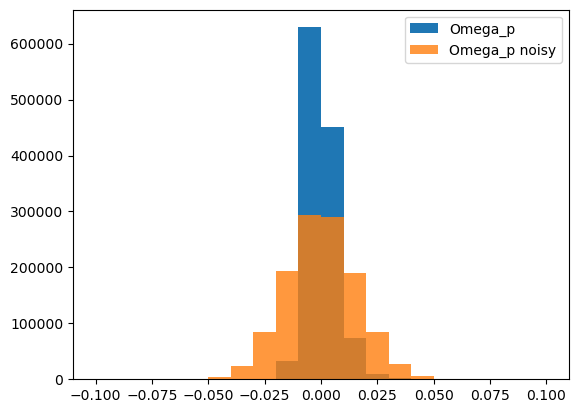

In [27]:
plt.hist(kappa_w0_p[:30,3].reshape(-1), bins=20, range=(-0.1, 0.1), label='Omega_p')[2]
plt.hist(kappa_w0_noise_p[:30,3].reshape(-1), bins=20, range=(-0.1, 0.1), alpha=0.8, label='Omega_p noisy')[2]
#plt.hist(kappa_omega_m[:20,3].reshape(-1), bins=40, range=(-0.5, 0.5), label='Omega_m')[2]
#plt.hist(kappa_omega_m_noisy[:20,3].reshape(-1), bins=40, range=(-0.5, 0.5), alpha=0.5, label='Omega_m noisy')[2]
plt.legend()

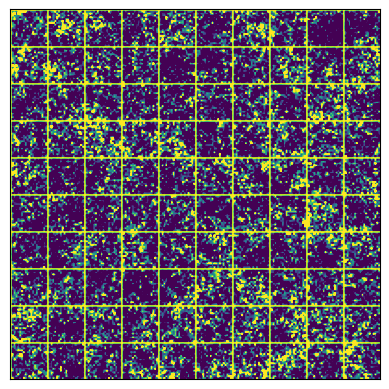

In [115]:
img = log_example[3,1]*8
vmin = log_example[3,1].min()
vmax = log_example[3,1].max()


fig = plt.figure()
ax = fig.add_subplot()
myInterval=1
loc = plticker.MultipleLocator(base=myInterval)
ax.xaxis.set_major_locator(loc)
ax.yaxis.set_major_locator(loc)

dx, dy = 20,20

grid_color = 0.2
img[:,::dy] = grid_color
img[::dx,:] = grid_color

ax.imshow(img, vmin=vmin, vmax=vmax)
# Add the grid
#ax.grid(which='major', axis='both', linestyle='-', alpha=0.2, color='w', visible=True, lw=1.5)

#ax.imshow(filters[n, chan], vmin=vmin, vmax=vmax)
ax.tick_params(
    bottom=False,
    labelbottom=False,
    left=False,
    labelleft=False,
    )
#ax.set_ylabel(chan_labels[chan], rotation=90, fontsize=30)
#plt.show()
plt.savefig('paper_plot/input_kappa_zs2.png', dpi=300)

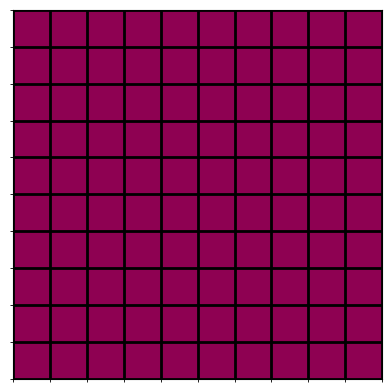

In [177]:
#a = np.array([[0, 2, 0],[2, 0, 2], [0, 2, 0]])
a = np.ones((10,10))
plt.figure()
im = plt.imshow(a, interpolation='none', aspect='equal', cmap='PiYG')

ax = plt.gca();

# Major ticks
ax.set_xticks(np.arange(0, 10, 1))
ax.set_yticks(np.arange(0, 10, 1))

# Labels for major ticks
ax.set_xticklabels(np.arange(1, 11, 1))
ax.set_yticklabels(np.arange(1, 11, 1))

# Minor ticks
ax.set_xticks(np.arange(-.5, 10, 1), minor=True)
ax.set_yticks(np.arange(-.5, 10, 1), minor=True)

# Gridlines based on minor ticks
ax.grid(which='minor', color='k', linestyle='-', linewidth=2)

# Remove minor ticks
ax.tick_params(
    bottom=False,
    labelbottom=False,
    left=False,
    labelleft=False,
    )

plt.savefig('paper_plot/escnn_C1_fig1.png', dpi=300)

### Downgrade the MassiveNuS convergence maps by average pooling

In [13]:
massivenus_00_tensor = torch.from_numpy(massivenus_00)
massivenus_01_tensor = torch.from_numpy(massivenus_01)

In [14]:
pooling = nn.AvgPool2d(kernel_size=4, stride=4)
massivenus_00_tensor = pooling(massivenus_00_tensor)
massivenus_01_tensor = pooling(massivenus_01_tensor)

In [15]:
massivenus_00_pooling = massivenus_00_tensor.numpy()
massivenus_01_pooling = massivenus_01_tensor.numpy()

In [18]:
np.save('/e/ocean1/users/lgong/CCNN/massivenus_data/mv0.0_omega0.3/kappa_maps_zs10_128_by_128pixels_3.5_by_3.5deg.npy', massivenus_00_pooling)
np.save('/e/ocean1/users/lgong/CCNN/massivenus_data/mv0.1_omega0.3/kappa_maps_zs10_128_by_128pixels_3.5_by_3.5deg.npy', massivenus_01_pooling)

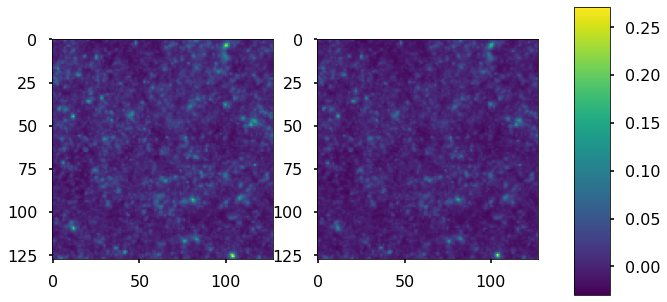

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10,10))
im1 = axes[0].imshow(massivenus_00_pooling[3,0])
im2 = axes[1].imshow(massivenus_01_pooling[3,0])

#im1 = axes[0].imshow(log_example[3])
#im2 = axes[1].imshow(grf_example[3])
fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.85, 0.3, 0.05, 0.4]) 
 	 	 	 	 
fig.colorbar(im2, cax=cbar_ax)
plt.show()

### Check the PDF moments of the map mean 

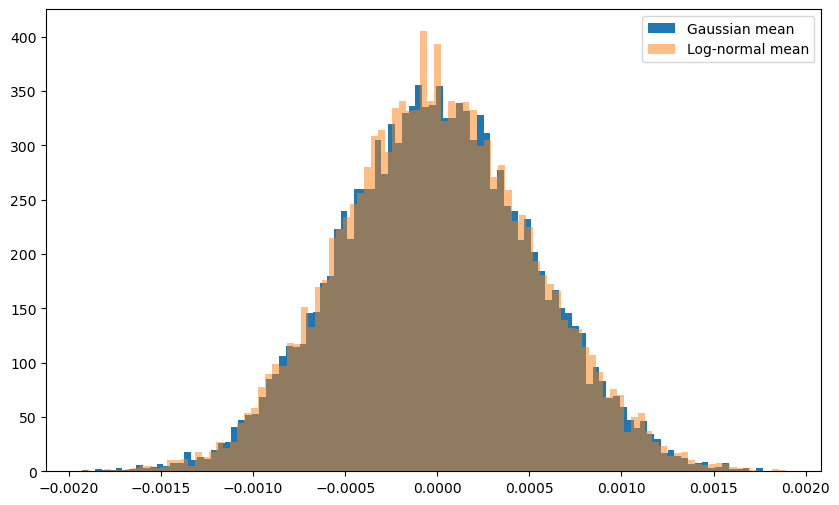

In [34]:
#mean_grf_s = grf_example_s.mean((-2,-1))
#mean_grf_l = grf_example_l.mean((-2,-1))

mean_gaussian = grf_example.mean((-2,-1))
mean_lognormal = log_example.mean((-2,-1))

plt.figure(figsize=(10,6))
plt.hist(mean_gaussian, bins=100, label='Gaussian mean')[2]
plt.hist(mean_lognormal, bins=100, alpha=0.5, label='Log-normal mean')[2]
plt.legend()

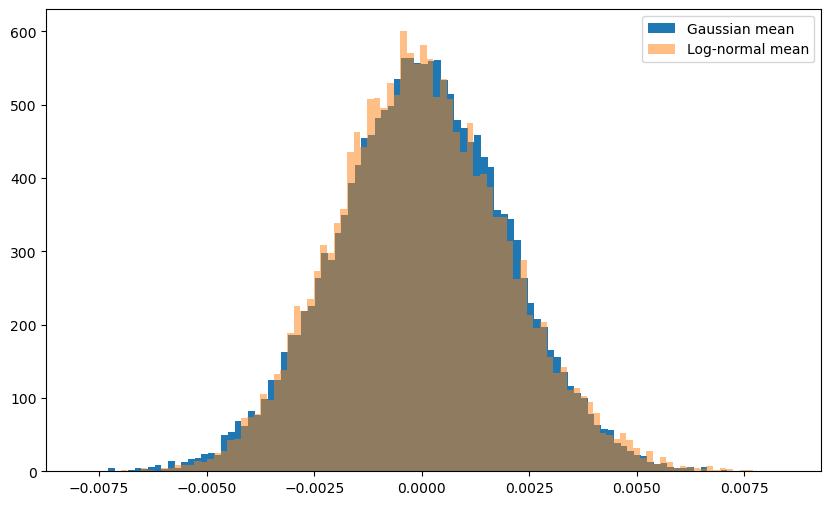

In [36]:
mean_gaussian = grf_example.mean((-2,-1))
mean_lognormal = log_example.mean((-2,-1))

plt.figure(figsize=(10,6))
plt.hist(mean_gaussian, bins=100, label='Gaussian mean')[2]
plt.hist(mean_lognormal, bins=100, alpha=0.5, label='Log-normal mean')[2]
plt.legend()

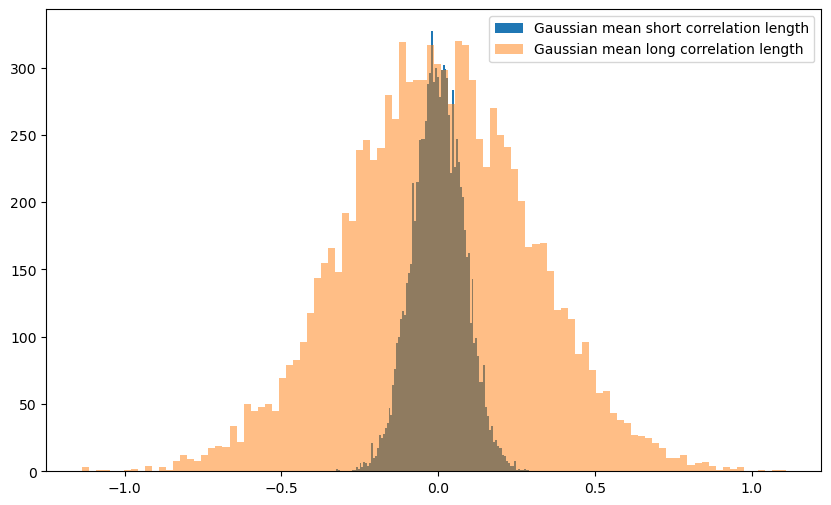

In [38]:
mean_grf_s = grf_example_s.mean((-2,-1))
mean_grf_l = grf_example_l.mean((-2,-1))

#mean_gaussian = grf_example.mean((-2,-1))
#mean_lognormal = log_example.mean((-2,-1))

plt.figure(figsize=(10,6))
plt.hist(mean_grf_s, bins=100, label='Gaussian mean short correlation length')[2]
plt.hist(mean_grf_l, bins=100, alpha=0.5, label='Gaussian mean long correlation length')[2]
plt.legend()

In [38]:
print('The expectation value of the mean distribution of Gaussian random field is ', np.mean(mean_grf))
print('The expectation value of the mean distribution of Log-normal random field is ', np.mean(mean_log))

The expectation value of the mean distribution of Gaussian random field is  -3.216847816834612e-06
The expectation value of the mean distribution of Log-normal random field is  -4.899763280414029e-06


In [39]:
print('The variance of the mean distribution of Gaussian random field is ', np.var(mean_grf, ddof=1))
print('The variance of the mean distribution of Log-normal random field is ', np.var(mean_log, ddof=1))

The variance of the mean distribution of Gaussian random field is  3.977945977245553e-06
The variance of the mean distribution of Log-normal random field is  3.965904676363546e-06


In [40]:
print('The skewness of the mean distribution of Gaussian random field is ', skew(mean_grf, axis=0, bias=True))
print('The skewness of the mean distribution of Log-normal random field is ', skew(mean_log, axis=0, bias=True))

The skewness of the mean distribution of Gaussian random field is  -0.026997787156309933
The skewness of the mean distribution of Log-normal random field is  0.17345134057497782


Mean distribution of log-normal random field has a non-zero skewness, implying that it has more weight in the left tail which can be observed in the above histogram

In [41]:
print('The kurtosis of the mean distribution of Gaussian random field is ', kurtosis(mean_grf, axis=0, bias=True))
print('The kurtosis of the mean distribution of Log-normal random field is ', kurtosis(mean_log, axis=0, bias=True))

The kurtosis of the mean distribution of Gaussian random field is  0.034511981479810494
The kurtosis of the mean distribution of Log-normal random field is  0.072147512294916


Here we the Fisher's definition of kurtosis: A positive Fisher’s kurtosis means the distribution has significant outliers while a negative Fisher’s kurtosis would mean that the distribution of probability density is much more uniform compared to a normal distribution

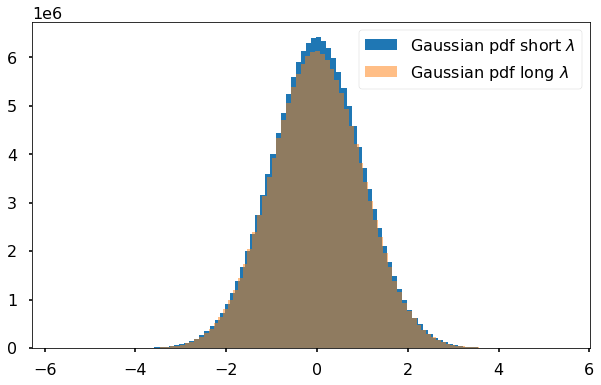

In [6]:
grf_s = grf_example_s.flatten()
grf_l = grf_example_l.flatten()

plt.figure(figsize=(10,6))
plt.hist(grf_s, bins=100, label='Gaussian pdf short '+r'$\lambda$')[2]
plt.hist(grf_l, bins=100, alpha=0.5, label='Gaussian pdf long '+r'$\lambda$')[2]
plt.legend()

In [12]:
print('The skewness of Gaussian random field is ', skew(gaussian, axis=0, bias=True))
print('The skewness of Log-normal random field is ', skew(lognormal, axis=0, bias=True))

The skewness of Gaussian random field is  3.1699160039223494e-05
The skewness of Log-normal random field is  1.6879292933821024


In [13]:
print('The kurtosis of Gaussian random field is ', kurtosis(gaussian, axis=0, bias=True))
print('The kurtosis of Log-normal random field is ', kurtosis(lognormal, axis=0, bias=True))

The kurtosis of Gaussian random field is  0.0004100995379228145
The kurtosis of Log-normal random field is  5.467001006100409


### Load training data with a single channel

In [4]:
"""Load snapshots following a spatial random distribution"""
def load_srf(num_snaps, size, srf_data):
    snaps = torch.zeros(num_snaps, 1, size, size, dtype=torch.float32)
    data = torch.tensor(srf_data, dtype=torch.float32)
    # Set the channel to random gaussian distribution
    snaps[:, 0, :, :] = data
    # Split into a train and val set
    num_train = int(0.9 * num_snaps)
    return snaps[:num_train], snaps[num_train:]

"""Shuffle the 2d SRF into a random distribution"""
def shuffle(num_snaps, size, srf_data):
    snaps = np.zeros((num_snaps, size, size))
    for i in range(num_snaps):
        for j in range(size):
            for k in range(size):
                p = np.random.randint(0,size)
                q = np.random.randint(0,size)
                tmp = srf_data[i,j,k]
                snaps[i,j,k] = srf_data[i,p,q]
                snaps[i,p,q] = tmp
    return snaps

In [5]:
train_gaussian, val_gaussian = load_srf(5000, 200, grf_example)
train_log, val_log = load_srf(5000, 200, log_example)
#train_gaussian_s, val_gaussian_s = load_srf(7000, 100, grf_example_s)
#train_log_s, val_log_s = load_srf(7000, 100, log_example_s)
#train_gaussian_l, val_gaussian_l = load_srf(2000, 400, grf_example_l)
#train_log_l, val_log_l = load_srf(2000, 400, log_example_l)

#train_log_lambda1, val_log_lambda1 = load_srf(12180, 200, log_example_lambda1)
#train_log_lambda2, val_log_lambda2 = load_srf(12180, 200, log_example_lambda2)

#train_grf_s, val_grf_s = load_srf(5000, 120, grf_example_s)
#train_grf_s1, val_grf_s1 = load_srf(10000, 60, grf_example_s1)
#train_grf_m, val_grf_m = load_srf(10000, 120, grf_example_m)
#train_grf_l, val_grf_l = load_srf(5000, 120, grf_example_l)

#train_no_IA, val_no_IA = load_srf(11600, 200, kappa_no_IA)
#train_IA_A4, val_IA_A4 = load_srf(11600, 200, kappa_IA_A4)

#train_omega_p, val_omega_p = load_srf(5800, 200, kappa_omega_p)
#train_omega_m, val_omega_m = load_srf(5800, 200, kappa_omega_m)

### Load training data with multiple channels

In [4]:
def load_multi_channel_data(num_snaps, srf_data):
    snaps = torch.tensor(srf_data, dtype=torch.float32)
    # Split into a train and val set
    num_train = int(0.9 * num_snaps)
    return snaps[:num_train], snaps[num_train:]

In [5]:
#erf_channels = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/erf_data_10000_maps_128_channels_16_by_16_pixels_var_1.0_corrlen_12.0_3.0.npy')
#grf_channels = np.load('/e/ocean1/users/lgong/CCNN/random_fields_data/grf_data_10000_maps_128_channels_16_by_16_pixels_var_1.0_corrlen_4.0.npy')

#train_gaussian, val_gaussian = load_multi_channel_data(17760, grf_example)
#train_log, val_log = load_multi_channel_data(17760, log_example)

#train_nus00, val_nus00 = load_multi_channel_data(9999, massivenus_00)
#train_nus01, val_nus01 = load_multi_channel_data(9999, massivenus_01)

#train_no_IA, val_no_IA = load_multi_channel_data(11600, kappa_no_IA)
#train_IA_Aamp, val_IA_Aamp = load_multi_channel_data(11600, kappa_IA_Aamp)

train_w0_p, val_w0_p = load_multi_channel_data(5800, kappa_w0_p)
train_w0_m, val_w0_m = load_multi_channel_data(5800, kappa_w0_m)

In [6]:
"""Assembles tensors of snapshots into torch.DataLoaders to use during training"""
def make_datasets(train_A, train_B, val_A, val_B, batch_size=256):
    train_tensors = torch.cat([train_A, train_B])
    val_tensors = torch.cat([val_A, val_B])
    # Class A is labeled with a 0, class B is labeled with a 1
    train_labels = torch.cat([
        torch.zeros(len(train_A), dtype=torch.int64),
        torch.ones(len(train_B), dtype=torch.int64)
    ])
    val_labels = torch.cat([
        torch.zeros(len(val_A), dtype=torch.int64),
        torch.ones(len(val_B), dtype=torch.int64)
    ])
    
    train_dataset = torch.utils.data.TensorDataset(train_tensors, train_labels)
    val_dataset = torch.utils.data.TensorDataset(val_tensors, val_labels)
    
    pin_memory = True if torch.cuda.is_available() else False
    train_loader = torch.utils.data.DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True, pin_memory=pin_memory
    )
    val_loader = torch.utils.data.DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False, pin_memory=pin_memory
    )
    return train_loader, val_loader

As our data only has one channel, so when we plot them in an RGB format, we have to add two dummy channels. Here we choose to plot the data in green, thus we add the red and blue as dummy channels

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

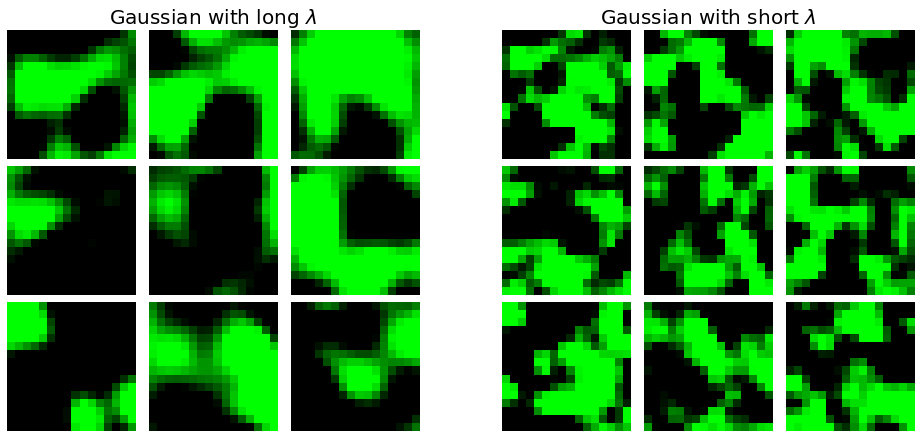

In [27]:
fig = plt.figure(constrained_layout=False, figsize=(14, 10))
outergrid = fig.add_gridspec(1, 2, left=0.05, right=0.95, wspace=0.2)
nsnaps = 3  # sqrt(Number of snapshots) to show from each dataset
center_idx = nsnaps // 2

#snap_tensors = [train_gaussian1, train_gaussian2, train_exp, train_rand]
#labels = ["Gaussian with long "+r"$\lambda$", "Gaussian with short "+r"$\lambda$", "Exponential", "Random"]
snap_tensors = [train_gaussian1, train_gaussian2]
labels = ["Gaussian with long "+r"$\lambda$", "Gaussian with short "+r"$\lambda$"]

"""Converts our snapshots to `images` which matplotlib can plot easily"""
def convert_image(snaps):
    # Add dummy red and blue channels
    snaps = np.stack((np.zeros_like(snaps[0]), snaps[0], np.zeros_like(snaps[0])))
    # Transpose to matplotlib image format
    img = snaps.transpose((1, 2, 0))
    return img 

for n, (snapset, label) in enumerate(zip(snap_tensors, labels)):
    #innergrid = outergrid[0, n].subgridspec(nsnaps, nsnaps, wspace=0.10, hspace=-0.75)
    innergrid = outergrid[0, n].subgridspec(nsnaps, nsnaps, wspace=0.10, hspace=-0.5)
    for i in range(nsnaps):
        for j in range(nsnaps):
            snap = snapset[nsnaps * i + j]
            img = convert_image(snap)
            
            ax = fig.add_subplot(innergrid[i, j])
            ax.axis('off')
            ax.imshow(img)
            
            if i == 0 and j == center_idx:
                ax.set_title(label, fontsize=20)

plt.show()

## CCNN Architecture

Below, we'll define the "simplest" CCNN architecture. 

The CCNN is a variation of the CNN, which slightly tweaks the nonlinear operation step to extract various orders of correlators out of a convolution. One way to understand these operations is as "nonlinear convolutions" which couple different numbers of pixels, defined by the operations:

$$ C_\alpha^{(1)}(\vec{x}) = \sum_{\vec{a}_1, k_1} f_{\alpha, k_1}(\vec{a}_1) S_{k_1}(\vec{x} + \vec{a}_1)$$
$$ C_\alpha^{(2)}(\vec{x}) = \sum_{(\vec{a}_1, k_1) \ne (\vec{a}_2, k_2)} f_{\alpha, k_1}(\vec{a}_1) f_{\alpha, k_2}(\vec{a}_2) S_{k_1}(\vec{x} + \vec{a}_1) S_{k_2}(\vec{x} + \vec{a}_2)$$

$$ \vdots $$

$$ C_\alpha^{(N)}(\vec{x}) = \sum_{(\vec{a}_1, k_1) \ne \dots \ne (\vec{a}_N, k_N)} \prod_{j=1}^N f_{\alpha, k_j}(\vec{a}_j) S_{k_j}(\vec{x} + \vec{a}_j)$$

Note that $C^{(1)}$ is the standard convolution as explained in the previous section. Each higher $C^{(n)}$, in expectation, measures a weighted sum of $n$-point correlators, where the weight on each correlator is equal to the product of the filter weights which make up that correlator's pattern.

Note that each of the sums are restricted such that terms where the same index pair $(\vec{a}_j, k_j)$ is not selected twice. This is to make interpretation easier down the line, as this way when interpreting what $C^{(n)}$ measures, one only needs to pick out the $n$-pixel patterns from the convolutional filter. Without this restriction, since $S$ only takes on values $\{0, 1\}$, it would be necessary to inspect all patterns in the filter with $\le n$ pixels, which would be a hassle!

However, this restriction also makes the sums difficult to compute naively. Luckily, one can show a nice recursive formula:

$$ C_\alpha^{(n)}(\vec{x}) = \frac{1}{n}\sum_{l=1}^n (-1)^{l-1} \left(\sum_{\vec{a}, k} f_{\alpha, k}(\vec{a})^l S_k(\vec{x} + \vec{a})^l \right) C_\alpha^{(n-l)}(\vec{x}) $$

Where all powers shown are done pixelwise. Using this, we can compute "correlator maps" up to $C^{(N)}$ in time $\mathcal{O}(N^2)$. This equation provides an alternate way to understand the nonlinear operation, as a modification of the function $\sigma$ to be a set of *polynomials* where the coefficients are carefully chosen to cancel out lower-order correlators.

Following this, there are just a few more components to the CCNN, as seen in the figure below, and explained afterwards. (**NOTE**: The figure below is working with 3-channel snapshots, with an additional channel containing information about the locations of holes in doped system. The model we will be building will work with 2-channel snapshots (learning 2-channel filters), since all of our test systems are "half-filled".)

![CCNN Architecture](arch.png)

If we know ahead of time that the pixel/site statistics are translation-invariant in our image, then we may as well take spatial averages of our correlator maps to produce:

$$c_\alpha^{(n)} = \frac{1}{N_{\text{sites}}} \sum_{\vec{x}} C_\alpha^{(n)}(\vec{x})$$

We'd then like to use these average correlations to distinguish the snapshots. Practically speaking, it is helpful to normalize each of these to zero mean and unit variance before using them in a classifier. Since the weights are constantly updating, this is difficult to do, but can be achieved on the batch scale using a [Batch Normalization](https://arxiv.org/abs/1502.03167v3) layer. (These are typically used as a "trick" in deep networks to speed up training, but here is important because the scales of each $c^{(n)}$ are so different, which isn't good for classification. It will also be important later in the interpretation stage.). 

What this layer does is simply normalize the features created from each *batch* of examples to have zero mean and unit variance within the batch.

Following this, we just use these features as inputs to a logistic classifier. If you are familiar with neural networks, this is really just a fully connected layer, followed by the `softmax` operation. We will label the learned weights coupling each $c_\alpha^{(n)}$ to the output as $\beta_\alpha^{(n)}$, and the final output of the neural network is:

$$\hat{y} = \frac{1}{1+ e^{-\vec{\beta}\cdot\vec{c} + \epsilon}}$$
where $\epsilon$ is a trainable bias parameter.

With all this in mind, lets construct a CCNN!

In [6]:
def _vflip(arr):
    return torch.flip(arr, [-2])


def _hflip(arr):
    return torch.flip(arr, [-1])


def _rot(arr, k):
    return torch.rot90(arr, k, [-2, -1])

In [7]:
## Modules used for performing symmetrization

class SymSlice(nn.Module):
    def __init__(self):
        super().__init__()

    """ Given an array of shape [B, ..., W, H], produces an array of shape [B, 8, ..., W, H]
          of all symmetry transformations of the input, then folds the symmetry-equivalent versions
          into the batch dimension to make an array of shape [B * 8, ..., W, H]
    """
    
    """
    def forward(self, x):
        batch_size = x.shape[0]
        sym_x = torch.empty(batch_size, 8, *x.shape[1:]).to(x)
        sym_x[:, 0] = x
        sym_x[:, 1] = _hflip(x)
        sym_x[:, 2] = _vflip(x)
        sym_x[:, 3] = _rot(x, 1)
        sym_x[:, 4] = _rot(x, 2)
        sym_x[:, 5] = _rot(x, 3)
        sym_x[:, 6] = _rot(_hflip(x), 1)
        sym_x[:, 7] = _rot(_vflip(x), 1)
        x = sym_x.reshape(batch_size * 8, *x.shape[1:])
        return x
    """

    # rotation over k*90 degree k belongs to {0,1,2,3}
    def forward(self, x):
        batch_size = x.shape[0]
        sym_x = torch.empty(batch_size, 4, *x.shape[1:]).to(x)
        sym_x[:, 0] = x
        sym_x[:, 1] = _rot(x, 1)
        sym_x[:, 2] = _rot(x, 2)
        sym_x[:, 3] = _rot(x, 3)
        x = sym_x.reshape(batch_size * 4, *x.shape[1:])
        return x

class SymPool(nn.Module):
    
    def __init__(self):
        super().__init__()
    
    """ Performs inverse symmetry operations to bring feature maps back in line, then
        averages activations pixelwise. Must operate on a feature map that has been through
        SymSlice.
    
    def __init__(self, reduction='mean'):
        if reduction == 'mean':
            self.reduction = lambda x: torch.sum(x, dim=1)
        elif reduction == 'max':
            self.reduction = lambda x: torch.max(x, dim=1)[0]
        else:
            raise ValueError("Unknown reduction method passed to SymPool")
        super().__init__()
    """

    """
    def forward(self, x):
        inv_x = torch.empty(x.shape[0] // 8, 8, *x.shape[1:], device=x.device)
        x = x.reshape(x.shape[0] // 8, 8, *x.shape[1:])

        inv_x[:, 0] = x[:, 0]
        inv_x[:, 1] = _hflip(x[:, 1])
        inv_x[:, 2] = _vflip(x[:, 2])
        inv_x[:, 3] = _rot(x[:, 3], -1)
        inv_x[:, 4] = _rot(x[:, 4], -2)
        inv_x[:, 5] = _rot(x[:, 5], -3)
        inv_x[:, 6] = _hflip(_rot(x[:, 6], -1))
        inv_x[:, 7] = _vflip(_rot(x[:, 7], -1))
        return torch.sum(inv_x, dim=1)/8
    """

    # inverse rotation over k*90 degree k belongs to {0,1,2,3}
    def forward(self, x):
        inv_x = torch.empty(x.shape[0] // 4, 4, *x.shape[1:], device=x.device)
        x = x.reshape(x.shape[0] // 4, 4, *x.shape[1:])

        inv_x[:, 0] = x[:, 0]
        inv_x[:, 1] = _rot(x[:, 1], -1)
        inv_x[:, 2] = _rot(x[:, 2], -2)
        inv_x[:, 3] = _rot(x[:, 3], -3)
        return torch.sum(inv_x, dim=1)/4

In [2]:
bandlimit = 6
gspace = escnn.gspaces.rot2dOnR2(N=-1, maximum_frequency=bandlimit)
#gspace = escnn.gspaces.rot2dOnR2(N=4)

In [3]:
""" Implements the non-linear convolution operation using the recursive formula."""
class NonlinearConv(nn.Module):
    def __init__(self, in_channels, num_filts, filter_size, order):
        super().__init__()
        self.order = order
        self.in_channels = in_channels
        self.num_filts = num_filts
        self.filter_size = filter_size

        """
        # Initialize filter similar as to how Pytorch initializes nn.Conv2d, but all positive
        weight_sample_k = 1.0 / np.sqrt(filter_size**2 * in_channels)
        init_filt = (2 * weight_sample_k * torch.rand(num_filts, in_channels, filter_size, filter_size, dtype=torch.float32))
        self.conv_filt = torch.nn.Parameter(init_filt)
        # Initialize some slices of the filter to be 0
        with torch.no_grad():
            self.conv_filt[:, :, int(self.filter_size/2)-2:int(self.filter_size/2)+3, int(self.filter_size/2)-2:int(self.filter_size/2)+3]=0.0
        """
        
        # Initialize the escnn filter
        #feat_type_in = escnn.nn.FieldType(gspace, self.in_channels*[gspace.irrep(0)])
        #feat_type_out = escnn.nn.FieldType(gspace, self.num_filts*[gspace.irrep(0)])
        #self.conv = escnn.nn.R2Conv(in_type=feat_type_in, out_type=feat_type_out, bias=False, kernel_size=self.filter_size, padding=int((self.filter_size-1)/2.0)) 
        
        feat_type_in = escnn.nn.FieldType(gspace, self.in_channels*[gspace.trivial_repr])
        feat_type_out = escnn.nn.FieldType(gspace, self.num_filts*[gspace.trivial_repr])
        self.conv = escnn.nn.R2Conv(in_type=feat_type_in, out_type=feat_type_out, bias=False, kernel_size=self.filter_size) 
        #with torch.no_grad():
        #    self.conv.weights[:3] = 0.0
        
        
    def forward(self, x):
        # We will work with strictly positive filters for easier interpretation!
        self.abs_filt = self.conv.expand_parameters()[0].abs()
        #abs_filt = self.conv_filt.abs()
        
        # Add a line here to force the central pixels to be 0 (scale cut)
        #self.abs_filt[:, :, int(self.filter.size/2)-2:int(self.filter.size/2)+2, int(self.filter.size/2)-2:int(self.filter.size/2)+2]=0.0
        
        # Convolutions of powers of the input with powers of the absolute valued filter
        conv_powers = [F.conv2d(x ** k, self.abs_filt ** k, stride=1, padding=int((self.filter_size-1)/2.0)) for k in range(1, self.order + 1)]
        #conv_powers = [F.conv2d(x ** k, abs_filt ** k, stride=1, padding=int((self.filter_size-1)/2.0)) for k in range(1, self.order + 1)]

        # C_0 is defined to be one everywhere
        corrs = [torch.ones_like(conv_powers[0])]

        # Compute each order of C_n recursively
        for n in range(1, self.order + 1):
            Cn = torch.zeros_like(conv_powers[0])
            for k in range(n):
                Cn += (-1) ** k * conv_powers[k] * corrs[n - k - 1]
            Cn /= n
            corrs.append(Cn)

        # Stack correlator maps along the channel dimension, dropping the zeroth order (C_0)
        # Here the channel dimension refers to the number of channels
        return torch.cat(corrs[1:], dim=-3)

In [4]:
""" Return the same input """
class Identity(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return x

In [5]:
""" Does a simple average over the last two dimensions of the input."""
class Mean2d(nn.Module):
    def __init__(self):
        super().__init__()
        
    def forward(self, x):
        return x.mean((-2, -1))
        #return torch.abs(x.mean((-2, -1)))

In [6]:
class probability_concatenation(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return torch.cat((x, torch.zeros_like(x)), dim=-1)

In [7]:
""" The full CCNN is Input -> NonlinearConv -> Spatial Avg -> BatchNorm -> Logistic. The way it is constructed
    here assumes a binary classification task, but this can be extended to the multiclass case."""
class CCNN(nn.Module):
    def __init__(self, in_channels, num_filts, filter_size, order, absbeta=False, slice=False, pool=False):
        super().__init__()
        self.in_channels = in_channels
        self.num_filts = num_filts
        self.filter_size = filter_size
        self.order = order
        self.absbeta = absbeta
        
        """
        self.slice = slice
        self.pool = pool
        self.symslice = SymSlice()
        self.identity = Identity()
        self.sympool = SymPool()

        if self.slice:
            self.symslice = SymSlice()
        else:
            self.symslice = Identity()
        
        self.corr_conv = NonlinearConv(in_channels, num_filts, filter_size, order)
        
        if self.pool:
            self.sympool = SymPool()
        else:
            self.sympool = Identity()
        
        self.spatial_mean = Mean2d()
        self.bn = nn.BatchNorm1d(num_filts * order, affine=True, eps=3.185289e-35, dtype=torch.float32)
        self.logistic_fc = nn.Linear(num_filts * order, 1, dtype=torch.float32)
        self.concat = probability_concatenation()
        """

        
        # the model architecture with escnn
        self.corr_conv = NonlinearConv(self.in_channels, self.num_filts, self.filter_size, self.order)
        self.spatial_mean = Mean2d()
        self.bn = nn.BatchNorm1d(num_filts * order, affine=True, eps=3.185289e-35, dtype=torch.float32)
        self.logistic_fc = nn.Linear(num_filts * order, 1, dtype=torch.float32)
        # If absbeta is set, force the beta_alpha^(n) parameters to be strictly positive
        # The effect of this is that the model can only pick up features which "give evidence for" class A
        self.concat = probability_concatenation()
        
    
    
    def forward(self, x, chop=False):    
        
        
        x = self.corr_conv(x)
        x = self.spatial_mean(x)
        if chop == False:
            x = self.bn(x)
            x = self.logistic_fc(x)
            if self.absbeta:
                self.logistic_fc.weight.data.abs_()
            # Treat the output as if logit 0 has the value predicted by model, logit 1 has logit 0
            x = self.concat(x)

        return x
        
        
        """
        if (self.slice & self.pool):
            x = self.symslice(x)
            x = self.corr_conv(x)
            x = self.sympool(x)
            x = self.spatial_mean(x)
        else:
            x = self.identity(x)
            x = self.corr_conv(x)
            x = self.identity(x)
            x = self.spatial_mean(x)
            
            if chop == False:
                x = self.bn(x)
                x = self.logistic_fc(x)
                if self.absbeta:
                    self.logistic_fc.weight.data.abs_()
                # Treat the output as if logit 0 has the value predicted by model, logit 1 has logit 0
                x = self.concat(x)
        
        return x
        """

In [14]:
print('before optimizer step')
for param in ccnn.parameters():
    print(param)

before optimizer step
Parameter containing:
tensor([ 0.0000,  0.0000,  0.0000,  0.2009,  0.0524, -0.0487], device='cuda:0',
       requires_grad=True)
Parameter containing:
tensor([1., 1., 1., 1.], device='cuda:0', requires_grad=True)
Parameter containing:
tensor([0., 0., 0., 0.], device='cuda:0', requires_grad=True)
Parameter containing:
tensor([[-0.3046, -0.4874, -0.4313, -0.3816]], device='cuda:0',
       requires_grad=True)
Parameter containing:
tensor([0.1844], device='cuda:0', requires_grad=True)


In [18]:
print('after optimizer step')
for param in ccnn.parameters():
    print(param)

after optimizer step
Parameter containing:
tensor([ 0.0000,  0.0000,  0.0000, -0.0490,  0.0102, -0.0017], device='cuda:0',
       requires_grad=True)
Parameter containing:
tensor([ 2.4612,  1.1673,  3.1465, -0.0217], device='cuda:0',
       requires_grad=True)
Parameter containing:
tensor([-0.3371,  0.0406,  0.5726, -0.0214], device='cuda:0',
       requires_grad=True)
Parameter containing:
tensor([[ 1.7621e+00,  5.7372e-01, -1.8875e+00, -5.4311e-05]], device='cuda:0',
       requires_grad=True)
Parameter containing:
tensor([1.5609], device='cuda:0', requires_grad=True)


In [65]:
ccnn.corr_conv.conv.basisexpansion.get_element_info(5)

{'irrep:frequency': 0,
 'irrep:flip_frequency': 0,
 'radius': 5.0,
 'sigma': 0.4000000059604645,
 'idx': 5,
 'radial_idx': 5,
 'j': (0, 0),
 'shape': (1, 1),
 '_j': (0,),
 'i': 5,
 't': 0,
 's': 0,
 'k': 0,
 'in_irrep': (0,),
 'out_irrep': (0,),
 'in_irrep_idx': 0,
 'out_irrep_idx': 0,
 'j_idx': 5,
 'irreps_basis_idx': 5,
 'id': 5,
 'in_irreps_position': 0,
 'out_irreps_position': 0,
 'in_repr': 'irrep_0',
 'out_repr': 'irrep_0',
 'in_field_position': 0,
 'out_field_position': 0,
 'block_id': 5}

### Read in the optimized hyperparameter file

In [13]:
import pandas as pd
import pickle
import optuna
from optuna.trial import TrialState

In [14]:
#df = pd.read_csv('optuna_ccnn/optuna_results_gaussian_lognormal_t17_z16_only/optuna_results_1_channel_1_filter_gaussian_vs_lognormal_t17_cosmology_4by4_deg_120by120_pixels_order4_gnom_projection.csv')
df = pd.read_csv('optuna_ccnn/optuna_results_gaussian_lognormal_t17_z16_only/optuna_results_1_channel_1_filter_31pix_gaussian_vs_lognormal_2.5e3maps_t17_cosmology_10by10_deg_100by100_pixels_order4_symmetrization.csv')
print(df.to_string()) 

    number     value  params_lr  params_lr_scheduler_ratio params_optimizer  params_regularization_gamma
0        0  0.480501   0.000852                   0.119330             Adam                     0.032736
1        4  0.502017   0.291834                   0.023159              SGD                     0.001588
2        2  0.513832   0.029263                   0.011507              SGD                     3.038178
3        6  0.515305   0.000743                   0.056003              SGD                     0.004660
4        1  0.565318   0.039949                   0.014249          RMSprop                     0.003619
5       23  0.780546   0.081172                   0.157759          RMSprop                     0.001119
6        3  0.839940   0.015880                   0.480776          RMSprop                     2.409064
7       25  0.918993   0.321963                   0.359176          RMSprop                     0.010697
8        8  0.927766   0.346486                   0.396

In [14]:
with open('optuna_ccnn/study_saves/ccnn_study_gstools_1_channel_1_filter_31pix_gaussiancov_3e3maps_lambda5_vs_20_120_pixels_order4_escnn.pickle', 'rb') as f:
    study = pickle.load(f)

pruned_trials = study.get_trials(deepcopy=False, states=[TrialState.PRUNED])
complete_trials = study.get_trials(deepcopy=False, states=[TrialState.COMPLETE])

print("\nStudy statistics: ")
print("  Number of finished trials: ", len(study.trials))
print("  Number of pruned trials: ", len(pruned_trials))
print("  Number of complete trials: ", len(complete_trials))

trial = study.best_trial
print("Best trial:")
print("  Value: ", trial.value)
print("  Params: ")
for key, value in trial.params.items():
    print("    {}: {}".format(key, value))


Study statistics: 
  Number of finished trials:  20
  Number of pruned trials:  12
  Number of complete trials:  8
Best trial:
  Value:  0.99609375
  Params: 
    regularization_gamma: 2.3300966898335855
    lr_scheduler_ratio: 0.01848372420974575
    optimizer: Adam
    lr: 0.4694582469995233


In [13]:
#=== 1) Create SRF DataLoaders ===#

train_loader, val_loader = make_datasets(train_gaussian, train_log, val_gaussian, val_log)
#train_loader, val_loader = make_datasets(train_nus00, train_nus01, val_nus00, val_nus01)
#train_loader, val_loader = make_datasets(train_grf_s, train_grf_l, val_grf_s, val_grf_l)
#train_loader, val_loader = make_datasets(train_log_lambda1, train_log_lambda2, val_log_lambda1, val_log_lambda2)
#train_loader, val_loader = make_datasets(train_no_IA, train_IA_Aamp, val_no_IA, val_IA_Aamp)
#train_loader, val_loader = make_datasets(train_omega_p, train_omega_m, val_omega_p, val_omega_m)
#train_loader, val_loader = make_datasets(train_w0_p, train_w0_m, val_w0_p, val_w0_m)

In [17]:
#=== 2) Set up some things for training ===#
# Number of times the model will see the full dataset
epochs = 5
# The initial learning rate -- an important hyperparameter
lr = 0.505631 
#lr = 0.5
# The strength of the regularization loss -- we can make this very strong in these easy toy examples
gamma = 0.030383
#gamma = 5e-4
# The number of input channels 
in_channels = 1
# The number of filters to learn in our model
num_filts = 1
# The spatial length of the filters
filter_size = 11
# The highest order of correlation measured
order = 4
# Make our model -- for simplicity, let's train a two-filter model
ccnn = CCNN(in_channels=in_channels, num_filts=num_filts, filter_size=filter_size, order=order, absbeta=False).to(device=device)

# The optimizer
#optimizer = torch.optim.Adam(ccnn.parameters(), lr=lr)
optimizer = torch.optim.RMSprop(ccnn.parameters(), lr=lr)
#optimizer = torch.optim.SGD(ccnn.parameters(), lr=lr)

# A learning schedule which will ramp down the learning rate as we train
lr_scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, 0.067646)
# Our loss function
criterion = nn.CrossEntropyLoss()

In [14]:
"""Performs one training epoch, feeding an entire DataLoader through a model,
   performing gradient descent and keeping track of the average loss and accuracy."""
def train(model, optimizer, criterion, loader, gamma, device='cuda'):
    model.train()
    loss_total = 0.0
    accuracy_total = 0.0
    for inputs, labels in loader:
        # Zero out gradients from the previous iteration
        optimizer.zero_grad()
        
        # Send the inputs and outputs to the GPU (if using one)
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Feed the input through the network, measure the loss
        pred = model(inputs)
        loss = criterion(pred, labels)
        
        # Add our regularization loss on the filter weights
        #l1_loss = model.corr_conv.conv_filt.norm(1)
        l1_loss = model.corr_conv.conv.expand_parameters()[0].norm(1)
        #l1_loss = model.corr_conv.abs_filt.norm(1)
        loss += gamma * l1_loss

        # Backprop gradients
        loss.backward()

        """
        # fix the gradient of the pixels within the scale cut
        for i, param in enumerate(model.parameters()):
            if i == 0:
                param.grad[:3] = torch.zeros_like(param.grad[:1])
                #param.grad[:,:,int(model.filter_size/2)-2:int(model.filter_size/2)+3, int(model.filter_size/2)-2:int(model.filter_size/2)+3] = torch.zeros_like(param.grad[:,:,int(model.filter_size/2)-2:int(model.filter_size/2)+3, int(model.filter_size/2)-2:int(model.filter_size/2)+3])
        """
        
        # Update model parameters by one gradient descent step
        optimizer.step()

        # Do some bookkeeping of the current loss and accuracy
        loss_total += loss.item()
        pred_classes = pred.argmax(dim=1).cpu()
        labels = labels.cpu()
        accuracy_total += torch.count_nonzero(pred_classes == labels).item() / len(pred_classes)

    avg_loss = loss_total / len(loader)
    avg_acc = accuracy_total / len(loader)
    return avg_loss, avg_acc

In [15]:
"""Performs one validation epoch, feeding an entire DataLoader through a model, and
   calculating the average loss and accuracy."""
def val(model, criterion, loader, gamma, device='cuda'):
    model.eval()
    loss_total = 0.0
    accuracy_total = 0.0
    
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            pred = model(inputs)
            loss = criterion(pred, labels)

            #l1_loss = model.corr_conv.conv_filt.norm(1)
            l1_loss = model.corr_conv.conv.expand_parameters()[0].norm(1)
            #l1_loss = model.corr_conv.abs_filt.norm(1)
            loss += gamma * l1_loss

            loss_total += loss.item()
            pred_classes = pred.argmax(dim=1).cpu()
            labels = labels.cpu()
            accuracy_total += torch.count_nonzero(pred_classes == labels).item() / len(pred_classes)
            
    avg_loss = loss_total / len(loader)
    avg_acc = accuracy_total / len(loader)
    return avg_loss, avg_acc

In [18]:
#=== 3) The main training loop! ===#
# Some lists to keep track of losses and accuracies
train_losses, val_losses = [], []
train_accs, val_accs = [], []
for epoch in tqdm(range(epochs), desc="Epoch"):
    # Train
    train_loss, train_acc = train(
        ccnn, optimizer, criterion, train_loader,
        gamma=gamma, device=device
    )
    train_losses.append(train_loss)
    train_accs.append(train_acc)

    # Val
    val_loss, val_acc = val(
        ccnn, criterion, val_loader,
        gamma=gamma, device=device
    )
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    
    # Step the learning rate schedule
    lr_scheduler.step()

Epoch: 100%|██████████████████████████████████████████████████████████| 5/5 [01:21<00:00, 16.32s/it]


In [55]:
#torch.save(ccnn, 'trained_model/ccnn_gaussian_lognormal_classification_1_filter_t17_cosmo_zs16_4deg_120pixels_order4_hypertuned.pt')
torch.save(ccnn, 'trained_model/gstools/ccnn_gstools_gaussiancov_lambda10_vs_20_1_channel_1_filter_classification_120pixels_order4_hypertuned.pt')

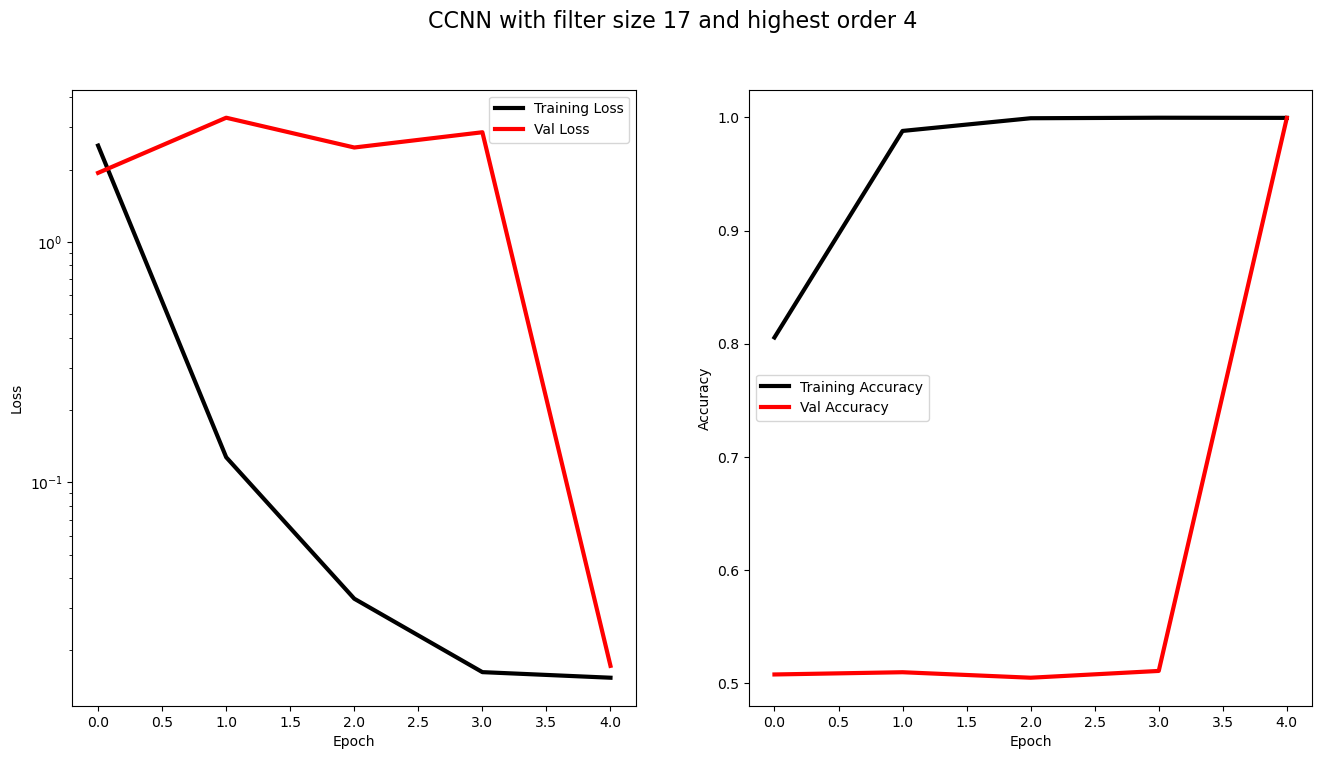

In [36]:
fig, axs = plt.subplots(1, 2, figsize=(16, 8))

# Plot the losses
axs[0].plot(np.arange(epochs), train_losses, lw=3, color='k', label="Training Loss")
axs[0].plot(np.arange(epochs), val_losses, lw=3, color='r', label="Val Loss")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Loss")
#axs[0].set_xscale('log')
axs[0].set_yscale('log')
axs[0].legend()
# Plot the accuracies
axs[1].plot(np.arange(epochs), train_accs, lw=3, color='k', label="Training Accuracy")
axs[1].plot(np.arange(epochs), val_accs, lw=3, color='r', label="Val Accuracy")
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Accuracy")
#axs[1].set_xscale('log')
axs[1].legend()
fig.suptitle("CCNN with filter size 17 and highest order 4", fontsize=16.0)
plt.show()

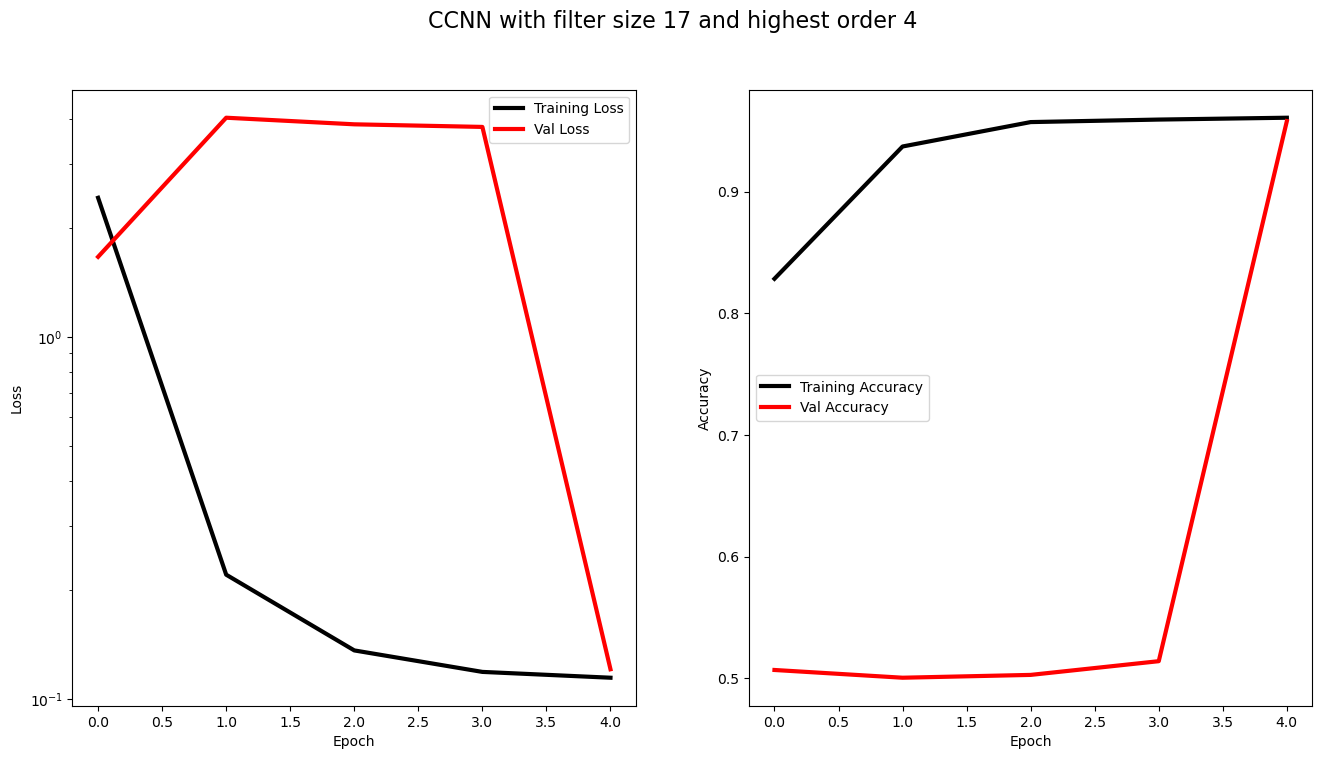

In [46]:
fig, axs = plt.subplots(1, 2, figsize=(16, 8))

# Plot the losses
axs[0].plot(np.arange(epochs), train_losses, lw=3, color='k', label="Training Loss")
axs[0].plot(np.arange(epochs), val_losses, lw=3, color='r', label="Val Loss")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Loss")
#axs[0].set_xscale('log')
axs[0].set_yscale('log')
axs[0].legend()
# Plot the accuracies
axs[1].plot(np.arange(epochs), train_accs, lw=3, color='k', label="Training Accuracy")
axs[1].plot(np.arange(epochs), val_accs, lw=3, color='r', label="Val Accuracy")
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Accuracy")
#axs[1].set_xscale('log')
axs[1].legend()
fig.suptitle("CCNN with filter size 17 and highest order 4", fontsize=16.0)
plt.show()

For the classification task of two GRF data set with different correlation length, increasing the filter size from 3 to 5 can boost up the final validation accuracy by approximately $10\%$. However, increasing the filter size from 5 to 9 will not improve the validation and training accuracy.

### Load the pre-trained model

In [8]:
ccnn = CCNN(in_channels=1, num_filts=1, filter_size=31, order=4)

ccnn.load_state_dict(torch.load('trained_model/gstools/ccnn_gstools_gaussiancov_3e3maps_1_channel_1_filter_31pix_classification_120pixels_order4_hypertuned_escnn.pt'))
ccnn.eval()
ccnn = ccnn.to(device=device)

#ccnn_filter_l = CCNN(in_channels=1, num_filts=1, filter_size=51, order=4)
#ccnn_filter_s = CCNN(in_channels=1, num_filts=1, filter_size=11, order=4)

#ccnn_filter_l.load_state_dict(torch.load('trained_model/flask/ccnn_gaussian_lognormal_3e3maps_1_channel_1_filter_51pix_classification_t17_cosmo_zs16_20deg_200pixels_order4_hyperfrom31pix_symmetrization.pt'))
#ccnn_filter_l.eval()
#ccnn_filter_l = ccnn_filter_l.to(device=device)

#ccnn_filter_s.load_state_dict(torch.load('trained_model/flask/ccnn_gaussian_lognormal_3e3maps_1_channel_1_filter_11pix_classification_t17_cosmo_zs16_20deg_200pixels_order4_hyperfrom31pix_symmetrization.pt'))
#ccnn_filter_s.eval()
#ccnn_filter_s = ccnn_filter_s.to(device=device)

In [42]:
#filters = ccnn.corr_conv.conv_filt.data.abs().detach().cpu().numpy()
filters = ccnn.corr_conv.conv.expand_parameters()[0].abs().detach().cpu().numpy()
#filters[0, 0, 15, 15] = 0.008
print(filters.shape)

(1, 1, 31, 31)


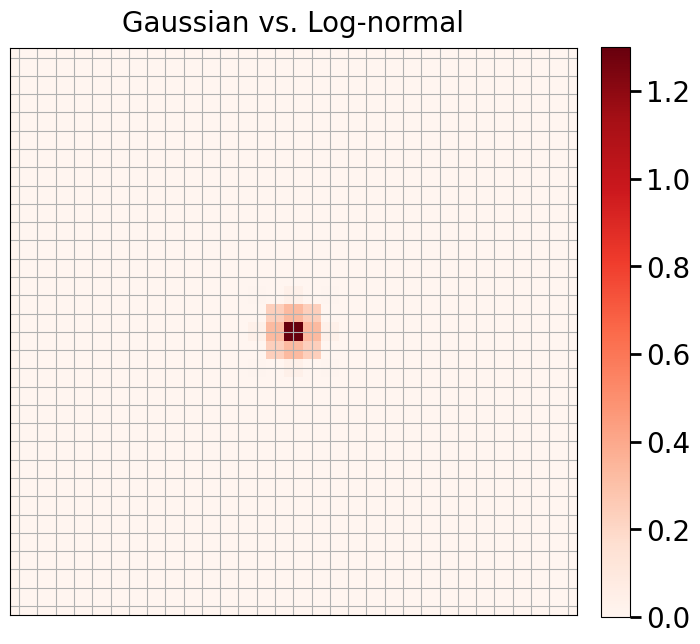

In [12]:
import matplotlib.ticker as plticker
filter = filters[0,0]
vmin = filter.min()
vmax = filter.max()
fig, ax = plt.subplots(figsize=(8,8))
myInterval=1
loc = plticker.MultipleLocator(base=myInterval)
ax.xaxis.set_major_locator(loc)
ax.yaxis.set_major_locator(loc)
# Add the grid
ax.grid(which='major', axis='both', linestyle='-')
ax.tick_params(bottom=False, labelbottom=False, left=False, labelleft=False)
imag = ax.imshow(filter, cmap="Reds", vmin=vmin, vmax=vmax, norm='linear')
ax.set_title('Gaussian vs. Log-normal', fontsize=20, pad=12.0)
cbar = fig.colorbar(imag, ax=ax, fraction=0.046, pad=0.04)
#cbar = fig.colorbar(imag, ax=ax, fraction=0.046, pad=0.04, ticks=[0.0, 2e-3, 4e-3, 6e-3, 8e-3, 0.01])
tick_font_size = 20
cbar.ax.tick_params(labelsize=tick_font_size, length=8.0, width=2.0)
plt.savefig('paper_plot/grf_lognormal_filter_analysis.pdf', format='pdf', dpi=300, bbox_inches='tight')

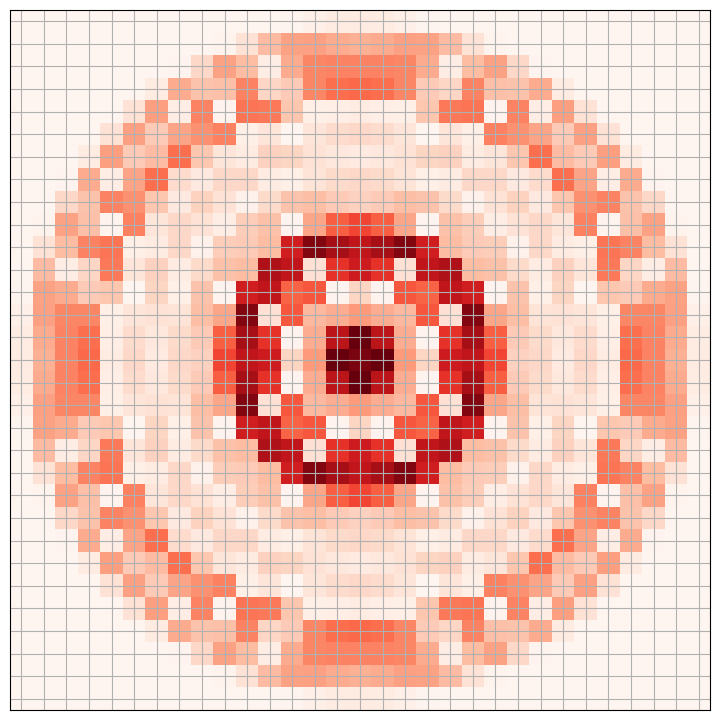

In [27]:
import matplotlib.ticker as plticker
n_filter = filters.shape[0]
n_chan = filters.shape[1]
fig = plt.figure(constrained_layout=False, figsize=(20, 20))
outergrid = fig.add_gridspec(n_chan, n_filter, left=0.05, right=0.55, wspace=0.05)
#== Plotting code ==#
# Make sure that all filters are plotted on the same colorscale
vmin = filters.min()
vmax = filters.max()
chan_cmaps = ['Reds', 'Blues']
#chan_cmaps = ['Blues', 'Reds']
#chan_labels = ['zs10', 'zs16']
for n in range(n_filter):
    filtgrid = outergrid[0, n].subgridspec(2, 1, wspace=0.1)
    for chan in range(n_chan):
        ax = fig.add_subplot(filtgrid[chan, 0])
        #if chan == 0:
        #    ax.set_title("Filter " + str(n))
        myInterval=1
        loc = plticker.MultipleLocator(base=myInterval)
        ax.xaxis.set_major_locator(loc)
        ax.yaxis.set_major_locator(loc)
        # Add the grid
        ax.grid(which='major', axis='both', linestyle='-')
        ax.imshow(filters[n, chan], cmap=chan_cmaps[chan], vmin=vmin, vmax=vmax, norm='linear')
        #ax.imshow(filters[n, chan], vmin=vmin, vmax=vmax)
        ax.tick_params(
            bottom=False,
            labelbottom=False,
            left=False,
            labelleft=False,
        )
        #cbar = plt.colorbar()
        #tick_font_size = 12
        #cbar.ax.tick_params(labelsize=tick_font_size)
        #ax.set_ylabel(chan_labels[chan], rotation=90, fontsize=30)
#cbar_ax = fig.add_axes([0.85, 0.3, 0.05, 0.4])
#axes[0].grid(which='minor', color='w', linestyle='-', linewidth=2)
plt.show()
#plt.savefig('paper_plot/grf_lognormal_filter_analysis.pdf', format='pdf', dpi=300, bbox_inches='tight')

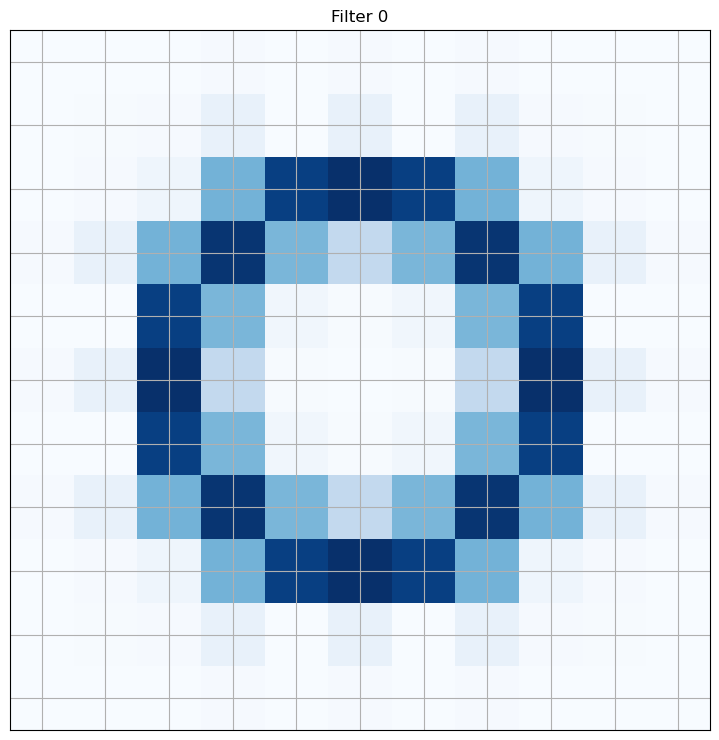

In [21]:
import matplotlib.ticker as plticker
n_filter = filters.shape[0]
n_chan = filters.shape[1]
fig = plt.figure(constrained_layout=False, figsize=(20, 20))
outergrid = fig.add_gridspec(n_chan, n_filter, left=0.05, right=0.55, wspace=0.05)
#== Plotting code ==#
# Make sure that all filters are plotted on the same colorscale
vmin = filters.min()
vmax = filters.max()
chan_cmaps = ['Blues', 'Reds', 'Greens', 'Greys']
#chan_labels = ['zs10', 'zs16']
for n in range(n_filter):
    filtgrid = outergrid[0, n].subgridspec(2, 1, wspace=0.1)
    for chan in range(n_chan):
        ax = fig.add_subplot(filtgrid[0, chan])
        if chan == 0:
            ax.set_title("Filter " + str(n))
        myInterval=1
        loc = plticker.MultipleLocator(base=myInterval)
        ax.xaxis.set_major_locator(loc)
        ax.yaxis.set_major_locator(loc)
        # Add the grid
        ax.grid(which='major', axis='both', linestyle='-')
        #log_norm = plt.Normalize(vmin=filters[n, chan].min(), vmax=filters[n, chan].max())
        #ax.imshow(filters[n, chan], cmap=chan_cmaps[chan], norm=log_norm)
        ax.imshow(filters[n, chan], cmap=chan_cmaps[chan], vmin=vmin, vmax=vmax)
        #ax.imshow(filters[n, chan], vmin=vmin, vmax=vmax)
        ax.tick_params(
            bottom=False,
            labelbottom=False,
            left=False,
            labelleft=False,
        )
        #ax.set_ylabel(chan_labels[chan], rotation=90, fontsize=30)
plt.show()

In [22]:
filters[:,:,5,:]

array([[[7.5202086e-05, 7.0850528e-04, 9.5579261e-03, 2.4883379e-03,
         3.8680104e-05, 3.7292779e-08, 3.8680104e-05, 2.4883379e-03,
         9.5579261e-03, 7.0850528e-04, 7.5202086e-05]]], dtype=float32)

In [35]:
filters[:,:,5,:]

array([[[8.0414861e-07, 5.0798451e-05, 1.2676288e-04, 3.2548339e-03,
         2.7683416e-02, 1.0651236e-01, 2.7683416e-02, 3.2548339e-03,
         1.2676288e-04, 5.0798451e-05, 8.0414861e-07]]], dtype=float32)

### Sort the filter numpy array by 2-point configurations

In [43]:
filter = filters[0,0]

In [44]:
x_index = np.linspace(0, filter.shape[0]-1, filter.shape[0])
y_index = np.linspace(0, filter.shape[1]-1, filter.shape[1])
x = np.array([])
y = np.array([])
#Specify (x,y) values for each pixel in the map
for i in range(filter.shape[1]):
    for j in range(filter.shape[0]):
        x = np.append(x, x_index[j]).reshape((-1,1))
        y = np.append(y, y_index[i]).reshape((-1,1))

In [45]:
xy = np.concatenate((x,y), axis=1)
pixel_comb = combinations(xy, 2)
pixel_comb = np.array(list(pixel_comb))

In [46]:
distance = []
for i in range(pixel_comb.shape[0]):
    #x_sep = abs((pixel_comb[i][1,0] - pixel_comb[i][0,0])*6.0)
    #y_sep = abs((pixel_comb[i][1,1] - pixel_comb[i][0,1])*6.0)

    x_sep = abs((pixel_comb[i][1,0] - pixel_comb[i][0,0]))
    y_sep = abs((pixel_comb[i][1,1] - pixel_comb[i][0,1]))
    sep = np.sqrt(x_sep**2 + y_sep**2)
    distance.append(sep)
distance = np.array(distance)

In [47]:
weights_multiplication = []
for i in range(pixel_comb.shape[0]):
    weight1 = filter[pixel_comb[i][0,0].astype(int), pixel_comb[i][0,1].astype(int)]
    weight2 = filter[pixel_comb[i][1,0].astype(int), pixel_comb[i][1,1].astype(int)]
    weight = weight1*weight2
    weights_multiplication.append(weight)
weights_multiplication = np.array(weights_multiplication)

In [48]:
idx_sort = np.argsort(distance)
sorted_distance = distance[idx_sort]
sep_vals, idx_start, count = np.unique(sorted_distance, return_counts=True, return_index=True)
res = np.split(idx_sort, idx_start[1:])

In [49]:
weights_sum = []
for i in range(sep_vals.shape[0]):
    sum = np.sum(weights_multiplication[res[i]])
    weights_sum.append(sum)
weights_sum = np.array(weights_sum)

In [50]:
print('The 2-point separation with the largest weight is %s arcmin with %s'%(sep_vals[np.where(weights_sum == weights_sum.max())[0][0]], weights_sum[np.where(weights_sum == weights_sum.max())[0][0]]))

The 2-point separation with the largest weight is 5.0 arcmin with 0.027923442


In [82]:
sep_vals[np.where(weights_sum >= 0.02)[0]]

array([ 5.        ,  8.06225775,  9.21954446, 12.04159458, 13.03840481])

In [64]:
indices = np.argsort(weights_sum, axis=0)[-3]
print(indices)

58


In [65]:
print(sep_vals[indices])
print(weights_sum[indices])

12.041594578792296
0.023405978


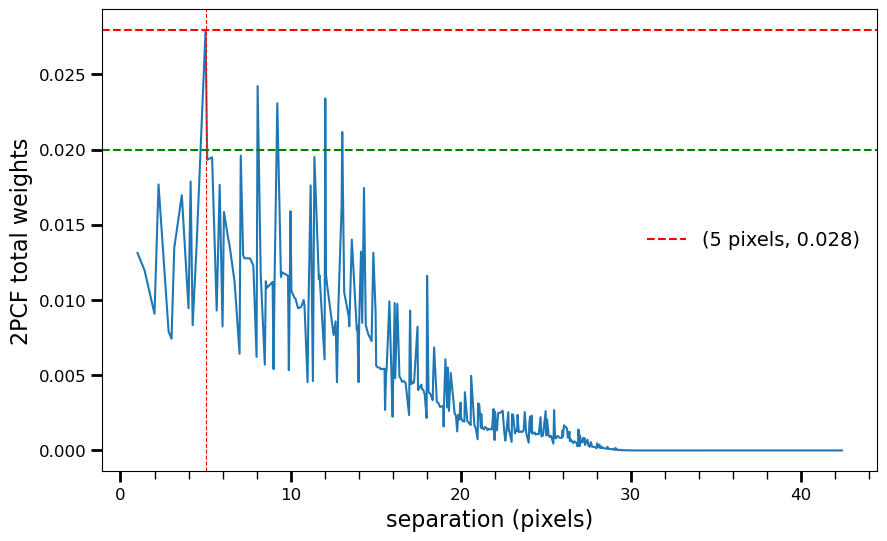

In [89]:
plt.figure(figsize=(10,6))
plt.plot(sep_vals, weights_sum)
plt.axhline(y = 0.027923442, color = 'r', linestyle = '--', label='(5 pixels, 0.028)')
plt.axvline(x = 5.0, color = 'r', linestyle = '--', lw=0.8)
plt.axhline(y = 0.02, color = 'g', linestyle = '--')
#plt.axhline(y = 0.024230652, color = 'g', linestyle = '--', label='(8.06 pixels, 0.024)') 
#plt.axhline(y = 0.023405978, color = 'orange', linestyle = '--', label='(12.04 pixels, 0.023)') 
plt.minorticks_on()
plt.tick_params(axis='both', which='major', labelsize=12, length=8.0, width=2.0)
plt.tick_params(axis='x', which='minor', labelsize=8, length=6.0, width=1.0)
plt.tick_params(axis='y', which='minor', labelsize=8, length=0.0, width=1.0)
plt.xlabel('separation (pixels)', fontsize=16)
plt.ylabel('2PCF total weights', fontsize=16)
plt.legend(frameon=False, fontsize=14)
plt.savefig('paper_plot/grf_total_weights_vs_separation.pdf', format='pdf', dpi=300, bbox_inches='tight')

#### 2-point correlation function from the filter and takahashi cosmology

In [33]:
Cl_zs16zs16 = np.loadtxt('/e/ocean1/users/ahalder/data/simulations/flask_Takahashi_noiseless_CCNN/flask_zs10_zs16_CCNN/Cl-f2z2f2z2.dat')

In [36]:
r = sep_vals
l1 = np.linspace(0, 9999, 10000)
corr_2pt = np.zeros((len(r), len(Cl_zs16zs16[0,:])))
corr_2pt[:,0] = r

for i in range(len(Cl_zs16zs16[0,:])-1):
    pk = Cl_zs16zs16[:,i+1]
    x = np.cos(np.radians(r * 1/60))
    coeff = (2 * l1 + 1) * pk/4/np.pi
    corr_2pt[:,i+1] = np.polynomial.legendre.legval(x, coeff)

In [37]:
from scipy import interpolate
f = interpolate.interp1d(r, corr_2pt[:,1], fill_value='extrapolate')

In [38]:
c2 = np.sum(weights_sum * corr_2pt[:,1])
c2

0.00024135541017168463

#### 2-point correlation function from GSTools

In [18]:
gs2pcf_lambda5 = np.load('gstool_compute_2pcf.npy')
gs2pcf_lambda20 = np.load('gstool_compute_2pcf_lambda20.npy')

In [19]:
c2_lambda5 = 0
c2_lambda20 = 0
for i in range(sep_vals.shape[0]):
    corr_2pcf_lambda5 = weights_sum[i]*gs2pcf_lambda5[i]
    corr_2pcf_lambda20 = weights_sum[i]*gs2pcf_lambda20[i]
    c2_lambda5 += corr_2pcf_lambda5
    c2_lambda20 += corr_2pcf_lambda20

In [21]:
c2_lambda20

1.0493100759181384

### Sort the filter numpy array by 4-point configuration

In [131]:
filter = filters[0,0]
xy = np.unravel_index(np.argsort(filter.ravel())[-208:], filter.shape)

In [132]:
xy = np.concatenate((xy[0].reshape(-1,1), xy[1].reshape(-1,1)), axis=1)

In [133]:
pixel_comb = combinations(xy, 4)
pixel_comb = np.array(list(pixel_comb))

In [134]:
d12 = np.sqrt(((pixel_comb[:, 1, 0] - pixel_comb[:, 0, 0])*6.0)**2 + ((pixel_comb[:, 1, 1] - pixel_comb[:, 0, 1])*6.0)**2).reshape((-1,1))
d13 = np.sqrt(((pixel_comb[:, 2, 0] - pixel_comb[:, 0, 0])*6.0)**2 + ((pixel_comb[:, 2, 1] - pixel_comb[:, 0, 1])*6.0)**2).reshape((-1,1))
d14 = np.sqrt(((pixel_comb[:, 3, 0] - pixel_comb[:, 0, 0])*6.0)**2 + ((pixel_comb[:, 3, 1] - pixel_comb[:, 0, 1])*6.0)**2).reshape((-1,1))
d23 = np.sqrt(((pixel_comb[:, 2, 0] - pixel_comb[:, 1, 0])*6.0)**2 + ((pixel_comb[:, 2, 1] - pixel_comb[:, 1, 1])*6.0)**2).reshape((-1,1))
d24 = np.sqrt(((pixel_comb[:, 3, 0] - pixel_comb[:, 1, 0])*6.0)**2 + ((pixel_comb[:, 3, 1] - pixel_comb[:, 1, 1])*6.0)**2).reshape((-1,1))
d34 = np.sqrt(((pixel_comb[:, 3, 0] - pixel_comb[:, 2, 0])*6.0)**2 + ((pixel_comb[:, 3, 1] - pixel_comb[:, 2, 1])*6.0)**2).reshape((-1,1))
side_length = np.concatenate((d12,d13,d14,d23,d24,d34), axis=1)
side_length = np.sort(side_length, axis=1)

In [135]:
weight1 = filter[pixel_comb[:, 0, 0].astype(int), pixel_comb[:, 0, 1].astype(int)]
weight2 = filter[pixel_comb[:, 1, 0].astype(int), pixel_comb[:, 1, 1].astype(int)]
weight3 = filter[pixel_comb[:, 2, 0].astype(int), pixel_comb[:, 2, 1].astype(int)]
weight4 = filter[pixel_comb[:, 3, 0].astype(int), pixel_comb[:, 3, 1].astype(int)]
weight = weight1*weight2*weight3*weight4

In [136]:
xi12 = f(side_length[:,0])
xi13 = f(side_length[:,1])
xi14 = f(side_length[:,2])
xi23 = f(side_length[:,3])
xi24 = f(side_length[:,4])
xi34 = f(side_length[:,5])
grf_4pcf = xi12*xi34 + xi13*xi24 + xi14*xi23

In [137]:
idx_sort = np.argsort(grf_4pcf)
sorted_grf_4pcf = grf_4pcf[idx_sort]
grf_4pcf_vals, idx_start, count = np.unique(sorted_grf_4pcf, return_counts=True, return_index=True)
res = np.split(idx_sort, idx_start[1:])

In [138]:
weights_sum = []
for i in range(grf_4pcf_vals.shape[0]):
    sum = np.sum(weight[res[i]])
    weights_sum.append(sum)
weights_sum = np.array(weights_sum)

In [139]:
c4 = np.sum(weights_sum * grf_4pcf_vals)
c4

1.3154672527495005e-08

In [142]:
lambda_zs16 = 0.0313
eta12 = (1/lambda_zs16**2)*xi12 + 1
eta13 = (1/lambda_zs16**2)*xi13 + 1
eta14 = (1/lambda_zs16**2)*xi14 + 1
eta23 = (1/lambda_zs16**2)*xi23 + 1
eta24 = (1/lambda_zs16**2)*xi24 + 1
eta34 = (1/lambda_zs16**2)*xi34 + 1

In [143]:
lognormal_4pcf = lambda_zs16**4 * (eta12*eta13*eta14*eta23*eta24*eta34 - eta12*eta13*eta23 - eta12*eta14*eta24 - eta13*eta14*eta34 - eta23*eta24*eta34 + eta12 + eta13 + eta14 + eta23 + eta24 + eta34 - 3)

In [144]:
idx_sort = np.argsort(lognormal_4pcf)
sorted_lognormal_4pcf = lognormal_4pcf[idx_sort]
lognormal_4pcf_vals, idx_start, count = np.unique(sorted_lognormal_4pcf, return_counts=True, return_index=True)
res = np.split(idx_sort, idx_start[1:])

In [145]:
weights_sum = []
for i in range(lognormal_4pcf_vals.shape[0]):
    sum = np.sum(weight[res[i]])
    weights_sum.append(sum)
weights_sum = np.array(weights_sum)

In [146]:
c4 = np.sum(weights_sum * lognormal_4pcf_vals)
c4

1.613021074561178e-08

### Sort the filter numpy array by 3-point configuration

In [13]:
filter = filters[0,0]
x_index = np.linspace(0, filter.shape[0]-1, filter.shape[0])
y_index = np.linspace(0, filter.shape[1]-1, filter.shape[1])
x = np.array([])
y = np.array([])
#Specify (x,y) values for each pixel in the map
for i in range(filter.shape[1]):
    for j in range(filter.shape[0]):
        x = np.append(x, x_index[j]).reshape((-1,1))
        y = np.append(y, y_index[i]).reshape((-1,1))

In [58]:
xy = np.concatenate((x,y), axis=1)
pixel_comb = combinations(xy, 3)
pixel_comb = np.array(list(pixel_comb))

In [60]:
np.save('combination_3pcf_filter_31by31_pixels.npy', pixel_comb)

In [39]:
pixel_comb = np.load('/e/ocean1/users/lgong/CCNN/combination_3pcf_filter_31by31_pixels.npy')

In [40]:
d1 = np.sqrt(((pixel_comb[:, 1, 0] - pixel_comb[:, 0, 0])*6.0)**2 + ((pixel_comb[:, 1, 1] - pixel_comb[:, 0, 1])*6.0)**2).reshape((-1,1))
d2 = np.sqrt(((pixel_comb[:, 2, 0] - pixel_comb[:, 0, 0])*6.0)**2 + ((pixel_comb[:, 2, 1] - pixel_comb[:, 0, 1])*6.0)**2).reshape((-1,1))
d3 = np.sqrt(((pixel_comb[:, 2, 0] - pixel_comb[:, 1, 0])*6.0)**2 + ((pixel_comb[:, 2, 1] - pixel_comb[:, 1, 1])*6.0)**2).reshape((-1,1))
side_length = np.concatenate((d1,d2,d3), axis=1)
side_length = np.sort(side_length, axis=1)

In [41]:
weight1 = filter[pixel_comb[:, 0, 0].astype(int), pixel_comb[:, 0, 1].astype(int)]
weight2 = filter[pixel_comb[:, 1, 0].astype(int), pixel_comb[:, 1, 1].astype(int)]
weight3 = filter[pixel_comb[:, 2, 0].astype(int), pixel_comb[:, 2, 1].astype(int)]
weight = weight1*weight2*weight3

In [42]:
side_length_unique = np.unique(side_length, axis=0)

In [43]:
# put the side length of the triangles in Log-normal field into the 2pcf interpolator built from the power spectrum
xi12 = f(side_length[:,0])
xi13 = f(side_length[:,1])
xi23 = f(side_length[:,2])
lambda_zs16 = 0.0313
zeta = (1/lambda_zs16) * (xi12*xi13 + xi12*xi23 + xi13*xi23) + xi12*xi13*xi23/lambda_zs16**3

In [44]:
idx_sort = np.argsort(zeta)
sorted_zeta = zeta[idx_sort]
zeta_vals, idx_start, count = np.unique(sorted_zeta, return_counts=True, return_index=True)
res = np.split(idx_sort, idx_start[1:])

In [45]:
weights_sum = []
for i in range(zeta_vals.shape[0]):
    sum = np.sum(weight[res[i]])
    weights_sum.append(sum)
weights_sum = np.array(weights_sum)

In [46]:
indices = np.argsort(weights_sum, axis=0)[-1]
print(indices)

156973


In [51]:
zeta_vals[indices]

2.1648168015093248e-07

In [52]:
a = f(6.0)
b = f(6.0)
c = f(6.0*np.sqrt(2.0))
(1/lambda_zs16) * (a*b + a*c + b*c) + a*b*c/lambda_zs16**3

2.1648168015093243e-07

In [80]:
c3 = np.sum(weights_sum * zeta_vals)
c3

8.077935822494008e-07

In [15]:
r_min = 6.0
r_max = 31.0*np.sqrt(2)*6.0
r_scale = np.logspace(np.log10(r_min), np.log10(r_max), 4)

In [16]:
r_scale

array([  6.        ,  21.15648337,  74.59946476, 263.0437226 ])

In [45]:
d1 = np.sqrt(((pixel_comb[:, 1, 0] - pixel_comb[:, 0, 0])*6.0)**2 + ((pixel_comb[:, 1, 1] - pixel_comb[:, 0, 1])*6.0)**2).reshape((-1,1))
d2 = np.sqrt(((pixel_comb[:, 2, 0] - pixel_comb[:, 0, 0])*6.0)**2 + ((pixel_comb[:, 2, 1] - pixel_comb[:, 0, 1])*6.0)**2).reshape((-1,1))
d3 = np.sqrt(((pixel_comb[:, 2, 0] - pixel_comb[:, 1, 0])*6.0)**2 + ((pixel_comb[:, 2, 1] - pixel_comb[:, 1, 1])*6.0)**2).reshape((-1,1))
side_length = np.concatenate((d1,d2,d3), axis=1)
side_length = np.sort(side_length, axis=1)

In [46]:
side_length.shape

(147455840, 3)

In [47]:
side_length[0]

array([ 6.,  6., 12.])

In [48]:
weight1 = filter[pixel_comb[:, 0, 0].astype(int), pixel_comb[:, 0, 1].astype(int)]
weight2 = filter[pixel_comb[:, 1, 0].astype(int), pixel_comb[:, 1, 1].astype(int)]
weight3 = filter[pixel_comb[:, 2, 0].astype(int), pixel_comb[:, 2, 1].astype(int)]
weight = weight1*weight2*weight3

In [49]:
weight.shape

(147455840,)

In [50]:
interval_weights = np.zeros((len(r_scale)-1, len(r_scale)-1, len(r_scale)-1))
angular_bin_index = np.zeros((side_length.shape[0], side_length.shape[1]))
for i in range(side_length.shape[1]):
    for j in range(len(r_scale)-1):
        index = np.where((side_length[:,i] >= r_scale[j]) & (side_length[:,i] < r_scale[j+1]))[0]
        angular_bin_index[index,i] = j

In [51]:
angular_bin_index.shape

(147455840, 3)

In [52]:
np.where((angular_bin_index == np.array([2.0, 1.0, 2.0])).all(axis=1))[0]

array([], dtype=int64)

In [53]:
angular_bin_index[3241]

array([1., 1., 2.])

In [54]:
unq, count = np.unique(angular_bin_index, axis=0, return_counts=True)
print(unq)
repeated_groups = unq[count > 1]
print(repeated_groups)

[[0. 0. 0.]
 [0. 0. 1.]
 [0. 1. 1.]
 [0. 1. 2.]
 [0. 2. 2.]
 [1. 1. 1.]
 [1. 1. 2.]
 [1. 2. 2.]
 [2. 2. 2.]]
[[0. 0. 0.]
 [0. 0. 1.]
 [0. 1. 1.]
 [0. 1. 2.]
 [0. 2. 2.]
 [1. 1. 1.]
 [1. 1. 2.]
 [1. 2. 2.]
 [2. 2. 2.]]


In [55]:
index_list = []
for groups in unq:
    idx = np.argwhere(np.all(angular_bin_index == groups, axis=1))
    #print(repeated_idx.ravel())
    index_list.append(idx.ravel())

In [66]:
for i in range(len(index_list)):
    index_sublist = index_list[i]
    mask = unq[i].astype(int)
    subweight_sum = np.sum(weight[index_sublist])
    interval_weights[tuple(mask)] = subweight_sum

In [70]:
interval_weights

array([[[4.61150169e+00, 1.38016239e-01, 0.00000000e+00],
        [0.00000000e+00, 8.60978961e-02, 5.73405714e-07],
        [0.00000000e+00, 0.00000000e+00, 2.00313906e-07]],

       [[0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 7.15373375e-04, 3.33474134e-07],
        [0.00000000e+00, 0.00000000e+00, 2.78944401e-09]],

       [[0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [0.00000000e+00, 0.00000000e+00, 1.54911027e-14]]])

In [72]:
interval_weights[0,1,1]

0.08609789609909058

In [164]:
df = pd.DataFrame(angular_bin_index)

In [165]:
index_list = [g.index.tolist() for _, g in df.groupby(df.columns.tolist()) if len(g.index) > 1

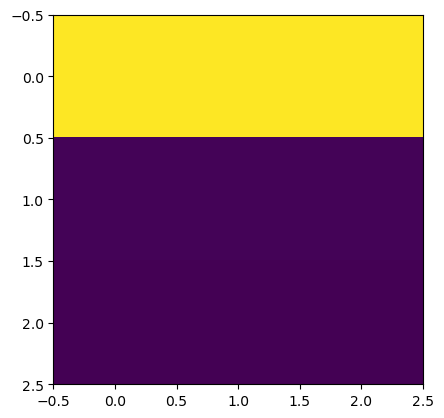

In [126]:
slice = interval_weights[:,1,:]
plt.imshow(slice)

In [134]:
interval_weights[0,0,0]

3.1500657637906215e-09

In [20]:
ii = np.unravel_index(np.argsort(weights.ravel())[-9:], weights.shape)
ii

(array([14, 14, 16, 16, 14, 15, 15, 16, 15]),
 array([14, 16, 14, 16, 15, 14, 16, 15, 15]))

In [21]:
ii = np.asarray(ii, dtype=int)
ii = ii.T

In [25]:
index = np.arange(ii.shape[0])

In [26]:
from itertools import combinations
pairs = np.array(list(combinations(index, 2)))

In [27]:
ang_sep_all = []
for i in range(len(pairs)):
    delta_x = (ii[pairs[i][0]][0] - ii[pairs[i][1]][0])*6.0
    delta_y = (ii[pairs[i][0]][1] - ii[pairs[i][1]][1])*6.0
    sep = np.sqrt(delta_x**2 + delta_y**2)
    ang_sep_all.append(sep)

ang_sep_all = np.asarray(ang_sep_all)

In [28]:
ang_sep = np.unique(ang_sep_all)

In [29]:
corr_weights = []
for i in range(len(ang_sep)):
    target_sep = ang_sep[i]
    full_filled_pairs = np.where(ang_sep_all == target_sep)[0]
    
    first_pix = ii[pairs[full_filled_pairs][:,0]]
    first_weights = weights[first_pix[:,0], first_pix[:,1]]
    
    second_pix = ii[pairs[full_filled_pairs][:,1]]
    second_weights = weights[second_pix[:,0], second_pix[:,1]]

    sum = np.sum(first_weights*second_weights)
    corr_weights.append(sum)

corr_weights = np.array(corr_weights)

In [31]:
print(ang_sep)
print(corr_weights)

[ 6.          8.48528137 12.         13.41640786 16.97056275]
[3.0908632  2.2346666  0.22423226 0.31699005 0.05761449]


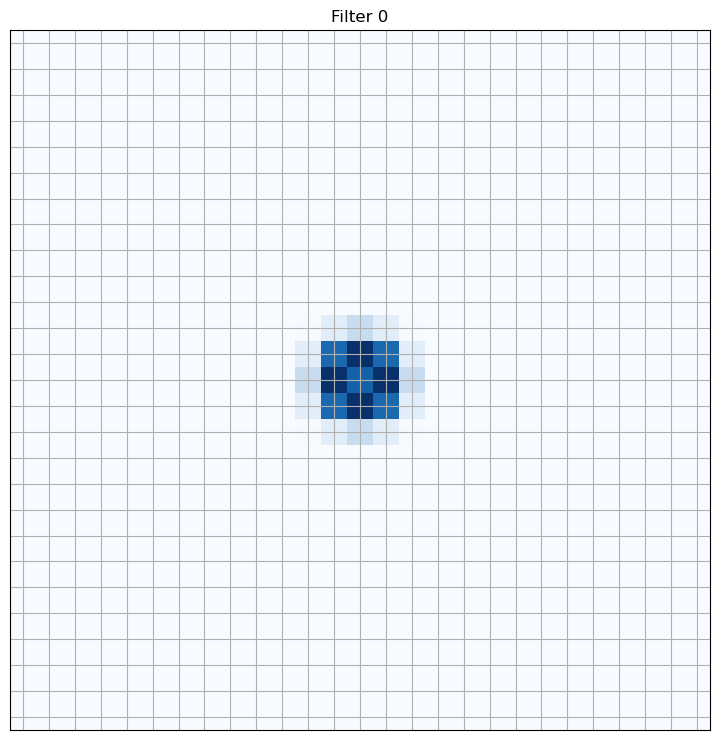

In [28]:
import matplotlib.ticker as plticker
n_filter = filters.shape[0]
n_chan = filters.shape[1]
fig = plt.figure(constrained_layout=False, figsize=(20, 20))
outergrid = fig.add_gridspec(n_chan, n_filter, left=0.05, right=0.55, wspace=0.05)
#== Plotting code ==#
# Make sure that all filters are plotted on the same colorscale
vmin = filters.min()
vmax = filters.max()
chan_cmaps = ['Blues', 'Reds']
#chan_labels = ['zs10', 'zs16']
for n in range(n_filter):
    filtgrid = outergrid[0, n].subgridspec(2, 1, wspace=0.1)
    for chan in range(n_chan):
        ax = fig.add_subplot(filtgrid[chan, 0])
        if chan == 0:
            ax.set_title("Filter " + str(n))
        myInterval=1
        loc = plticker.MultipleLocator(base=myInterval)
        ax.xaxis.set_major_locator(loc)
        ax.yaxis.set_major_locator(loc)
        # Add the grid
        ax.grid(which='major', axis='both', linestyle='-')
        ax.imshow(filters[n, chan], cmap=chan_cmaps[chan], vmin=vmin, vmax=vmax, norm='linear')
        #ax.imshow(filters[n, chan], vmin=vmin, vmax=vmax)
        ax.tick_params(
            bottom=False,
            labelbottom=False,
            left=False,
            labelleft=False,
        )
        #ax.set_ylabel(chan_labels[chan], rotation=90, fontsize=30)
plt.show()

In [30]:
print(filters.max())
print(filters.min())

0.13002014
1.5933687e-34


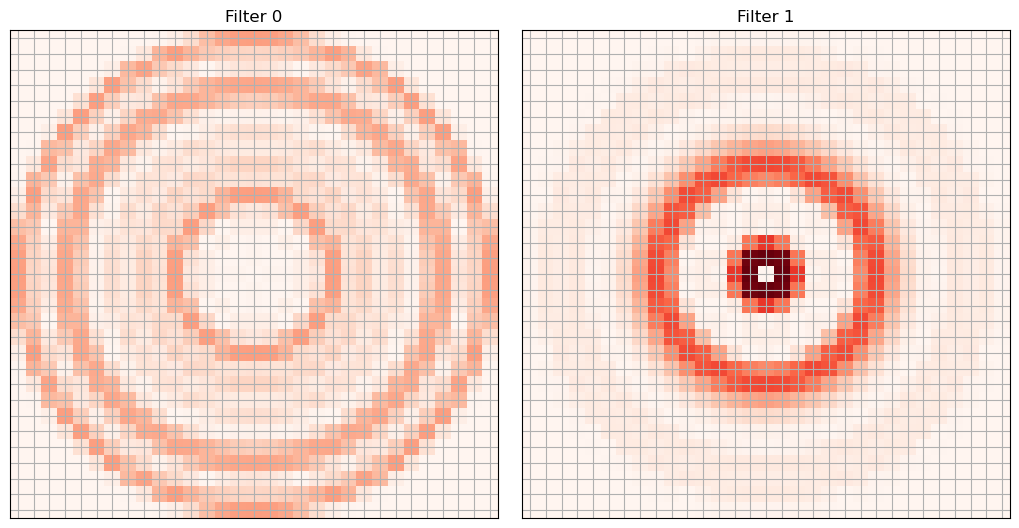

In [18]:
import matplotlib.ticker as plticker
n_filter = filters.shape[0]
n_chan = filters.shape[1]
fig = plt.figure(constrained_layout=False, figsize=(20, 20))
outergrid = fig.add_gridspec(n_chan, n_filter, left=0.05, right=0.55, wspace=0.05)
#== Plotting code ==#
# Make sure that all filters are plotted on the same colorscale
vmin = filters.min()
vmax = filters.max()
chan_cmaps = ['Reds', 'Blues']
#chan_labels = ['zs10', 'zs16']
for n in range(n_filter):
    filtgrid = outergrid[0, n].subgridspec(2, 1, wspace=0.1)
    for chan in range(n_chan):
        ax = fig.add_subplot(filtgrid[chan, 0])
        if chan == 0:
            ax.set_title("Filter " + str(n))
        myInterval=1
        loc = plticker.MultipleLocator(base=myInterval)
        ax.xaxis.set_major_locator(loc)
        ax.yaxis.set_major_locator(loc)
        # Add the grid
        ax.grid(which='major', axis='both', linestyle='-')
        ax.imshow(filters[n, chan], cmap=chan_cmaps[chan], vmin=vmin, vmax=vmax)
        #ax.imshow(filters[n, chan], vmin=vmin, vmax=vmax)
        ax.tick_params(
            bottom=False,
            labelbottom=False,
            left=False,
            labelleft=False,
        )
        #ax.set_ylabel(chan_labels[chan], rotation=90, fontsize=30)
plt.show()

In [10]:
np.save('correlation_measurement/gstools/1_filter_gaussiancov_lambda5_vs_20_1_channel_classification_120pixels_order4_hypertuned.npy', filters)

In [44]:
m = torch.nn.Linear(4, 2)
opt = torch.optim.Adam(m.parameters())
x = torch.rand((1,4))
y = torch.tensor([[0, 1]], dtype=torch.float32)
crit = torch.nn.BCEWithLogitsLoss()

In [45]:
print('before optimizer step')
for param in m.parameters():
    print(param)

before optimizer step
Parameter containing:
tensor([[-0.4543, -0.4362,  0.3107, -0.1208],
        [ 0.1108, -0.0928,  0.2235,  0.3934]], requires_grad=True)
Parameter containing:
tensor([ 0.2611, -0.3026], requires_grad=True)


In [46]:
out = m(x)
loss = crit(y, out)
loss.backward()

In [47]:
for i, param in enumerate(m.parameters()):
    if i == 0:
        print(param[:,1:])
        #frozen_weight = torch.clone(param[:,1:])
        param.grad[:,1:] = torch.zeros_like(param.grad[:,1:])

tensor([[-0.4362,  0.3107, -0.1208],
        [-0.0928,  0.2235,  0.3934]], grad_fn=<SliceBackward0>)


In [48]:
opt.step()
#for i, param in enumerate(m.parameters()):
#    if i == 0:
#        param[:,1:].data = frozen_weight
print('after optimizer step')
for param in m.parameters():
    print(param)

after optimizer step
Parameter containing:
tensor([[-0.4543, -0.4362,  0.3107, -0.1208],
        [ 0.1118, -0.0928,  0.2235,  0.3934]], requires_grad=True)
Parameter containing:
tensor([ 0.2611, -0.3016], requires_grad=True)


In [13]:
list(ccnn.modules())

[CCNN(
   (corr_conv): NonlinearConv(
     (conv): R2Conv([SO(2)_on_R2[(None, -1)]: {irrep_0 (x1)}(1)], [SO(2)_on_R2[(None, -1)]: {irrep_0 (x1)}(1)], kernel_size=31, stride=1, padding=15, bias=False)
   )
   (spatial_mean): Mean2d()
   (bn): BatchNorm1d(4, eps=3.185289e-35, momentum=0.1, affine=True, track_running_stats=True)
   (logistic_fc): Linear(in_features=4, out_features=1, bias=True)
   (concat): probability_concatenation()
 ),
 NonlinearConv(
   (conv): R2Conv([SO(2)_on_R2[(None, -1)]: {irrep_0 (x1)}(1)], [SO(2)_on_R2[(None, -1)]: {irrep_0 (x1)}(1)], kernel_size=31, stride=1, padding=15, bias=False)
 ),
 R2Conv([SO(2)_on_R2[(None, -1)]: {irrep_0 (x1)}(1)], [SO(2)_on_R2[(None, -1)]: {irrep_0 (x1)}(1)], kernel_size=31, stride=1, padding=15, bias=False),
 BlocksBasisExpansion(
   (block_expansion_('irrep_0', 'irrep_0')): SingleBlockBasisExpansion()
 ),
 SingleBlockBasisExpansion(),
 Mean2d(),
 BatchNorm1d(4, eps=3.185289e-35, momentum=0.1, affine=True, track_running_stats=True),


In [19]:
#=== Steps (1) + (2): Preprocessing ===#

#=== 1) Precompute all of the c_α^(n) ===#

# Make a model which is only the "front half" of the CCNN, stopping before applying the nn.Linear

chopped_ccnn_modules = []
for module in list(ccnn.modules())[1:5]:
#for module in list(ccnn.modules()):
    #if type(module) is not nn.Linear:
    #if (type(module) != nn.Linear) & (type(module) != nn.BatchNorm1d):
    #    chopped_ccnn_modules.append(module)
    chopped_ccnn_modules.append(module)
chopped_ccnn = nn.Sequential(*chopped_ccnn_modules)

"""
chopped_ccnn_modules_l = []
for module in list(ccnn_filter_l.modules())[1:5]:
    #if type(module) is not nn.Linear:
    #if (type(module) != nn.Linear) & (type(module) != nn.BatchNorm1d):
        #chopped_ccnn_modules.append(module)
    chopped_ccnn_modules_l.append(module)
chopped_ccnn_l = nn.Sequential(*chopped_ccnn_modules_l)

chopped_ccnn_modules_s = []
for module in list(ccnn_filter_s.modules())[1:5]:
    #if type(module) is not nn.Linear:
    #if (type(module) != nn.Linear) & (type(module) != nn.BatchNorm1d):
        #chopped_ccnn_modules.append(module)
    chopped_ccnn_modules_s.append(module)
chopped_ccnn_s = nn.Sequential(*chopped_ccnn_modules_s)
"""

'\nchopped_ccnn_modules_l = []\nfor module in list(ccnn_filter_l.modules())[1:5]:\n    #if type(module) is not nn.Linear:\n    #if (type(module) != nn.Linear) & (type(module) != nn.BatchNorm1d):\n        #chopped_ccnn_modules.append(module)\n    chopped_ccnn_modules_l.append(module)\nchopped_ccnn_l = nn.Sequential(*chopped_ccnn_modules_l)\n\nchopped_ccnn_modules_s = []\nfor module in list(ccnn_filter_s.modules())[1:5]:\n    #if type(module) is not nn.Linear:\n    #if (type(module) != nn.Linear) & (type(module) != nn.BatchNorm1d):\n        #chopped_ccnn_modules.append(module)\n    chopped_ccnn_modules_s.append(module)\nchopped_ccnn_s = nn.Sequential(*chopped_ccnn_modules_s)\n'

In [20]:
chopped_ccnn

Sequential(
  (0): SymSlice()
  (1): NonlinearConv()
  (2): SymPool()
  (3): Mean2d()
)

In [14]:
train_gaussian_rot = _rot(train_gaussian, 2)

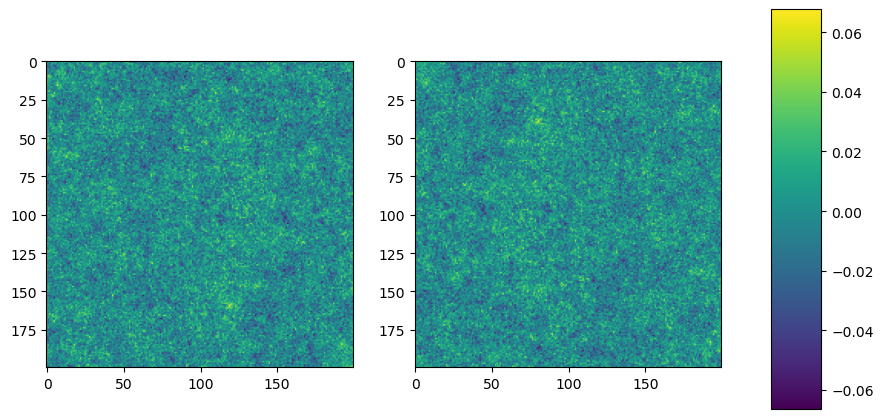

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10,10))
#im1 = axes[0].imshow(grf_example_s[3])
#im2 = axes[1].imshow(grf_example_l[3])

im1 = axes[0].imshow(train_gaussian[30,0])
im2 = axes[1].imshow(train_gaussian_rot[30,0])
fig.subplots_adjust(right=0.8)
cbar_ax = fig.add_axes([0.85, 0.3, 0.05, 0.4])
fig.colorbar(im2, cax=cbar_ax)
plt.show()

In [17]:
with torch.no_grad():
    # GSTools mapping
    #train_data = train_grf_s.to(device=device)
    #train_cαs_A = chopped_ccnn(train_data).cpu()
    #train_cαs_A = train_cαs_A.numpy()
    
    #train_data = train_grf_s1.to(device=device)
    #train_cαs_B = chopped_ccnn(train_data).cpu()
    #train_cαs_B = train_cαs_B.numpy()
    
    #train_data = train_grf_m.to(device=device)
    #train_cαs_C = chopped_ccnn(train_data).cpu()
    #train_cαs_C = train_cαs_C.numpy()
    
    #train_data = train_grf_l.to(device=device)
    #train_cαs_D = chopped_ccnn(train_data).cpu()
    #train_cαs_D = train_cαs_D.numpy()

    # FLASK mapping with different map sizes
    #train_data_grf = train_gaussian.to(device=device)
    #train_cαs_A = chopped_ccnn(train_data_grf).cpu()
    #train_cαs_A = train_cαs_A.numpy()

    #train_data_log = train_log.to(device=device)
    #train_cαs_B = chopped_ccnn(train_data_log).cpu()
    #train_cαs_B = train_cαs_B.numpy()

    #train_data_grf_s = train_grf_s.to(device=device)
    #train_cαs_C = chopped_ccnn(train_data_grf_s).cpu()
    #train_cαs_C = ccnn(train_data_grf_s, chop=True).cpu()
    #train_cαs_C = train_cαs_C.numpy()

    #train_data_log_s = train_log_s.to(device=device)
    #train_cαs_D = chopped_ccnn(train_data_log_s).cpu()
    #train_cαs_D = train_cαs_D.numpy()

    #train_data_grf_l = train_grf_l.to(device=device)
    #train_cαs_E = chopped_ccnn(train_data_grf_l).cpu()
    #train_cαs_E = ccnn(train_data_grf_l, chop=True).cpu()
    #train_cαs_E = train_cαs_E.numpy()

    #train_data_log_l = train_log_l.to(device=device)
    #train_cαs_F = chopped_ccnn(train_data_log_l).cpu()
    #train_cαs_F = train_cαs_F.numpy()

    # FLASK mapping with different filter sizes
    #train_data_grf = train_gaussian.to(device=device)
    #train_cαs_A = chopped_ccnn(train_data_grf).cpu()
    #train_cαs_A = ccnn(train_data_grf, chop=True).cpu()
    #train_cαs_A = train_cαs_A.numpy()
    
    #train_cαs_B = chopped_ccnn_l(train_data_grf).cpu()
    #train_cαs_B = train_cαs_B.numpy()

    #train_cαs_C = chopped_ccnn_s(train_data_grf).cpu()
    #train_cαs_C = train_cαs_C.numpy()

    #train_data_log = train_log.to(device=device)
    #train_cαs_D = chopped_ccnn(train_data_log).cpu()
    #train_cαs_D = ccnn(train_data_log, chop=True).cpu()
    #train_cαs_D = train_cαs_D.numpy()
    
    #train_cαs_E = chopped_ccnn_l(train_data_log).cpu()
    #train_cαs_E = train_cαs_E.numpy()

    #train_cαs_F = chopped_ccnn_s(train_data_log).cpu()
    #train_cαs_F = train_cαs_F.numpy()

    # Test on the rotated maps
    #train_data_grf = train_gaussian.to(device=device)
    #train_cαs_A = ccnn(train_data_grf, chop=True).cpu()
    #train_cαs_A = train_cαs_A.numpy()

    #train_data_grf_rot = train_gaussian_rot.to(device=device)
    #train_cαs_B = ccnn(train_data_grf_rot, chop=True).cpu()
    #train_cαs_B = train_cαs_B.numpy()

    # Test on the log-normal random fields with different shift parameter
    train_data_lambda1 = train_log_lambda1.to(device=device)
    train_cαs_A = ccnn(train_data_lambda1, chop=True).cpu()
    train_cαs_A = train_cαs_A.numpy()
    
    train_data_lambda2 = train_log_lambda2.to(device=device)
    train_cαs_B = ccnn(train_data_lambda2, chop=True).cpu()
    train_cαs_B = train_cαs_B.numpy()

In [18]:
train_cαs_C = train_cαs_A
train_cαs_D = train_cαs_B

In [20]:
np.allclose(train_cαs_A, train_cαs_B, rtol=1e-08, atol=1e-8)

True

In [24]:
# Save c distributions reagrding the map size test
#np.save('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_gaussian_6300maps_w_model_on_20deg_200pix.npy', train_cαs_A)
#np.save('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_gaussian_6300maps_10deg_100pix_w_model_on_20deg_200pix.npy', train_cαs_C)
#np.save('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_gaussian_1800maps_40deg_400pix_w_model_on_20deg_200pix.npy', train_cαs_E)

#np.save('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_lognormal_6300maps_w_model_on_20deg_200pix.npy', train_cαs_B)
#np.save('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_lognormal_6300maps_10deg_100pix_w_model_on_20deg_200pix.npy', train_cαs_D)
#np.save('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_lognormal_1800maps_40deg_400pix_w_model_on_20deg_200pix.npy', train_cαs_F)

# Save c distributions regarding the filter size test
np.save('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_gaussian_6300maps_w_model_filter31pix_on_20deg_200pix.npy', train_cαs_A)
np.save('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_gaussian_6300maps_w_model_filter51pix_on_20deg_200pix.npy', train_cαs_B)
np.save('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_gaussian_6300maps_w_model_filter11pix_on_20deg_200pix.npy', train_cαs_C)

np.save('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_lognormal_6300maps_w_model_filter31pix_on_20deg_200pix.npy', train_cαs_D)
np.save('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_lognormal_6300maps_w_model_filter51pix_on_20deg_200pix.npy', train_cαs_E)
np.save('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_lognormal_6300maps_w_model_filter11pix_on_20deg_200pix.npy', train_cαs_F)


In [17]:
# Pass all of the data through this model to obtain the c_α^(n) [corr_feats]
train_cαs, train_labels = [], []
train_cαs_A, train_cαs_B = [], []
val_cαs, val_labels = [], []
val_cαs_A, val_cαs_B = [], []
with torch.no_grad():
    for inputs, labels in train_loader:
        train_mask_A = torch.reshape((labels == 0).nonzero(), (-1,))
        train_mask_B = torch.reshape((labels == 1).nonzero(), (-1,))
        #train_inputs_A = inputs[train_mask_A]
        #train_inputs_B = inputs[train_mask_B]
        
        #train_inputs_A = train_inputs_A.to(device=device)
        #train_inputs_B = train_inputs_B.to(device=device)
        inputs = inputs.to(device=device)
        
        #cα = chopped_ccnn(inputs).cpu()
        cα = ccnn(inputs, chop=True).cpu()
        cα_A = cα[train_mask_A]
        cα_B = cα[train_mask_B]
        train_cαs.append(cα)
        train_cαs_A.append(cα_A)
        train_cαs_B.append(cα_B)
        train_labels.append(labels)
    for inputs, labels in val_loader:
        val_mask_A = torch.reshape((labels == 0).nonzero(), (-1,))
        val_mask_B = torch.reshape((labels == 1).nonzero(), (-1,))
        
        inputs = inputs.to(device=device)
        #cα = chopped_ccnn(inputs).cpu()
        cα = ccnn(inputs, chop=True).cpu()
        cα_A = cα[val_mask_A]
        cα_B = cα[val_mask_B]
        val_cαs.append(cα)
        val_cαs_A.append(cα_A)
        val_cαs_B.append(cα_B)
        val_labels.append(labels)

train_cαs = torch.cat(train_cαs).numpy()
train_cαs_A = torch.cat(train_cαs_A).numpy()
train_cαs_B = torch.cat(train_cαs_B).numpy()
train_labels = torch.cat(train_labels).numpy()

val_cαs = torch.cat(val_cαs).numpy()
val_cαs_A = torch.cat(val_cαs_A).numpy()
val_cαs_B = torch.cat(val_cαs_B).numpy()
val_labels = torch.cat(val_labels).numpy()

Text(0.5, 0, '$c_{1}^{(4)}$')

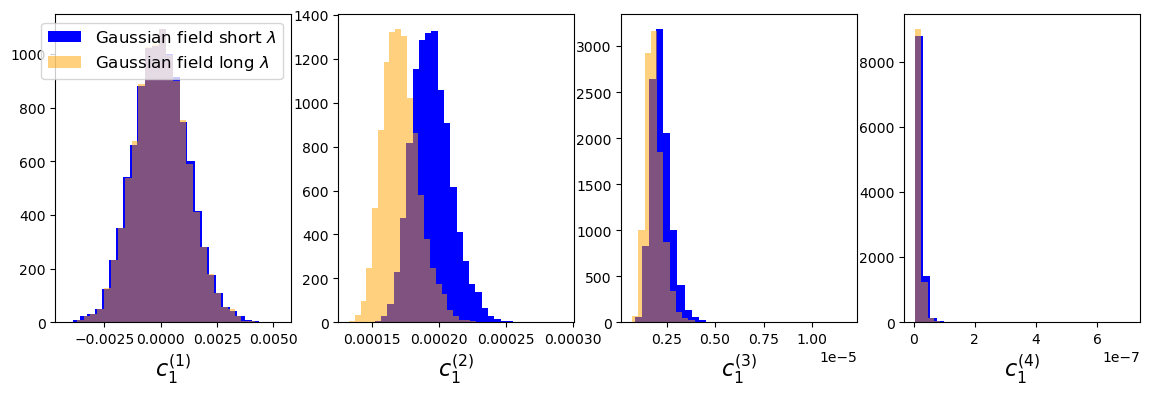

In [21]:
fig, axs = plt.subplots(1, 4, figsize=(14, 4))
labelA = ['Gaussian field', 'Gaussian field short '+r'$\lambda$']
labelB = ['Log-normal field', 'Gaussian field long '+r'$\lambda$']

axs[0].hist(train_cαs_A[:,0], bins=30, color='blue', label=labelA[1])
axs[0].hist(train_cαs_B[:,0], bins=30, color='orange', alpha=0.5, label=labelB[1])
#axs[0,0].hist(train_cαs_A[:,0], bins=30, color='blue', label=r'$M_{\nu} = 0.0$ '+'eV')
#axs[0,0].hist(train_cαs_B[:,0], bins=30, color='orange', alpha=0.5, label=r'$M_{\nu} = 0.1$ '+'eV')
axs[0].set_xlabel(r'$c_{1}^{(1)}$', fontsize=16)
axs[0].legend(fontsize=12)

axs[1].hist(train_cαs_A[:,1], bins=30, color='blue')
axs[1].hist(train_cαs_B[:,1], bins=30, color='orange', alpha=0.5)
axs[1].set_xlabel(r'$c_{1}^{(2)}$', fontsize=16)

axs[2].hist(train_cαs_A[:,2], bins=30, color='blue')
axs[2].hist(train_cαs_B[:,2], bins=30, color='orange', alpha=0.5)
axs[2].set_xlabel(r'$c_{1}^{(3)}$', fontsize=16)

axs[3].hist(train_cαs_A[:,3], bins=30, color='blue')
axs[3].hist(train_cαs_B[:,3], bins=30, color='orange', alpha=0.5)
axs[3].set_xlabel(r'$c_{1}^{(4)}$', fontsize=16)

In [22]:
np.save('c_prediction_gaussian_1filter_t17_zs16_4deg_120pixels_order4_hypertuned.npy', train_cαs_A)
np.save('c_prediction_lognormal_1filter_t17_zs16_4deg_120pixels_order4_hypertuned.npy', train_cαs_B)

Text(0.5, 0, '$c_{2}^{(4)}$')

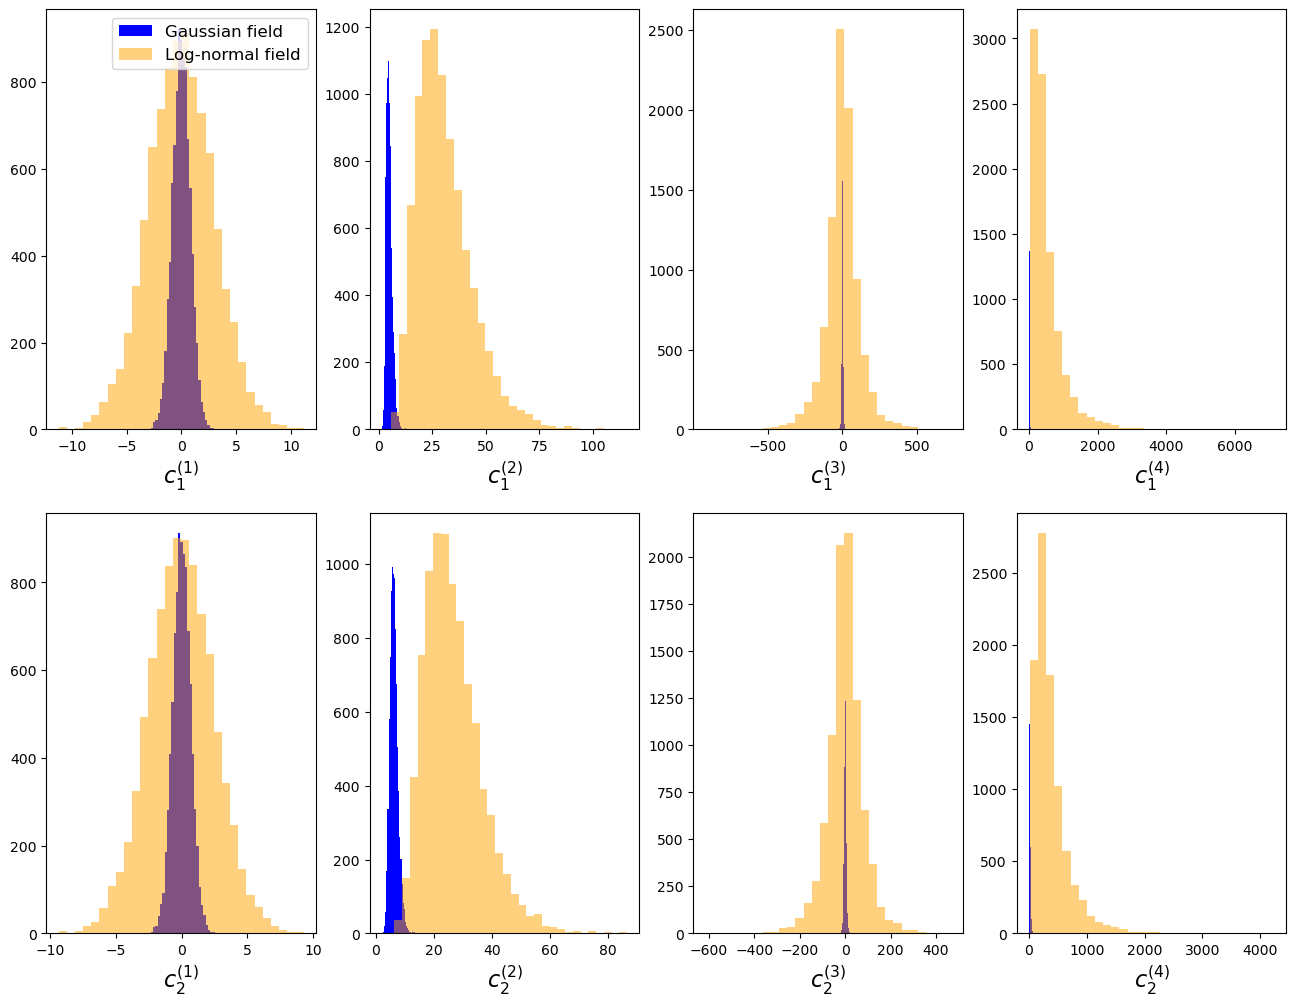

In [21]:
fig, axs = plt.subplots(2, 4, figsize=(16, 12))
axs[0,0].hist(train_cαs_A[:,0], bins=30, color='blue', label='Gaussian field')
axs[0,0].hist(train_cαs_B[:,0], bins=30, color='orange', alpha=0.5, label='Log-normal field')
#axs[0,0].hist(train_cαs_A[:,0], bins=30, color='blue', label=r'$M_{\nu} = 0.0$ '+'eV')
#axs[0,0].hist(train_cαs_B[:,0], bins=30, color='orange', alpha=0.5, label=r'$M_{\nu} = 0.1$ '+'eV')
axs[0,0].set_xlabel(r'$c_{1}^{(1)}$', fontsize=16)
axs[0,0].legend(fontsize=12)
axs[1,0].hist(train_cαs_A[:,1], bins=30, color='blue')
axs[1,0].hist(train_cαs_B[:,1], bins=30, color='orange', alpha=0.5)
axs[1,0].set_xlabel(r'$c_{2}^{(1)}$', fontsize=16)

axs[0,1].hist(train_cαs_A[:,2], bins=30, color='blue')
axs[0,1].hist(train_cαs_B[:,2], bins=30, color='orange', alpha=0.5)
axs[0,1].set_xlabel(r'$c_{1}^{(2)}$', fontsize=16)
axs[1,1].hist(train_cαs_A[:,3], bins=30, color='blue')
axs[1,1].hist(train_cαs_B[:,3], bins=30, color='orange', alpha=0.5)
axs[1,1].set_xlabel(r'$c_{2}^{(2)}$', fontsize=16)

axs[0,2].hist(train_cαs_A[:,4], bins=30, color='blue')
axs[0,2].hist(train_cαs_B[:,4], bins=30, color='orange', alpha=0.5)
axs[0,2].set_xlabel(r'$c_{1}^{(3)}$', fontsize=16)
axs[1,2].hist(train_cαs_A[:,5], bins=30, color='blue')
axs[1,2].hist(train_cαs_B[:,5], bins=30, color='orange', alpha=0.5)
axs[1,2].set_xlabel(r'$c_{2}^{(3)}$', fontsize=16)

axs[0,3].hist(train_cαs_A[:,6], bins=30, color='blue')
axs[0,3].hist(train_cαs_B[:,6], bins=30, color='orange', alpha=0.5)
axs[0,3].set_xlabel(r'$c_{1}^{(4)}$', fontsize=16)
axs[1,3].hist(train_cαs_A[:,7], bins=30, color='blue')
axs[1,3].hist(train_cαs_B[:,7], bins=30, color='orange', alpha=0.5)
axs[1,3].set_xlabel(r'$c_{2}^{(4)}$', fontsize=16)

In [18]:
#=== 2) Normalize all c_α^{(n)} to zero mean and unit variance ===#
train_mean = train_cαs.mean(axis=0, keepdims=True, dtype=np.float64)
train_std = train_cαs.std(axis=0, keepdims=True, ddof=1, dtype=np.float64)
val_mean = val_cαs.mean(axis=0, keepdims=True, dtype=np.float64)
val_std = val_cαs.std(axis=0, keepdims=True, ddof=1, dtype=np.float64)

train_cαs_norm = (train_cαs - train_mean) / (train_std)
val_cαs_norm = (val_cαs - val_mean) / (val_std) 
train_cαs_A_norm = (train_cαs_A - train_mean) / (train_std)
train_cαs_B_norm = (train_cαs_B - train_mean) / (train_std)

Text(0.5, 0, '$c_{1}^{(4)}$')

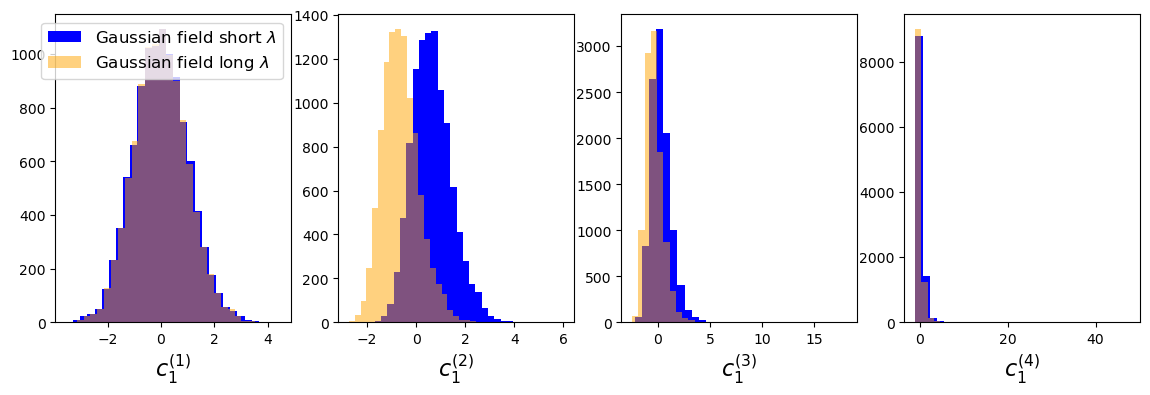

In [23]:
fig, axs = plt.subplots(1, 4, figsize=(14, 4))
labelA = ['Gaussian field', 'Gaussian field short '+r'$\lambda$']
labelB = ['Log-normal field', 'Gaussian field long '+r'$\lambda$']

axs[0].hist(train_cαs_A_norm[:,0], bins=30, color='blue', label=labelA[1])
axs[0].hist(train_cαs_B_norm[:,0], bins=30, color='orange', alpha=0.5, label=labelB[1])
#axs[0,0].hist(train_cαs_A[:,0], bins=30, color='blue', label=r'$M_{\nu} = 0.0$ '+'eV')
#axs[0,0].hist(train_cαs_B[:,0], bins=30, color='orange', alpha=0.5, label=r'$M_{\nu} = 0.1$ '+'eV')
axs[0].set_xlabel(r'$c_{1}^{(1)}$', fontsize=16)
axs[0].legend(fontsize=12)

axs[1].hist(train_cαs_A_norm[:,1], bins=30, color='blue')
axs[1].hist(train_cαs_B_norm[:,1], bins=30, color='orange', alpha=0.5)
axs[1].set_xlabel(r'$c_{1}^{(2)}$', fontsize=16)

axs[2].hist(train_cαs_A_norm[:,2], bins=30, color='blue')
axs[2].hist(train_cαs_B_norm[:,2], bins=30, color='orange', alpha=0.5)
axs[2].set_xlabel(r'$c_{1}^{(3)}$', fontsize=16)

axs[3].hist(train_cαs_A_norm[:,3], bins=30, color='blue')
axs[3].hist(train_cαs_B_norm[:,3], bins=30, color='orange', alpha=0.5)
axs[3].set_xlabel(r'$c_{1}^{(4)}$', fontsize=16)

Text(0.5, 0, '$c_{2, norm}^{(4)}$')

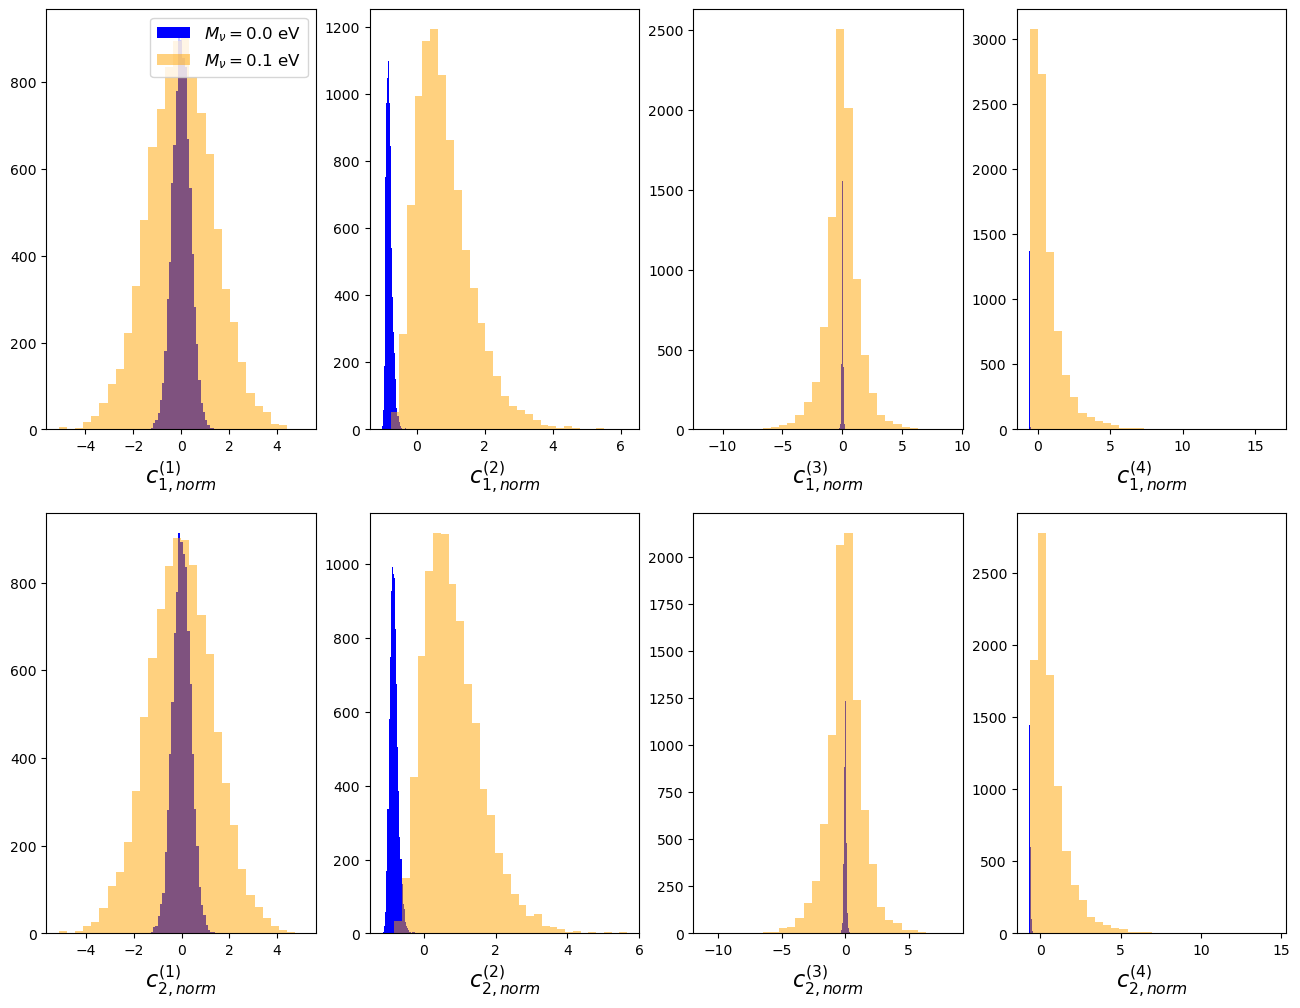

In [23]:
fig, axs = plt.subplots(2, 4, figsize=(16, 12))
#axs[0,0].hist(train_cαs_A_norm[:,0], bins=30, color='blue', label='Gaussian field')
#axs[0,0].hist(train_cαs_B_norm[:,0], bins=30, color='orange', alpha=0.5, label='Log-normal field')
axs[0,0].hist(train_cαs_A_norm[:,0], bins=30, color='blue', label=r'$M_{\nu} = 0.0$ '+'eV')
axs[0,0].hist(train_cαs_B_norm[:,0], bins=30, color='orange', alpha=0.5, label=r'$M_{\nu} = 0.1$ '+'eV')
axs[0,0].set_xlabel(r'$c_{1, norm}^{(1)}$', fontsize=16)
axs[0,0].legend(fontsize=12)
axs[1,0].hist(train_cαs_A_norm[:,1], bins=30, color='blue')
axs[1,0].hist(train_cαs_B_norm[:,1], bins=30, color='orange', alpha=0.5)
axs[1,0].set_xlabel(r'$c_{2, norm}^{(1)}$', fontsize=16)

axs[0,1].hist(train_cαs_A_norm[:,2], bins=30, color='blue')
axs[0,1].hist(train_cαs_B_norm[:,2], bins=30, color='orange', alpha=0.5)
axs[0,1].set_xlabel(r'$c_{1, norm}^{(2)}$', fontsize=16)
axs[1,1].hist(train_cαs_A_norm[:,3], bins=30, color='blue')
axs[1,1].hist(train_cαs_B_norm[:,3], bins=30, color='orange', alpha=0.5)
axs[1,1].set_xlabel(r'$c_{2, norm}^{(2)}$', fontsize=16)

axs[0,2].hist(train_cαs_A_norm[:,4], bins=30, color='blue')
axs[0,2].hist(train_cαs_B_norm[:,4], bins=30, color='orange', alpha=0.5)
axs[0,2].set_xlabel(r'$c_{1, norm}^{(3)}$', fontsize=16)
axs[1,2].hist(train_cαs_A_norm[:,5], bins=30, color='blue')
axs[1,2].hist(train_cαs_B_norm[:,5], bins=30, color='orange', alpha=0.5)
axs[1,2].set_xlabel(r'$c_{2, norm}^{(3)}$', fontsize=16)

axs[0,3].hist(train_cαs_A_norm[:,6], bins=30, color='blue')
axs[0,3].hist(train_cαs_B_norm[:,6], bins=30, color='orange', alpha=0.5)
axs[0,3].set_xlabel(r'$c_{1, norm}^{(4)}$', fontsize=16)
axs[1,3].hist(train_cαs_A_norm[:,7], bins=30, color='blue')
axs[1,3].hist(train_cαs_B_norm[:,7], bins=30, color='orange', alpha=0.5)
axs[1,3].set_xlabel(r'$c_{2, norm}^{(4)}$', fontsize=16)

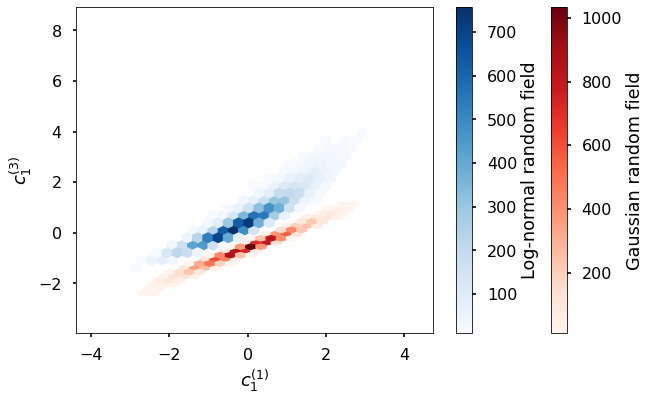

In [34]:
plt.figure(figsize=(10, 6))
hist1 = plt.hexbin(train_cαs_A_norm[:,0], train_cαs_A_norm[:,2], gridsize=30, cmap='Reds', mincnt=10, alpha=1.0, label='Gaussian random field')
hist2 = plt.hexbin(train_cαs_B_norm[:,0], train_cαs_B_norm[:,2], gridsize=30, cmap='Blues', mincnt=10, alpha=1.0, label='Log-normal random field')
plt.colorbar(hist1, orientation='vertical', label='Gaussian random field')
plt.colorbar(hist2, orientation='vertical', label='Log-normal random field')
plt.xlabel(r'$c^{(1)}_1$', fontsize=18)
plt.ylabel(r'$c^{(3)}_1$', fontsize=18)
# plt.margins(0.1) # Uncomment this if hex bins are partially outside of plot limits

plt.show()

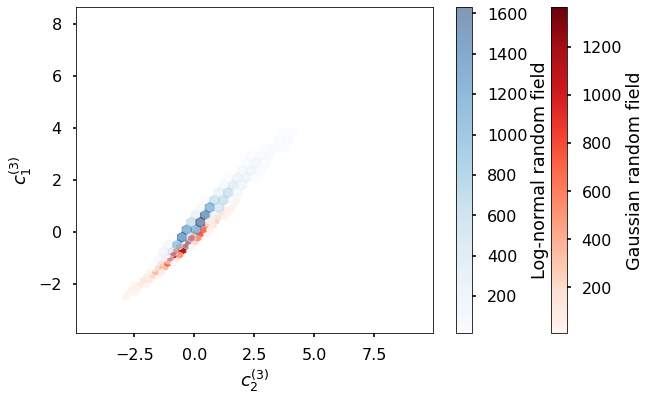

In [33]:
plt.figure(figsize=(10, 6))
hist1 = plt.hexbin(train_cαs_A_norm[:,5], train_cαs_A_norm[:,4], gridsize=30, cmap='Reds', mincnt=10, alpha=1.0, label='Gaussian random field')
hist2 = plt.hexbin(train_cαs_B_norm[:,5], train_cαs_B_norm[:,4], gridsize=30, cmap='Blues', mincnt=10, alpha=0.5, label='Log-normal random field')
plt.colorbar(hist1, orientation='vertical', label='Gaussian random field')
plt.colorbar(hist2, orientation='vertical', label='Log-normal random field')
plt.xlabel(r'$c^{(3)}_2$', fontsize=18)
plt.ylabel(r'$c^{(3)}_1$', fontsize=18)
# plt.margins(0.1) # Uncomment this if hex bins are partially outside of plot limits

plt.show()

In [19]:
#=== 3) Set up a logistic regression problem using sklearn ===#
logistic_clf = sklearn.linear_model.LogisticRegression(
    penalty="l1", solver='saga', warm_start=True, tol=1e-4,
    fit_intercept=True, max_iter=int(1e4)
)
# A list of inv_λs to train the model at.
inv_λs = np.logspace(-5, 1, num=2000)
# orders of correlator estimator
corr_order = 4
num_filts = 1
# Arrays/Lists to keep track of β_α^(n) and accuracies 
#β_αs = np.empty((len(inv_λs), corr_order * num_filts))
β_αs = np.zeros((len(inv_λs), corr_order * num_filts))
β_αs_intercept = np.zeros(len(inv_λs))
train_accs = np.empty(len(inv_λs))
val_accs = np.empty(len(inv_λs))
mask = np.ones(corr_order * num_filts, dtype=bool)
#mask[0] = 0
#mask[3] = 0
#mask[1] = 0
#mask[2] = 0
#mask[5] = 0

train_cαs_norm_masked = (train_cαs_norm[None,:]*mask)[0]
val_cαs_norm_masked = (val_cαs_norm[None,:]*mask)[0]

# Do the whole series of regressions!
for i, inv_λ in tqdm(enumerate(inv_λs), total=len(inv_λs)):
    # Set the regularization strength -- what sklearn calls C we call 1/λ
    logistic_clf.set_params(C=inv_λ)
    # Perform the regression
    logistic_clf.fit(train_cαs_norm_masked, train_labels)
    
    # Fix the β^3_1 coefficient after other β coefficients become non-zero
    #if logistic_clf.coef_.ravel()[0] != 0:
    #    logistic_clf.coef_.ravel()[0] = β_fix
    
    # Record the current coefficients β_α^(n)
    β_αs[i] = logistic_clf.coef_.ravel().copy()
    β_αs_intercept[i] = logistic_clf.intercept_.copy()
    # Record the current accuracies
    train_accs[i] = logistic_clf.score(train_cαs_norm_masked, train_labels)
    val_accs[i] = logistic_clf.score(val_cαs_norm_masked, val_labels)

100%|███████████████████████████████████████████████████████████████| 2000/2000 [01:50<00:00, 18.17it/s]


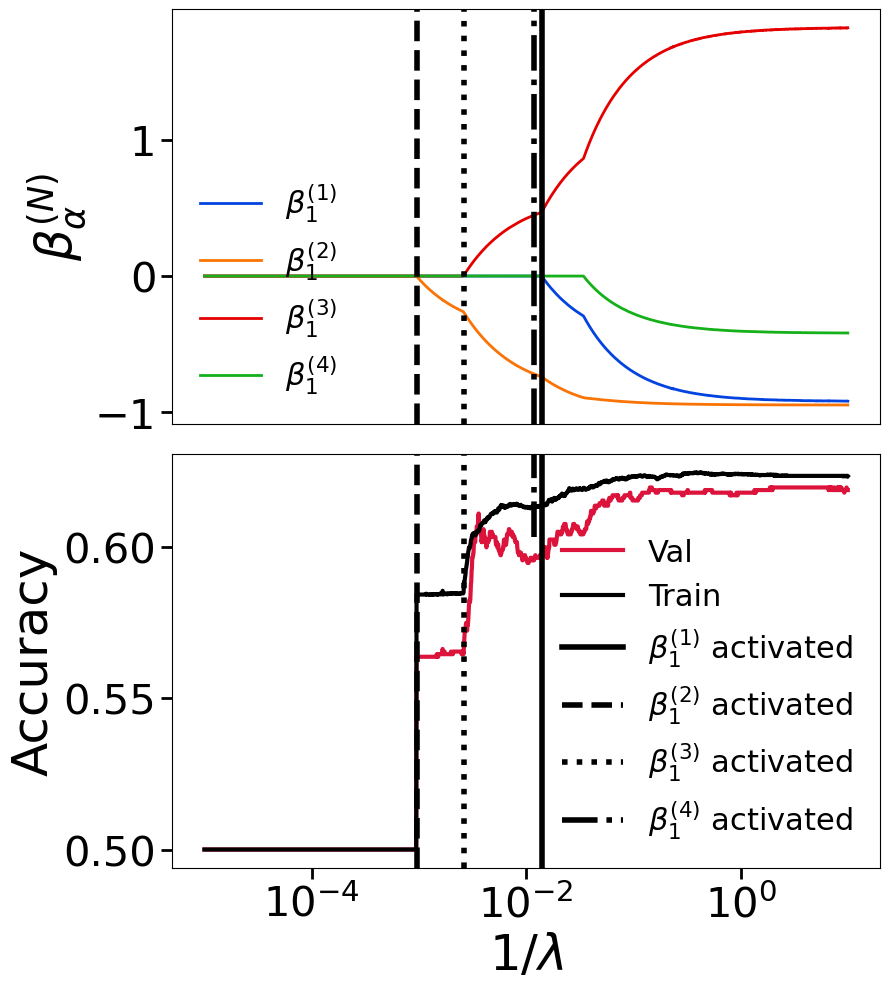

In [24]:
fig, axs = plt.subplots(2, 1, figsize=(9, 10))
β_ax, acc_ax = axs[0], axs[1]

β_ax.set_xscale('log')
β_ax.set_ylabel(r"$\beta_\alpha^{(N)}$", fontsize=36)
β_ax.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)
β_ax.tick_params(axis='y', labelsize=30, length=8.0, width=2.0)
acc_ax.set_xscale('log')
acc_ax.set_ylabel("Accuracy", fontsize=36)
acc_ax.set_xlabel(r"$1/\lambda$", fontsize=36)
acc_ax.tick_params(axis='x', which='major', labelsize=30, length=8.0, width=2.0)
acc_ax.tick_params(axis='x', which='minor', length=4.0, width=2.0)
acc_ax.tick_params(axis='y', labelsize=30, length=8.0, width=2.0)

# Colors of each β trajectory
colors = [
    #["xkcd:deep purple", "xkcd:royal purple", "xkcd:violet", "xkcd:light purple", "xkcd:pale purple"],
    #["xkcd:deep purple", "xkcd:royal purple", "xkcd:violet", "xkcd:light purple"],
    #["xkcd:burnt umber", "xkcd:dark orange", "xkcd:orange", "xkcd:pale orange"],
    ["xkcd:blue", "xkcd:orange", "xkcd:red", "xkcd:green"],
    #["xkcd:pale green", "xkcd:sea green", "xkcd:green", "xkcd:olive green"],
    #["xkcd:grass green", "xkcd:puke green", "xkcd:dark orange", "xkcd:orange", "xkcd:pale orange", "xkcd:red orange"],
    #["xkcd:grass green", "xkcd:puke green", "xkcd:dark orange", "xkcd:orange", "xkcd:pale orange", "xkcd:red orange", "xkcd:fuchsia"],
    #["xkcd:grass green", "xkcd:puke green", "xkcd:dark orange", "xkcd:orange", "xkcd:pale orange", "xkcd:red orange", "xkcd:fuchsia", "xkcd:black"]
]


for ifilt in range(num_filts):
    for iorder in range(corr_order):
    #for iorder in range(3):
        # Index into β_αs
        iβ = iorder * num_filts + ifilt
        color = colors[ifilt][iorder]
        label = r"$\beta_" + str(ifilt+1) + "^{(" + str(iorder+1) + ")}$"
        # There's an overall sign difference in how we define β_α in our CCNN
        # versus sklearn's LogisticRegression, so plot -β_α^(n)
        β_ax.plot(inv_λs, -β_αs[:, iβ], color=color, lw=2, label=label)

β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 0])[0][0]], linestyle='-', color='black', lw=4.0)
β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 1])[0][0]], linestyle='--', color='black', lw=4.0)
β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 2])[0][0]], linestyle='dotted', color='black', lw=4.0)
β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 3])[0][0]], linestyle='dashdot', color='black', lw=4.0)

#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 0])[0][0]], linestyle='--', color='xkcd:grass green', lw=3.0)
#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 1])[0][0]], linestyle='--', color='xkcd:puke green', lw=3.0)
#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 2])[0][0]], linestyle='--', color='xkcd:dark orange', lw=3.0)
#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 3])[0][0]], linestyle='--', color='xkcd:orange', lw=3.0)
#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 4])[0][0]], linestyle='--', color='xkcd:pale orange', lw=3.0)
#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 5])[0][0]], linestyle='--', color='xkcd:red orange', lw=3.0)
#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 6])[0][0]], linestyle='--', color='xkcd:fuchsia', lw=3.0)
#β_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 7])[0][0]], linestyle='--', color='xkcd:black', lw=3.0)

β_ax.legend(fontsize=22, frameon=False, loc='lower left')
#β_ax.legend(fontsize=20, frameon=False, loc='center left', bbox_to_anchor=(1, 0.5))    

# Plot the accuracies
acc_ax.plot(inv_λs, val_accs, lw=3, color='crimson', label="Val")
acc_ax.plot(inv_λs, train_accs, lw=3, color='black', label="Train")

acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 0])[0][0]], linestyle='-', color='black', lw=4.0, label=r'$\beta_{1}^{(1)}$ '+'activated')
acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 1])[0][0]], linestyle='--', color='black', lw=4.0, label=r'$\beta_{1}^{(2)}$ '+'activated')
acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 2])[0][0]], linestyle='dotted', color='black', lw=4.0, label=r'$\beta_{1}^{(3)}$ '+'activated')
acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 3])[0][0]], ymin=0.80, linestyle='dashdot', color='black', lw=4.0, label=r'$\beta_{1}^{(4)}$ '+'activated')

#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 0])[0][0]], linestyle='--', color='xkcd:grass green', lw=3.0, label=r'$\beta_{1}^{(1)}$ '+'activated')
#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 1])[0][0]], linestyle='--', color='xkcd:puke green', lw=3.0, label=r'$\beta_{1}^{(2)}$ '+'activated')
#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 2])[0][0]], linestyle='--', color='xkcd:dark orange', lw=3.0, label=r'$\beta_{1}^{(3)}$ '+'activated')
#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 3])[0][0]], linestyle='--', color='xkcd:orange', lw=3.0, label=r'$\beta_{1}^{(4)}$ '+'activated')
#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 4])[0][0]], linestyle='--', color='xkcd:pale orange', lw=3.0, label=r'$\beta_{1}^{(5)}$ '+'activated')
#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 5])[0][0]], linestyle='--', color='xkcd:red orange', lw=3.0, label=r'$\beta_{1}^{(6)}$ '+'activated')
#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 6])[0][0]], linestyle='--', color='xkcd:fuchsia', lw=3.0, label=r'$\beta_{1}^{(7)}$ '+'activated')
#acc_ax.axvline(inv_λs[np.nonzero(-β_αs[:, 7])[0][0]], linestyle='--', color='xkcd:black', lw=3.0, label=r'$\beta_{1}^{(8)}$ '+'activated')

acc_ax.legend(fontsize=22, frameon=False, loc='lower right')
#acc_ax.legend(fontsize=20, frameon=False, loc='center left', bbox_to_anchor=(1, 0.5))    
fig.tight_layout()

plt.show()
#plt.savefig('paper_plot/grf_lognormal_regularization_path_up_to_c4.pdf', format='pdf', dpi=300, bbox_inches='tight')

In [31]:
np.nonzero(-β_αs[:, 4])[0][0]

917

In [35]:
print(train_accs[880] - train_accs[np.nonzero(-β_αs[:, 2])[0][0]])

0.07844827586206904


In [23]:
print(train_accs[np.nonzero(-β_αs[:, 2])[0][0]] - train_accs[0])
print(train_accs[np.nonzero(-β_αs[:, 0])[0][0]] - train_accs[np.nonzero(-β_αs[:, 2])[0][0]])
print(train_accs[np.nonzero(-β_αs[:, 3])[0][0]] - train_accs[np.nonzero(-β_αs[:, 0])[0][0]])
#print(train_accs[1050] - train_accs[np.nonzero(-β_αs[:, 4])[0][0]])
#print(train_accs[np.nonzero(-β_αs[:, 5])[0][0]] - train_accs[1050])
#print(train_accs[np.nonzero(-β_αs[:, 3])[0][0]] - train_accs[np.nonzero(-β_αs[:, 5])[0][0]])
#print(train_accs[np.nonzero(-β_αs[:, 7])[0][0]] - train_accs[np.nonzero(-β_αs[:, 3])[0][0]])
print(train_accs[-1] - train_accs[np.nonzero(-β_αs[:, 3])[0][0]])
print(train_accs[-1])

0.09099616858237547
0.059291187739463624
0.0033524904214559115
0.012643678160919603
0.6662835249042146


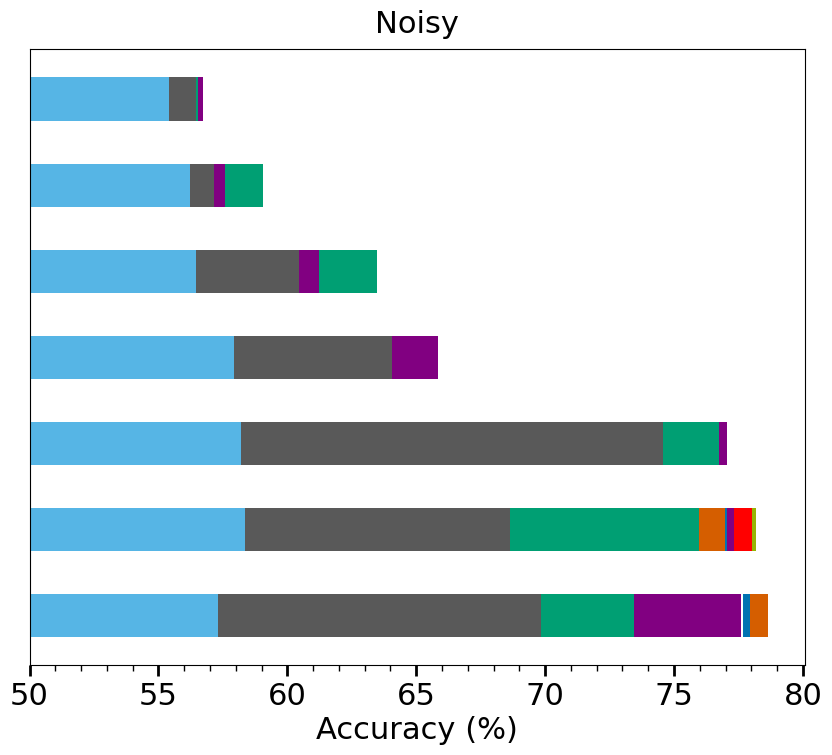

In [52]:
plt.figure(figsize=(10,8))
test_group = ['no smoothing and \ntuned filter size,\ncorrelation order', 'no smoothing and \ntuned correlation order', 'no smoothing', r'$10^{\prime}$ '+'smoothing', r'$20^{\prime}$ '+'smoothing', r'$30^{\prime}$ '+'smoothing', r'$40^{\prime}$ '+'smoothing']
start = np.array([50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0])
c2 = np.array([7.33, 8.36, 8.19, 7.93, 6.47, 6.21, 5.43]) 
c3 = np.array([12.5, 10.26, 16.38, 6.12, 3.97, 0.95, 1.03])

test_group1 = ['no smoothing and \ntuned filter size,\ncorrelation order', 'no smoothing', r'$10^{\prime}$ '+'smoothing', r'$40^{\prime}$ '+'smoothing']
start1 = np.array([50.0, 50.0, 50.0, 50.0])
c1_1 = np.array([3.62, 2.16, 0, 0.09])
c2_1 = np.array([7.33, 8.19, 7.93, 5.43])
c3_1 = np.array([12.5, 16.38, 6.12, 1.03])
c4_1 = np.array([4.14, 0.34, 1.81, 0.17])

test_group2 = [r'$20^{\prime}$ '+'smoothing', r'$30^{\prime}$ '+'smoothing']
start2 = np.array([50.0, 50.0])
c1_2 = np.array([2.24, 1.47])
c2_2 = np.array([6.47, 6.21])
c3_2 = np.array([3.97, 0.95])
c4_2 = np.array([0.78, 0.43])

test_group3 = ['no smoothing and \ntuned filter size,\ncorrelation order']
start3 = np.array([50])
c1_3 = np.array([3.62])
c2_3 = np.array([7.33])
c3_3 = np.array([12.59])
c4_3 = np.array([4.14])
c5_3 = np.array([0.26])
c6_3 = np.array([0.69])

test_group4 = ['no smoothing and \ntuned correlation order']
start4 = np.array([50])
c1_4 = np.array([7.33])
c2_4 = np.array([8.36])
c3_4 = np.array([10.26])
c4_4 = np.array([0.26])
c5_4 = np.array([0.09])
c6_4 = np.array([1.03])
c7_4 = np.array([0.69])
c8_4 = np.array([0.17])

height = np.array([0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5])
height1 = np.array([0.5, 0.5, 0.5, 0.5])
height2 = np.array([0.5, 0.5])
height3 = np.array([0.5])
height4 = np.array([0.5])

b1 = plt.barh(test_group, c2, left=start, color="#56b5e5", height=height)
b2 = plt.barh(test_group, c3, left=c2+start, color="#595959", height=height)
b3_1 = plt.barh(test_group1, c1_1, left=c2_1+c3_1+start1, color="#009f73", height=height1)
b4_1 = plt.barh(test_group1, c4_1, left=c2_1+c3_1+c1_1+start1, color='#810081', height=height1)
b3_2 = plt.barh(test_group2, c4_2, left=c2_2+c3_2+start2, color='#810081', height=height2)
b4_2 = plt.barh(test_group2, c1_2, left=c2_2+c3_2+c4_2+start2, color='#009f73', height=height2)
b5_3 = plt.barh(test_group3, c5_3, left=c1_3+c2_3+c3_3+c4_3+start3, color='#0072b1', height=height3) # 
b6_3 = plt.barh(test_group3, c6_3, left=c1_3+c2_3+c3_3+c4_3+c5_3+start3, color='#d55e00', height=height3)
b7_4 = plt.barh(test_group4, c1_4, left=c2_4+c3_4+start4, color="#009f73", height=height4)
b8_4 = plt.barh(test_group4, c6_4, left=c1_4+c2_4+c3_4+start4, color='#d55e00', height=height4)
b9_4 = plt.barh(test_group4, c5_4, left=c6_4+c1_4+c2_4+c3_4+start4, color='#0072b1', height=height4)
b10_4 = plt.barh(test_group4, c4_4, left=c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='#810081', height=height4)
b11_4 = plt.barh(test_group4, c7_4, left=c4_4+c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='red', height=height4)
b12_4 = plt.barh(test_group4, c8_4, left=c7_4+c4_4+c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='#96b403', height=height4)

#plt.legend([b3_1, b1, b2, b4_1, b5_3, b6_3, b11_4, b12_4], [r"$c_1^{(1)}$", r"$c_1^{(2)}$", r"$c_1^{(3)}$", r"$c_1^{(4)}$", r"$c_1^{(5)}$", r"$c_1^{(6)}$", r"$c_1^{(7)}$", r"$c_1^{(8)}$"], loc="upper right", frameon=False, fontsize=24, ncols=2)
plt.minorticks_on()
plt.xlabel('Accuracy (%)', fontsize=22)
plt.xlim(left=50.0)
plt.yticks([]) 
plt.tick_params(axis='x', which='major', length=8.0, width=2.0, labelsize=22)
#plt.tick_params(axis='both', which='major', length=8.0, width=2.0, labelsize=22)
plt.tick_params(axis='x', which='minor', length=4.0, width=1.0)
plt.tick_params(axis='y', which='minor', length=0.0, width=1.0)
plt.title('Noisy', fontsize=22.0, pad=12.0)

#plt.show()
#plt.savefig('paper_plot/ccnn_on_w0_noiseless.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.savefig('paper_plot/ccnn_on_w0_noisy.pdf', format='pdf', dpi=300, bbox_inches='tight')

In [56]:
(2.24+8.41+6.12+0.54)-(0.27+6.38+4.05)

6.609999999999999

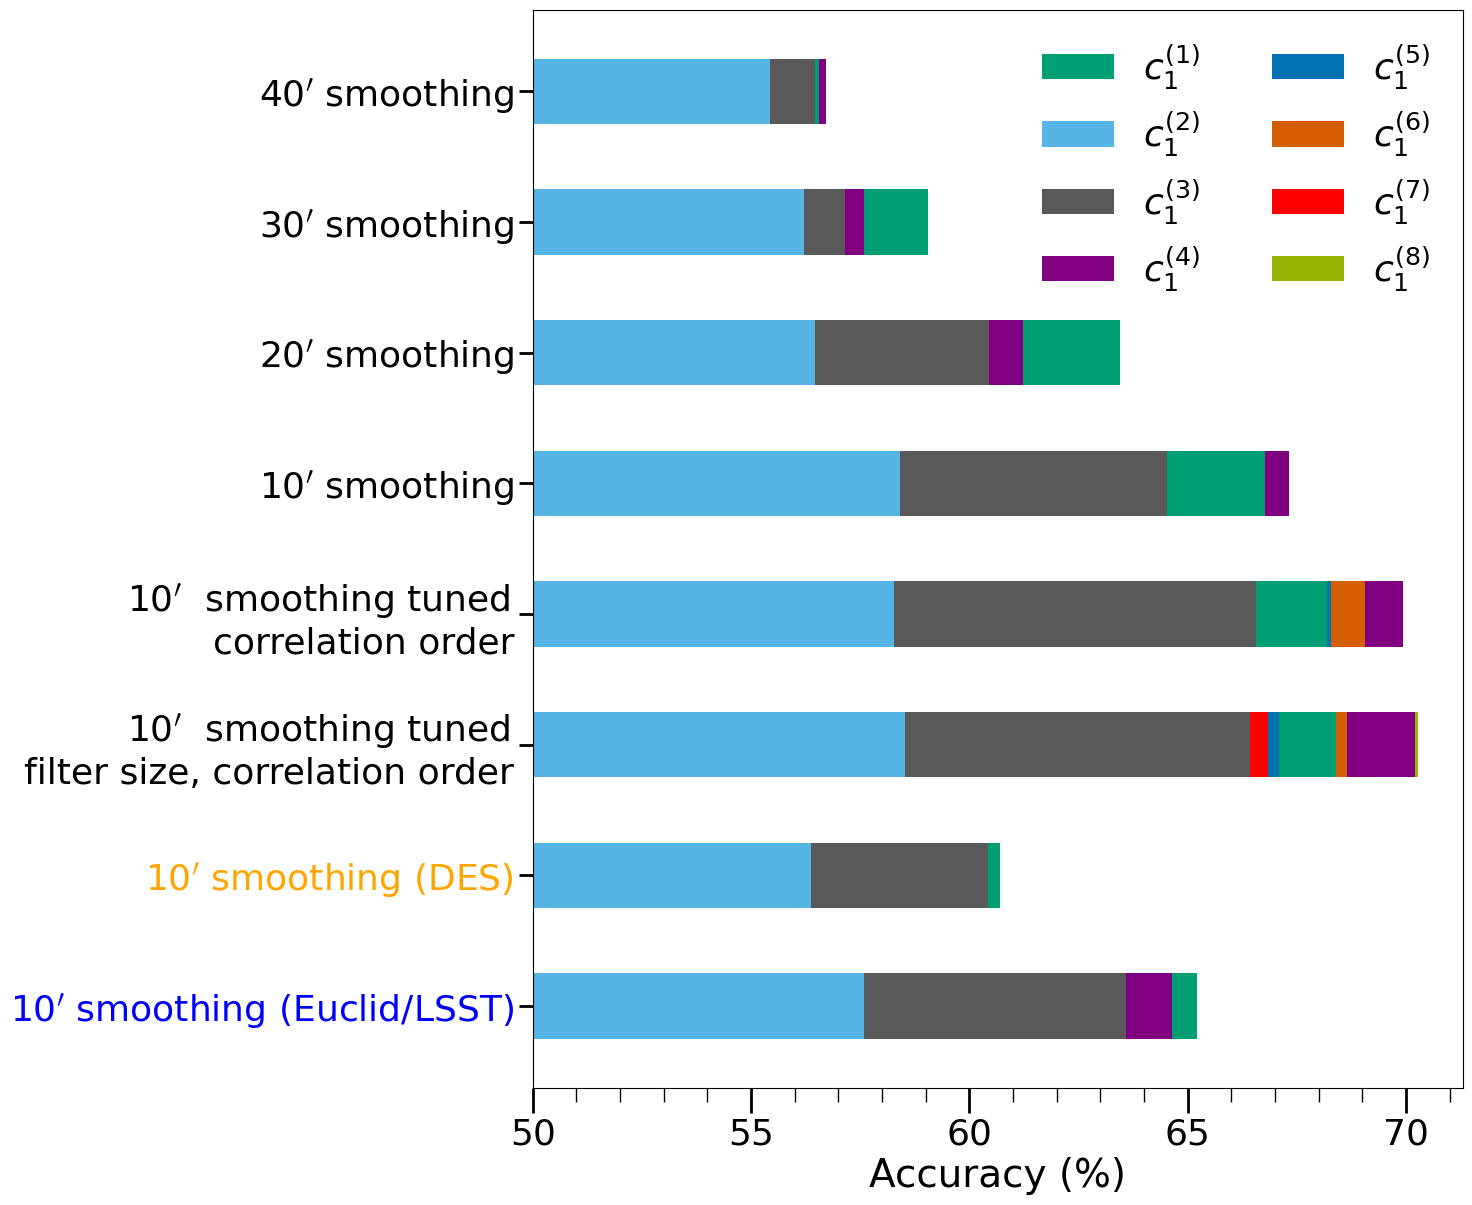

In [40]:
fig, ax = plt.subplots(figsize=(12,14))
test_group = [r'$10^{\prime}$ '+'smoothing (Euclid/LSST)', r'$10^{\prime}$ '+'smoothing (DES)', r'$10^{\prime}$ '+' smoothing tuned \nfilter size, correlation order', r'$10^{\prime}$ '+' smoothing tuned \ncorrelation order', r'$10^{\prime}$ '+'smoothing', r'$20^{\prime}$ '+'smoothing', r'$30^{\prime}$ '+'smoothing', r'$40^{\prime}$ '+'smoothing']
start = np.array([50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0, 50.0])
c2 = np.array([7.59, 6.38, 8.53, 8.28, 8.41, 6.47, 6.21, 5.43]) 
c3 = np.array([6.00, 4.05, 7.90, 8.28, 6.12, 3.97, 0.95, 1.03])

test_group1 = [r'$10^{\prime}$ '+'smoothing', r'$40^{\prime}$ '+'smoothing']
start1 = np.array([50.0, 50.0])
c1_1 = np.array([2.24, 0.09])
c2_1 = np.array([8.41, 5.43])
c3_1 = np.array([6.12, 1.03])
c4_1 = np.array([0.54, 0.17])

test_group2 = [r'$10^{\prime}$ '+'smoothing (Euclid/LSST)', r'$10^{\prime}$ '+'smoothing (DES)', r'$20^{\prime}$ '+'smoothing', r'$30^{\prime}$ '+'smoothing']
start2 = np.array([50.0, 50.0, 50.0, 50.0])
c1_2 = np.array([0.58, 0.27, 2.24, 1.47])
c2_2 = np.array([7.59, 6.38, 6.47, 6.21])
c3_2 = np.array([6.00, 4.05, 3.97, 0.95])
c4_2 = np.array([1.05, 0.0, 0.78, 0.43])

test_group3 = [r'$10^{\prime}$ '+' smoothing tuned \nfilter size, correlation order']
start3 = np.array([50])
c1_3 = np.array([1.29])
c2_3 = np.array([8.53])
c3_3 = np.array([7.90])
c4_3 = np.array([1.55])
c5_3 = np.array([0.26])
c6_3 = np.array([0.26])
c7_3 = np.array([0.41])
c8_3 = np.array([0.086])

test_group4 = [r'$10^{\prime}$ '+' smoothing tuned \ncorrelation order']
start4 = np.array([50])
c1_4 = np.array([1.64])
c2_4 = np.array([8.28])
c3_4 = np.array([8.28])
c4_4 = np.array([0.86])
c5_4 = np.array([0.086])
c6_4 = np.array([0.78])
#c7_4 = np.array([0.26])
#c8_4 = np.array([0.34])

height = np.array([0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5])
height1 = np.array([0.5, 0.5])
height2 = np.array([0.5, 0.5, 0.5, 0.5])
height3 = np.array([0.5])
height4 = np.array([0.5])

b2 = ax.barh(test_group, c2, left=start, color="#56b5e5", height=height)
b3 = ax.barh(test_group, c3, left=c2+start, color="#595959", height=height)
b1_1 = ax.barh(test_group1, c1_1, left=c2_1+c3_1+start1, color="#009f73", height=height1)
b4_1 = ax.barh(test_group1, c4_1, left=c2_1+c3_1+c1_1+start1, color='#810081', height=height1)
b4_2 = ax.barh(test_group2, c4_2, left=c2_2+c3_2+start2, color='#810081', height=height2)
b1_2 = ax.barh(test_group2, c1_2, left=c2_2+c3_2+c4_2+start2, color='#009f73', height=height2)

b7_3 = ax.barh(test_group3, c7_3, left=c2_3+c3_3+start3, color='red', height=height3) 
b5_3 = ax.barh(test_group3, c5_3, left=c2_3+c3_3+c7_3+start3, color='#0072b1', height=height3) 
b1_3 = ax.barh(test_group3, c1_3, left=c2_3+c3_3+c7_3+c5_3+start3, color='#009f73', height=height3) 
b6_3 = ax.barh(test_group3, c6_3, left=c2_3+c3_3+c7_3+c5_3+c1_3+start3, color='#d55e00', height=height3) 
b4_3 = ax.barh(test_group3, c4_3, left=c2_3+c3_3+c7_3+c5_3+c1_3+c6_3+start3, color='#810081', height=height3) 
b8_3 = ax.barh(test_group3, c8_3, left=c2_3+c3_3+c7_3+c5_3+c1_3+c6_3+c4_3+start3, color='#96b403', height=height3) 

b1_4 = ax.barh(test_group4, c1_4, left=c2_4+c3_4+start4, color="#009f73", height=height4)
b5_4 = ax.barh(test_group4, c5_4, left=c1_4+c2_4+c3_4+start4, color='#0072b1', height=height4)
b6_4 = ax.barh(test_group4, c6_4, left=c5_4+c1_4+c2_4+c3_4+start4, color='#d55e00', height=height4)
b4_4 = ax.barh(test_group4, c4_4, left=c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='#810081', height=height4)
#b11_4 = plt.barh(test_group4, c7_4, left=c4_4+c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='red', height=height4)
#b12_4 = plt.barh(test_group4, c8_4, left=c7_4+c4_4+c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='#96b403', height=height4)

#plt.legend([b3_1, b1, b2, b4_1, b9_4, b8_4, b11_4, b12_4], [r"$c_1^{(1)}$", r"$c_1^{(2)}$", r"$c_1^{(3)}$", r"$c_1^{(4)}$", r"$c_1^{(5)}$", r"$c_1^{(6)}$", r"$c_1^{(7)}$", r"$c_1^{(8)}$"], loc="upper right", frameon=False, fontsize=20, ncols=2)
ax.legend([b1_1, b2, b3, b4_1, b5_3, b6_3, b7_3, b8_3], [r"$c_1^{(1)}$", r"$c_1^{(2)}$", r"$c_1^{(3)}$", r"$c_1^{(4)}$", r"$c_1^{(5)}$", r"$c_1^{(6)}$", r"$c_1^{(7)}$", r"$c_1^{(8)}$"], loc="upper right", frameon=False, fontsize=26, ncols=2)
ax.minorticks_on()
ax.set_xlabel('Accuracy (%)', fontsize=28)
ax.set_xlim(left=50.0)
ax.get_yticklabels()[0].set_color("blue")
ax.get_yticklabels()[1].set_color("orange")
ax.tick_params(axis='x', which='major', length=18.0, width=2.0, labelsize=26)
ax.tick_params(axis='y', which='major', length=10.0, width=2.0, labelsize=26)
#ax.set_yticks([])
ax.tick_params(axis='x', which='minor', length=10.0, width=1.0)
ax.tick_params(axis='y', which='minor', length=0.0, width=1.0)
#plt.title('Noiseless', fontsize=22.0, pad=12.0)


#plt.show()
plt.savefig('paper_plot/ccnn_on_w0_accuracy.pdf', format='pdf', dpi=300, bbox_inches='tight')
#plt.savefig('paper_plot/ccnn_on_w0_noisy.pdf', format='pdf', dpi=300, bbox_inches='tight')

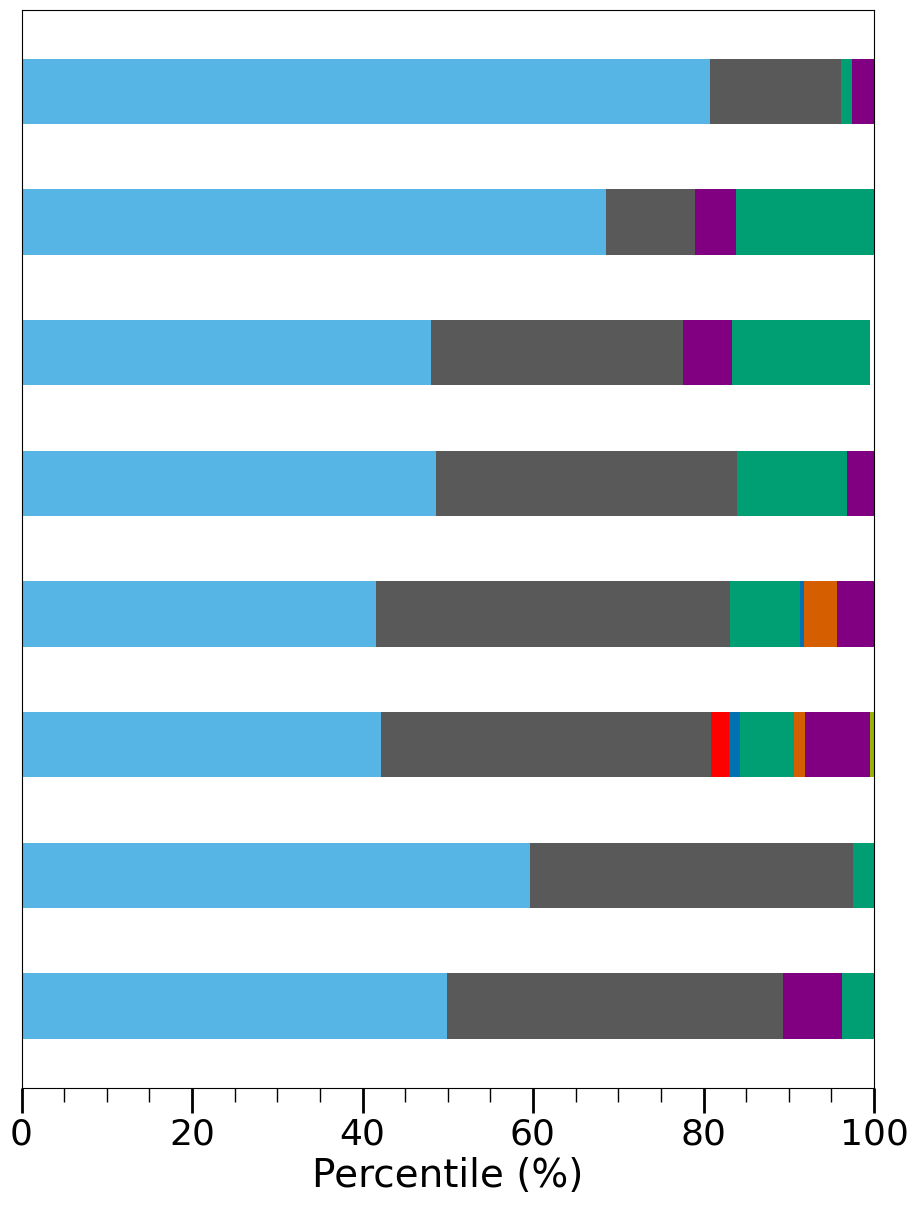

In [44]:
fig, ax = plt.subplots(figsize=(11,14))
test_group = [r'$10^{\prime}$ '+'smoothing (Euclid/LSST)', r'$10^{\prime}$ '+'smoothing (DES)', r'$10^{\prime}$ '+' smoothing and \ntuned filter size, \ncorrelation order', r'$10^{\prime}$ '+' smoothing and \ntuned correlation order', r'$10^{\prime}$ '+'smoothing', r'$20^{\prime}$ '+'smoothing', r'$30^{\prime}$ '+'smoothing', r'$40^{\prime}$ '+'smoothing']
start = np.array([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0])
c2 = np.array([49.87, 59.63, 42.17, 41.55, 48.58, 48.09, 68.54, 80.8]) 
c3 = np.array([39.42, 37.85, 38.76, 41.55, 35.36, 29.49, 10.49, 15.33])

test_group1 = [r'$10^{\prime}$ '+'smoothing', r'$40^{\prime}$ '+'smoothing']
start1 = np.array([0.0, 0.0])
c1_1 = np.array([12.94, 1.34])
c2_1 = np.array([48.58, 80.8])
c3_1 = np.array([35.36, 15.33])
c4_1 = np.array([3.12, 2.53])

test_group2 = [r'$10^{\prime}$ '+'smoothing (Euclid/LSST)', r'$10^{\prime}$ '+'smoothing (DES)', r'$20^{\prime}$ '+'smoothing', r'$30^{\prime}$ '+'smoothing']
start2 = np.array([0.0, 0.0, 0.0, 0.0])
c1_2 = np.array([3.81, 2.52, 16.14, 16.23])
c2_2 = np.array([49.87, 59.63, 48.09, 68.54])
c3_2 = np.array([39.42, 37.85, 29.49, 10.49])
c4_2 = np.array([6.90, 0.0, 5.79, 4.75])

test_group3 = [r'$10^{\prime}$ '+' smoothing and \ntuned filter size, \ncorrelation order']
start3 = np.array([0])
c1_3 = np.array([6.38])
c2_3 = np.array([42.17])
c3_3 = np.array([38.76])
c4_3 = np.array([7.66])
c5_3 = np.array([1.29])
c6_3 = np.array([1.29])
c7_3 = np.array([2.03])
c8_3 = np.array([0.43])

test_group4 = [r'$10^{\prime}$ '+' smoothing and \ntuned correlation order']
start4 = np.array([0])
c1_4 = np.array([8.23])
c2_4 = np.array([41.55])
c3_4 = np.array([41.55])
c4_4 = np.array([4.32])
c5_4 = np.array([0.43])
c6_4 = np.array([3.91])
#c7_4 = np.array([0.26])
#c8_4 = np.array([0.34])

height = np.array([0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5])
height1 = np.array([0.5, 0.5])
height2 = np.array([0.5, 0.5, 0.5, 0.5])
height3 = np.array([0.5])
height4 = np.array([0.5])

b1 = ax.barh(test_group, c2, left=start, color="#56b5e5", height=height)
b2 = ax.barh(test_group, c3, left=c2+start, color="#595959", height=height)
b3_1 = ax.barh(test_group1, c1_1, left=c2_1+c3_1+start1, color="#009f73", height=height1)
b4_1 = ax.barh(test_group1, c4_1, left=c2_1+c3_1+c1_1+start1, color='#810081', height=height1)
b3_2 = ax.barh(test_group2, c4_2, left=c2_2+c3_2+start2, color='#810081', height=height2)
b4_2 = ax.barh(test_group2, c1_2, left=c2_2+c3_2+c4_2+start2, color='#009f73', height=height2)

b7_3 = ax.barh(test_group3, c7_3, left=c2_3+c3_3+start3, color='red', height=height3) 
b5_3 = ax.barh(test_group3, c5_3, left=c2_3+c3_3+c7_3+start3, color='#0072b1', height=height3) 
b1_3 = ax.barh(test_group3, c1_3, left=c2_3+c3_3+c7_3+c5_3+start3, color='#009f73', height=height3) 
b6_3 = ax.barh(test_group3, c6_3, left=c2_3+c3_3+c7_3+c5_3+c1_3+start3, color='#d55e00', height=height3) 
b4_3 = ax.barh(test_group3, c4_3, left=c2_3+c3_3+c7_3+c5_3+c1_3+c6_3+start3, color='#810081', height=height3) 
b8_3 = ax.barh(test_group3, c8_3, left=c2_3+c3_3+c7_3+c5_3+c1_3+c6_3+c4_3+start3, color='#96b403', height=height3) 

b7_4 = ax.barh(test_group4, c1_4, left=c2_4+c3_4+start4, color="#009f73", height=height4)
b8_4 = ax.barh(test_group4, c5_4, left=c1_4+c2_4+c3_4+start4, color='#0072b1', height=height4)
b9_4 = ax.barh(test_group4, c6_4, left=c5_4+c1_4+c2_4+c3_4+start4, color='#d55e00', height=height4)
b10_4 = ax.barh(test_group4, c4_4, left=c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='#810081', height=height4)
#b11_4 = plt.barh(test_group4, c7_4, left=c4_4+c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='red', height=height4)
#b12_4 = plt.barh(test_group4, c8_4, left=c7_4+c4_4+c5_4+c6_4+c1_4+c2_4+c3_4+start4, color='#96b403', height=height4)

#plt.legend([b3_1, b1, b2, b4_1, b9_4, b8_4, b11_4, b12_4], [r"$c_1^{(1)}$", r"$c_1^{(2)}$", r"$c_1^{(3)}$", r"$c_1^{(4)}$", r"$c_1^{(5)}$", r"$c_1^{(6)}$", r"$c_1^{(7)}$", r"$c_1^{(8)}$"], loc="upper right", frameon=False, fontsize=20, ncols=2)
#ax.legend([b3_1, b1, b2, b4_1, b8_4, b9_4], [r"$c_1^{(1)}$", r"$c_1^{(2)}$", r"$c_1^{(3)}$", r"$c_1^{(4)}$", r"$c_1^{(5)}$", r"$c_1^{(6)}$"], loc="upper right", frameon=False, fontsize=26, ncols=2)
ax.minorticks_on()
ax.set_xlabel('Percentile (%)', fontsize=28)
ax.set_xlim(left=0.0, right=100.0)
ax.get_yticklabels()[0].set_color("blue")
ax.get_yticklabels()[1].set_color("orange")
ax.tick_params(axis='x', which='major', length=18.0, width=2.0, labelsize=26)
ax.tick_params(axis='y', which='major', length=10.0, width=2.0, labelsize=22)
ax.set_yticks([])
ax.tick_params(axis='x', which='minor', length=10.0, width=1.0)
ax.tick_params(axis='y', which='minor', length=0.0, width=1.0)

#plt.show()
plt.savefig('paper_plot/ccnn_on_w0_percentile.pdf', format='pdf', dpi=300, bbox_inches='tight')

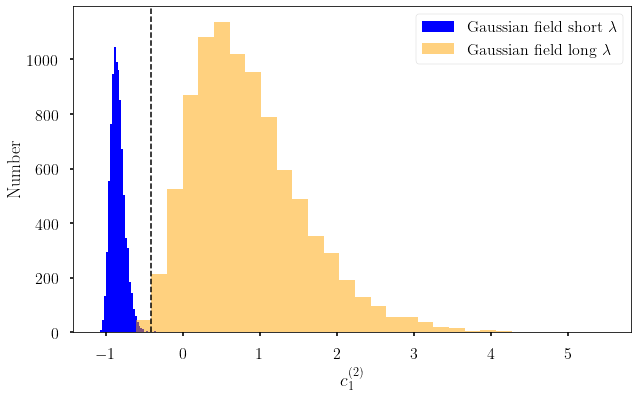

In [102]:
x_decision = β_αs[:, 1][np.nonzero(-β_αs[:, 0])[0][0]]
intercep_decision = β_αs_intercept[np.nonzero(-β_αs[:, 0])[0][0]]
x = -intercep_decision/x_decision
plt.figure(figsize=(10, 6))
labelA = ['Gaussian field', 'Gaussian field short '+r'$\lambda$', r'$M_{\nu} = 0.0$ '+'eV']
labelB = ['Log-normal field', 'Gaussian field long '+r'$\lambda$', r'$M_{\nu} = 0.1$ '+'eV']

#plt.hist(train_cαs_A_norm[:,1], bins=30, color='blue', label='Gaussian field')
#plt.hist(train_cαs_B_norm[:,1], bins=30, color='orange', alpha=0.5, label='Log-normal field')
plt.hist(train_cαs_A_norm[:,1], bins=30, color='blue', label=labelA[1])
plt.hist(train_cαs_B_norm[:,1], bins=30, color='orange', alpha=0.5, label=labelB[1])
plt.axvline(x, linestyle='--', color='black', lw=1.5)
#axs[0,0].tick_params(labelsize=12)
plt.xlabel(r'$c^{(2)}_1$', fontsize=18)
plt.ylabel('Number', fontsize=18)
plt.legend(fontsize=16)
# plt.margins(0.1) # Uncomment this if hex bins are partially outside of plot limits

plt.show()

In [39]:
error_classification_A = []
error_classification_B = []
for i in range(train_cαs_A_norm.shape[0]):
    if (train_cαs_A_norm[i,1] > -intercep_decision/x_decision):
        error_classification_A.append(1)
        
for i in range(train_cαs_B_norm.shape[0]):
    if (train_cαs_B_norm[i,1] < -intercep_decision/x_decision):
        error_classification_B.append(1)

In [40]:
1 - (len(error_classification_A)+len(error_classification_B))/(2*train_cαs_A_norm.shape[0])

0.42960328925436164

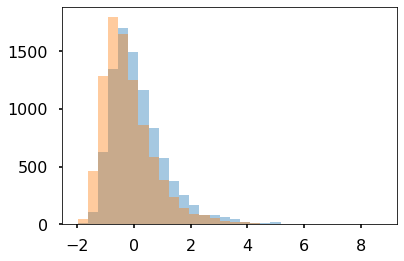

In [41]:
rng = min(train_cαs_A_norm[:,1].min(), train_cαs_B_norm[:,1].min()), max(train_cαs_A_norm[:,1].max(), train_cαs_B_norm[:,1].max())
n1, bins1, _ = plt.hist(train_cαs_A_norm[:,1], alpha=0.4, bins=30, range=rng)
n2, bins2, _ = plt.hist(train_cαs_B_norm[:,1], alpha=0.4, bins=30, range=rng)

7498.0
The classification accuracy between 2 classes from this correlation estimator is 0.5833981553505945


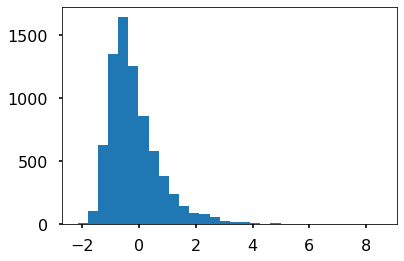

In [42]:
intersection = np.minimum(n1, n2)
area = intersection.sum()
print(area)
plt.bar(bins1[:-1], intersection, width=bins1[1]- bins1[0])
#print('The overlapping fraction between 2 classes for this correlation estimator is', area/train_cαs.shape[0])
print('The classification accuracy between 2 classes from this correlation estimator is', 1.0 - area/train_cαs.shape[0])

In [23]:
β_αs[:, 2][np.nonzero(-β_αs[:, 1])[0][0]]

0.0

In [25]:
np.nonzero(-β_αs[:, 1])[0][0]

641

In [24]:
-x_decision_4/y_decision_4

0.8683925307814199

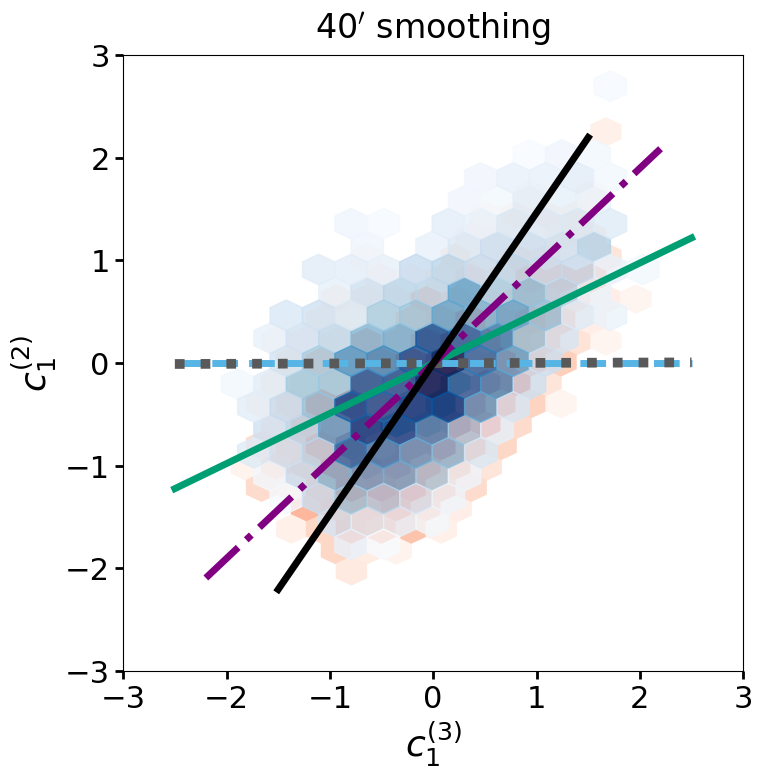

In [23]:
x_decision_1 = β_αs[:, 2][np.nonzero(-β_αs[:, 1])[0][0]]
y_decision_1 = β_αs[:, 1][np.nonzero(-β_αs[:, 1])[0][0]+1]
intercep_decision_1 = β_αs_intercept[np.nonzero(-β_αs[:, 1])[0][0]]
x_1 = np.linspace(-2.5, 2.5, 100)
y_1 = -x_decision_1/y_decision_1*x_1 - intercep_decision_1/y_decision_1

x_decision_2 = β_αs[:, 2][np.nonzero(-β_αs[:, 2])[0][0]]
y_decision_2 = β_αs[:, 1][np.nonzero(-β_αs[:, 2])[0][0]]
intercep_decision_2 = β_αs_intercept[np.nonzero(-β_αs[:, 2])[0][0]]
x_2 = np.linspace(-2.5, 2.5, 100)
y_2 = -x_decision_2/y_decision_2*x_2 - intercep_decision_2/y_decision_2

x_decision_3 = β_αs[:, 2][np.nonzero(-β_αs[:, 0])[0][0]]
y_decision_3 = β_αs[:, 1][np.nonzero(-β_αs[:, 0])[0][0]]
intercep_decision_3 = β_αs_intercept[np.nonzero(-β_αs[:, 0])[0][0]]
x_3 = np.linspace(-2.5, 2.5, 100)
y_3 = -x_decision_3/y_decision_3*x_3 - intercep_decision_3/y_decision_3

x_decision_4 = β_αs[:, 2][np.nonzero(-β_αs[:, 3])[0][0]]
y_decision_4 = β_αs[:, 1][np.nonzero(-β_αs[:, 3])[0][0]]
intercep_decision_4 = β_αs_intercept[np.nonzero(-β_αs[:, 3])[0][0]]
x_4 = np.linspace(-2.2, 2.2, 100)
y_4 = (-x_decision_4/y_decision_4)*x_4 - intercep_decision_4/y_decision_4

x_decision_last = β_αs[:, 2][-1]
y_decision_last = β_αs[:, 1][-1]
intercep_decision_last = β_αs_intercept[-1]
x_last = np.linspace(-1.5, 1.5, 100)
y_last = -x_decision_last/y_decision_last*x_last - intercep_decision_last/y_decision_last

plt.figure(figsize=(8, 8))
hist1 = plt.hexbin(train_cαs_A_norm[:,2], train_cαs_A_norm[:,1], gridsize=30, cmap='Reds', mincnt=10, alpha=1.0)
hist2 = plt.hexbin(train_cαs_B_norm[:,2], train_cαs_B_norm[:,1], gridsize=30, cmap='Blues', mincnt=10, alpha=0.8)
plt.plot(x_3, y_3, linestyle='-', color='#009f73', lw=5.0, label='decision boundary at '+r'$\beta_{1}^{(1)}$'+' activation')
plt.plot(x_1, y_1, linestyle='--', color='#56b5e5', lw=5.0, label='decision boundary at '+r'$\beta_{1}^{(2)}$'+' activation')
plt.plot(x_2, y_2, linestyle='dotted', color='#595959', lw=7.0, label='decision boundary at '+r'$\beta_{1}^{(3)}$'+' activation')
plt.plot(x_4, y_4, linestyle='dashdot', color='#810081', lw=5.0, label='decision boundary at '+r'$\beta_{1}^{(4)}$'+' activation')
plt.plot(x_last, y_last, linestyle='-', color='black', lw=5.0, label='decision boundary at the last '+r'$\lambda$'+' value')
#plt.colorbar(hist1, orientation='vertical', label='Gaussian random field')
#plt.colorbar(hist2, orientation='vertical', label='Log-normal random field')
#tick_font_size = 22
#cbar = plt.colorbar(hist1, orientation='vertical')
#cbar.ax.tick_params(labelsize=tick_font_size)
#cbar.set_label(r'$w_0=-0.95$',size=26, labelpad=0.1)
#cbar1 = plt.colorbar(hist2, orientation='vertical')
#cbar1.ax.tick_params(labelsize=tick_font_size)
#cbar1.set_label(r'$w_0=-1.05$',size=26, labelpad=0.1)

#plt.colorbar(hist1, orientation='vertical', label=r'$\kappa$ '+'only')
#plt.colorbar(hist2, orientation='vertical', label=r'$A_{IA}=0.36$ '+r'$\alpha=1.66$')
plt.xlabel(r'$c^{(3)}_1$', fontsize=26)
plt.ylabel(r'$c^{(2)}_1$', fontsize=26)
plt.xlim([-3.0, 3.0])
plt.ylim([-3.0, 3.0])
plt.tick_params(labelsize=22, length=6.0, width=2.0)
#plt.yticks(color='w')
#plt.legend(fontsize=26, frameon=False, loc='center left', bbox_to_anchor=(1.6, 0.5))
# plt.margins(0.1) # Uncomment this if hex bins are partially outside of plot limits

plt.title(r'$40^{\prime}$'+' smoothing', fontsize=24, pad=12.0)
#plt.title('no smoothing', fontsize=24, pad=12.0)

#plt.show()
plt.savefig('paper_plot/noiseless_w0_40arcmin_smoothing_c2_c3_contour.pdf', format='pdf', dpi=300, bbox_inches='tight')

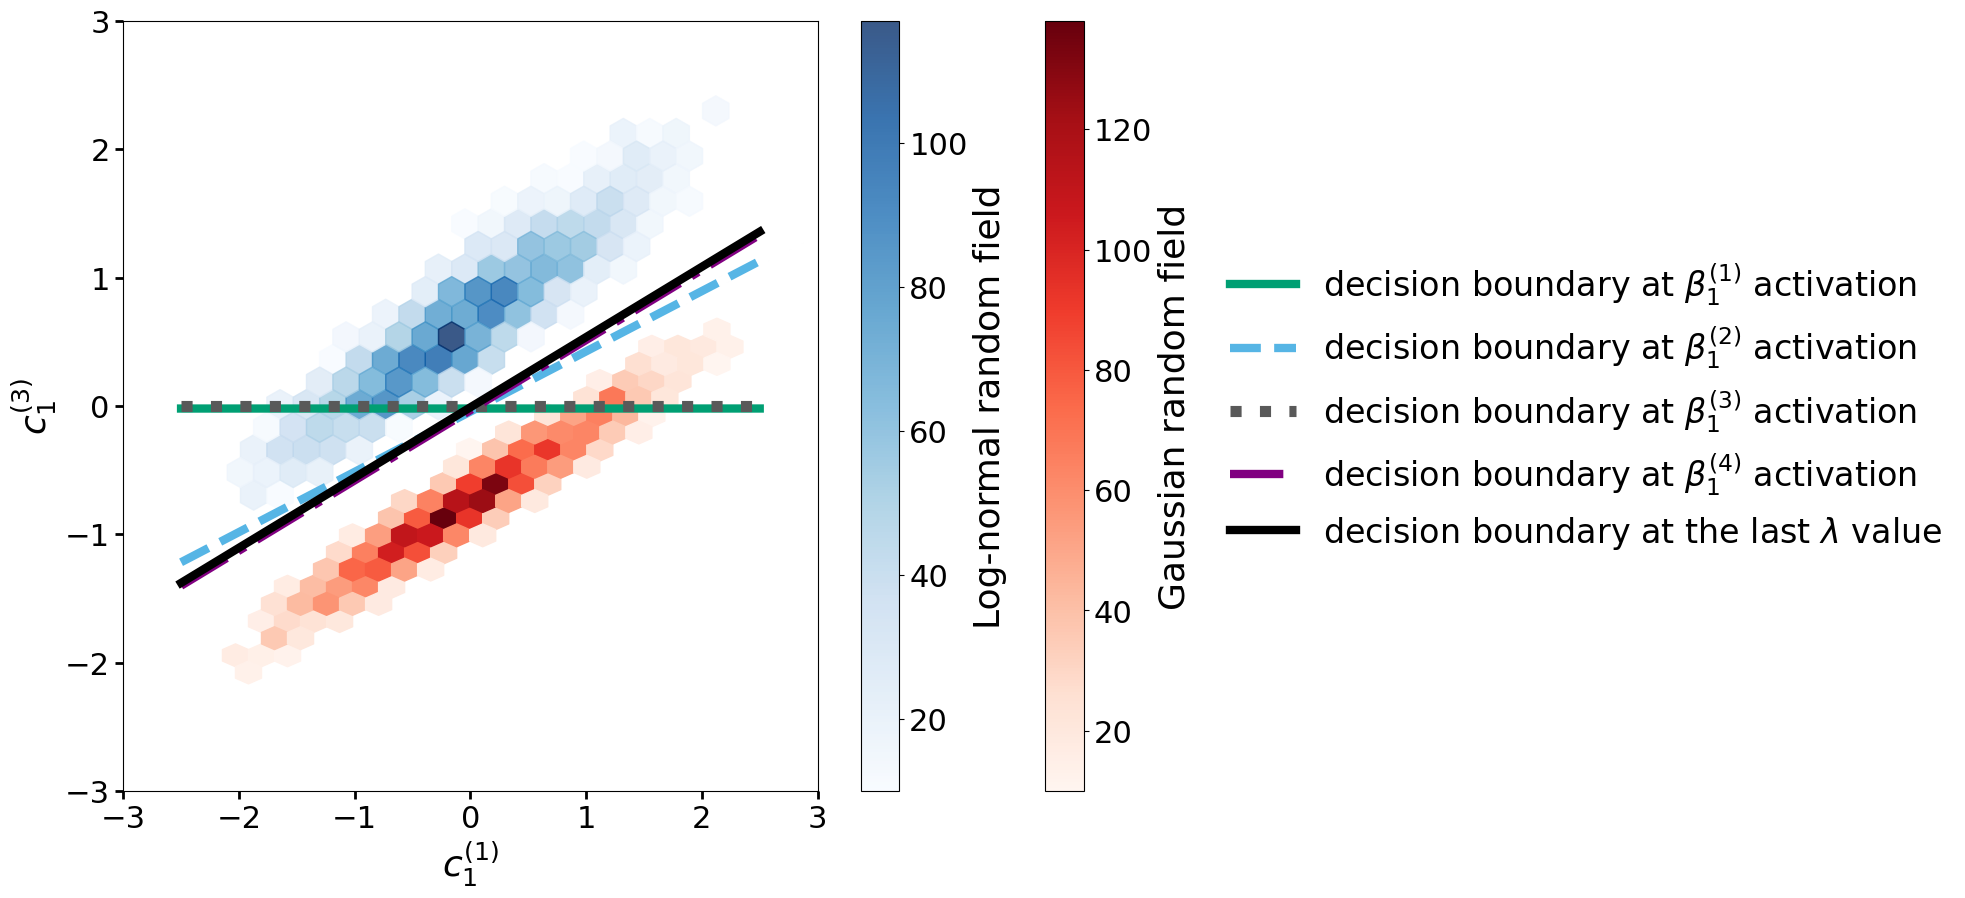

In [22]:
x_decision_1 = β_αs[:, 0][np.nonzero(-β_αs[:, 1])[0][0]]
y_decision_1 = β_αs[:, 2][np.nonzero(-β_αs[:, 1])[0][0]+1]
intercep_decision_1 = β_αs_intercept[np.nonzero(-β_αs[:, 1])[0][0]]
x_1 = np.linspace(-2.5, 2.5, 100)
y_1 = -x_decision_1/y_decision_1*x_1 - intercep_decision_1/y_decision_1

x_decision_2 = β_αs[:, 0][np.nonzero(-β_αs[:, 2])[0][0]]
y_decision_2 = β_αs[:, 2][np.nonzero(-β_αs[:, 2])[0][0]]
intercep_decision_2 = β_αs_intercept[np.nonzero(-β_αs[:, 2])[0][0]]
x_2 = np.linspace(-2.5, 2.5, 100)
y_2 = -x_decision_2/y_decision_2*x_2 - intercep_decision_2/y_decision_2

x_decision_3 = β_αs[:, 0][np.nonzero(-β_αs[:, 0])[0][0]]
y_decision_3 = β_αs[:, 2][np.nonzero(-β_αs[:, 0])[0][0]]
intercep_decision_3 = β_αs_intercept[np.nonzero(-β_αs[:, 0])[0][0]]
x_3 = np.linspace(-2.5, 2.5, 100)
y_3 = -x_decision_3/y_decision_3*x_3 - intercep_decision_3/y_decision_3

x_decision_4 = β_αs[:, 0][np.nonzero(-β_αs[:, 3])[0][0]]
y_decision_4 = β_αs[:, 2][np.nonzero(-β_αs[:, 3])[0][0]]
intercep_decision_4 = β_αs_intercept[np.nonzero(-β_αs[:, 3])[0][0]]
x_4 = np.linspace(-2.5, 2.5, 100)
y_4 = -x_decision_4/y_decision_4*x_4 - intercep_decision_4/y_decision_4

x_decision_last = β_αs[:, 0][-1]
y_decision_last = β_αs[:, 2][-1]
intercep_decision_last = β_αs_intercept[-1]
x_last = np.linspace(-2.5, 2.5, 100)
y_last = -x_decision_last/y_decision_last*x_last - intercep_decision_last/y_decision_last

plt.figure(figsize=(14, 10))
hist1 = plt.hexbin(train_cαs_A_norm[:,0], train_cαs_A_norm[:,2], gridsize=30, cmap='Reds', mincnt=10, alpha=1.0)
hist2 = plt.hexbin(train_cαs_B_norm[:,0], train_cαs_B_norm[:,2], gridsize=30, cmap='Blues', mincnt=10, alpha=0.8)
plt.plot(x_3, y_3, linestyle='-', color='#009f73', lw=6.0, label='decision boundary at '+r'$\beta_{1}^{(1)}$'+' activation')
plt.plot(x_1, y_1, linestyle='--', color='#56b5e5', lw=6.0, label='decision boundary at '+r'$\beta_{1}^{(2)}$'+' activation')
plt.plot(x_2, y_2, linestyle='dotted', color='#595959', lw=8.0, label='decision boundary at '+r'$\beta_{1}^{(3)}$'+' activation')
plt.plot(x_4, y_4, linestyle='dashdot', color='#810081', lw=6.0, label='decision boundary at '+r'$\beta_{1}^{(4)}$'+' activation')
plt.plot(x_last, y_last, linestyle='-', color='black', lw=6.0, label='decision boundary at the last '+r'$\lambda$'+' value')
#plt.colorbar(hist1, orientation='vertical', label='Gaussian random field')
#plt.colorbar(hist2, orientation='vertical', label='Log-normal random field')
tick_font_size = 22
cbar = plt.colorbar(hist1, orientation='vertical')
cbar.ax.tick_params(labelsize=tick_font_size)
cbar.set_label('Gaussian random field',size=26)
cbar1 = plt.colorbar(hist2, orientation='vertical')
cbar1.ax.tick_params(labelsize=tick_font_size)
cbar1.set_label('Log-normal random field',size=26)

#plt.colorbar(hist1, orientation='vertical', label=r'$\kappa$ '+'only')
#plt.colorbar(hist2, orientation='vertical', label=r'$A_{IA}=0.36$ '+r'$\alpha=1.66$')
plt.xlabel(r'$c^{(1)}_1$', fontsize=26)
plt.ylabel(r'$c^{(3)}_1$', fontsize=26)
plt.xlim([-3.0, 3.0])
plt.ylim([-3.0, 3.0])
plt.tick_params(labelsize=22, length=6.0, width=2.0)
#plt.yticks(color='w')
plt.legend(fontsize=24, frameon=False, loc='center left', bbox_to_anchor=(1.55, 0.5))
# plt.margins(0.1) # Uncomment this if hex bins are partially outside of plot limits

#plt.title(r'$10^{\prime}$'+' smoothing', fontsize=24, pad=12.0)
#plt.title('no smoothing', fontsize=24, pad=12.0)

#plt.show()
plt.savefig('paper_plot/grf_lognormal_c1_c3_contour.pdf', format='pdf', dpi=300, bbox_inches='tight')

In [31]:
error_classification_A = []
error_classification_B = []
for i in range(train_cαs_A_norm.shape[0]):
    if (train_cαs_A_norm[i,0] < -x_decision_1/y_decision_1*train_cαs_A_norm[i,2] - intercep_decision_1/y_decision_1):
        error_classification_A.append(1)
        
for i in range(train_cαs_B_norm.shape[0]):
    if (train_cαs_B_norm[i,0] > -x_decision_1/y_decision_1*train_cαs_B_norm[i,2] - intercep_decision_1/y_decision_1):
        error_classification_B.append(1)

In [32]:
1 - (len(error_classification_A)+len(error_classification_B))/(2*train_cαs_A_norm.shape[0])

0.7871934434434434

### Use Chainconsumer to plot the measured correlation features

In [21]:
from chainconsumer import ChainConsumer

In [63]:
random_3d_vec = np.random.uniform(-3.0, 5.0, (10000000, 3))
c1 = (-β_αs_intercept[-1] - β_αs[:,1][-1]*random_3d_vec[:,0] - β_αs[:,2][-1]*random_3d_vec[:,1] - β_αs[:,3][-1]*random_3d_vec[:,2])/β_αs[:,0][-1]
hyperplane = np.concatenate((c1.reshape(-1,1), random_3d_vec), axis=1)

In [20]:
train_cαs_A = np.load('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_gaussian_6300maps_w_model_on_20deg_200pix.npy')
train_cαs_C = np.load('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_gaussian_6300maps_10deg_100pix_w_model_on_20deg_200pix.npy')
train_cαs_E = np.load('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_gaussian_1800maps_40deg_400pix_w_model_on_20deg_200pix.npy')

train_cαs_B = np.load('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_lognormal_6300maps_w_model_on_20deg_200pix.npy')
train_cαs_D = np.load('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_lognormal_6300maps_10deg_100pix_w_model_on_20deg_200pix.npy')
train_cαs_F = np.load('optuna_ccnn/python_scripts/map_and_filter_size_impact/c_distribution_lognormal_1800maps_40deg_400pix_w_model_on_20deg_200pix.npy')

In [25]:
#correlation_gaussian_filter = train_cαs_A
#correlation_gaussian_filter_l = train_cαs_B
#correlation_gaussian_filter_s = train_cαs_C
#correlation_lognormal_filter = train_cαs_D
#correlation_lognormal_filter_l = train_cαs_E
#correlation_lognormal_filter_s = train_cαs_F

#correlation_gaussian = train_cαs_A
#correlation_gaussian_s = train_cαs_C[:,1::2]
#correlation_gaussian_l = train_cαs_E[:,1::2]
#correlation_lognormal = train_cαs_B
#correlation_lognormal_s = train_cαs_D
#correlation_lognormal_l = train_cαs_F

correlation_grf_lambda5 = train_cαs_A[:,:3]
correlation_grf_lambda20 = train_cαs_B[:,:3]

#correlation_gaussian = train_cαs_A
#correlation_lognormal = train_cαs_B

#correlation_no_IA = train_cαs_A
#correlation_IA_Aamp = train_cαs_B

In [42]:
label = ['Gaussian random field', 'Gaussian random field larger map', 'Gaussian random field larger filter', 'Gaussian random field smaller filter', 'Log-normal random field', 'Log-normal random field larger map', 'Log-normal random field larger filter', 'Log random field smaller filter', 'Gaussian random field short '+r'$\lambda$', 'smaller Gaussian random field short '+r'$\lambda$', 'Gaussian random field middle '+r'$\lambda$', 'Gaussian random field long '+r'$\lambda$', r'$M_{\nu} = 0.0$ '+'eV', r'$M_{\nu} = 0.1$ '+'eV']

c = ChainConsumer()
#c.add_chain(correlation_gaussian_filter, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Gaussian map filter 31 pixels', shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=2.0)
#c.add_chain(correlation_gaussian_filter_l, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Gaussian map filter 51 pixels', shade=True, shade_alpha=0.1, color='r', linestyle='--', linewidth=1.0, kde=2.0)
#c.add_chain(correlation_gaussian_filter_s, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Gaussian map filter 11 pixels', shade=True, shade_alpha=0.1, color='blue', linestyle='--', linewidth=1.0, kde=2.0)


c.add_chain(correlation_grf_lambda5, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$"], name='$\ell=5.0$', shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=2.0)
c.add_chain(correlation_grf_lambda20, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$"], name='$\ell=20.0$', shade=True, shade_alpha=0.1, color='blue', linestyle='--', linewidth=1.0, kde=2.0)
c.add_marker(np.array([0.0, 0.199, 0.0]), parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$"], marker_style="*", marker_size=100, color="red", name='theory prediction '+'$\ell=5.0$')
c.add_marker(np.array([0.0, 1.049, 0.0]), parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$"], marker_style="*", marker_size=100, color="orange", name='theory prediction '+'$\ell=20.0$')
#c.add_chain(correlation_lambda1, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Log-normal map with initial '+r'$\lambda$', shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=2.0)
#c.add_chain(correlation_lambda2, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Log-normal map with modified '+r'$\lambda$', shade=True, shade_alpha=0.1, color='r', linestyle='--', linewidth=1.0, kde=2.0)

#c.add_chain(correlation_no_IA, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name=r'$\kappa$ '+'only', shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=2.0)
#c.add_chain(correlation_IA_Aamp, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name=r'$\kappa$ + '+'IA with '+r'$A_{IA}=0.36$, '+r'$\alpha=1.66$', shade=True, shade_alpha=0.1, color='r', linestyle='--', linewidth=1.0, kde=2.0)

#c.add_chain(correlation_lognormal, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Log-normal map size 20 degree', shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=2.0)
#c.add_chain(correlation_lognormal_s, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Log-normal map size 10 degree', shade=True, shade_alpha=0.1, color='r', linestyle='--', linewidth=1.0, kde=2.0)
#c.add_chain(correlation_lognormal_l, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Log-normal map size 40 degree', shade=True, shade_alpha=0.1, color='blue', linestyle='--', linewidth=1.0, kde=2.0)

#c.add_chain(correlation_gaussian, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Gaussian random fields', shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=2.0)
#c.add_chain(correlation_lognormal, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='Log-normal random fields', shade=True, shade_alpha=0.1, color='r', linestyle='--', linewidth=1.0, kde=2.0)
#c.add_marker(np.array([0.0, 2.414e-4, 0.0, 1.315e-08]), parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], marker_style="*", marker_size=80, color="orange", name='theory prediction for Gaussian')
#c.add_marker(np.array([0.0, 2.414e-4, 8.078e-07, 1.613e-08]), parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], marker_style="*", marker_size=80, color="blue", name='theory prediction for Log-normal')
#c.add_chain(correlation_s, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name=label[2], shade=True, shade_alpha=0.7, color='g', linestyle='-', linewidth=2.0, kde=False)
#c.add_chain(correlation_s1, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name=label[3], shade=True, shade_alpha=0.1, color='purple', linestyle='--', linewidth=1.5, kde=False)
#c.add_chain(correlation_m, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name=label[4], shade=True, shade_alpha=0.1, color='b', linestyle='--', linewidth=1.0, kde=False)
#c.add_chain(correlation_l, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name=label[5], shade=True, shade_alpha=0.1, color='r', linestyle='--', linewidth=1.0, kde=False)
#c.add_chain(hyperplane, parameters=["$c_{1}^{(1)}$", "$c_{1}^{(2)}$", "$c_{1}^{(3)}$", "$c_{1}^{(4)}$"], name='decision hyperplane', shade=True, shade_alpha=0.1, color='black', linestyle='--', linewidth=2.0, kde=False)
#c.configure_truth(linestyle='dotted', linewidth=0.5)
c.configure(usetex=False, serif=False, label_font_size=20.0, tick_font_size=20.0, max_ticks=4, summary=False, spacing=2.0, legend_kwargs={'fontsize':20})

In [28]:
c.analysis.get_latex_table()

'\\begin{table}\n    \\centering\n    \\caption{}\n    \\label{tab:model_params}\n    \\begin{tabular}{ccccc}\n        \\hline\n\t\tModel & $c_{1}^{(1)}$ & $c_{1}^{(2)}$ & $c_{1}^{(3)}$ & $c_{1}^{(4)}$ \\\\ \n\t\t\\hline\n\t\tLog-normal map filter 31 pixels & $\\left( 0.0\\pm 1.1 \\right) \\times 10^{-4}$ & $\\left( 51.6^{+4.0}_{-3.7} \\right) \\times 10^{-8}$ & $\\left( 6.6^{+3.6}_{-3.5} \\right) \\times 10^{-11}$ & $\\left( 26.2^{+8.3}_{-7.0} \\right) \\times 10^{-15}$ \\\\ \n\t\tLog-normal map filter 51 pixels & $\\left( -0.2^{+6.9}_{-6.7} \\right) \\times 10^{-5}$ & $\\left( 21.5\\pm 1.7 \\right) \\times 10^{-8}$ & $\\left( 2.1^{+1.3}_{-1.2} \\right) \\times 10^{-11}$ & $\\left( 11.3^{+3.4}_{-3.0} \\right) \\times 10^{-15}$ \\\\ \n\t\tLog-normal map filter 11 pixels & $\\left( -0.1^{+2.5}_{-2.4} \\right) \\times 10^{-5}$ & $\\left( 28.8^{+2.3}_{-2.2} \\right) \\times 10^{-9}$ & $\\left( 10.1^{+6.0}_{-5.8} \\right) \\times 10^{-13}$ & $\\left( 17.7^{+5.5}_{-4.6} \\right) \\times 10^

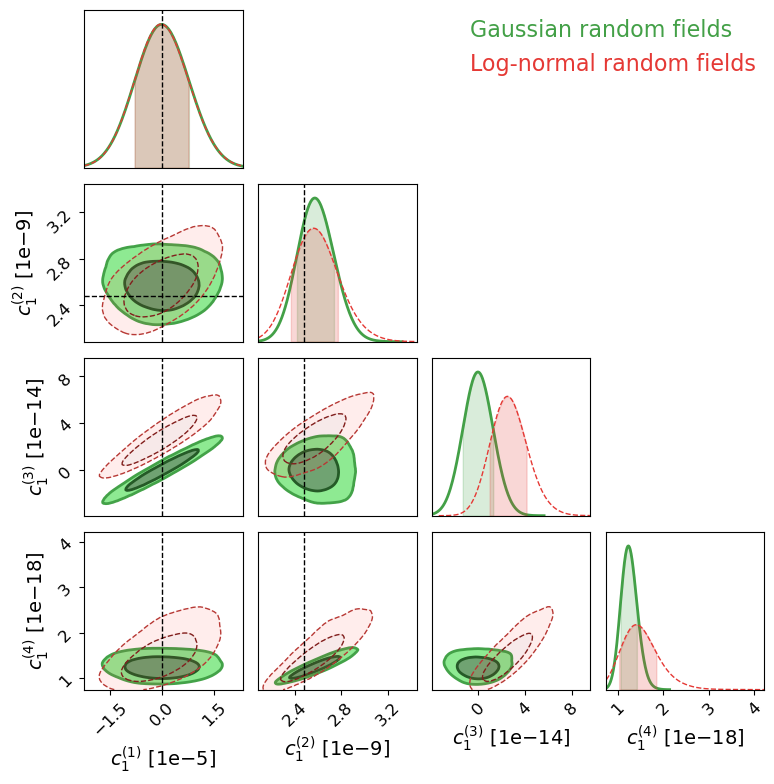

In [175]:
#extent = [(-1.0, 1.0), (min(correlation_s[:,1]), 0.45), (-0.2, 0.2), (min(correlation_s[:,3]), 0.045)]
#extent = [(-3.5e-5, 3.5e-5), (min(correlation_lognormal[:,1]), 4e-9), (min(correlation_lognormal[:,2]), 1.5e-13), (min(correlation_lognormal[:,3]), 1.5e-17)]
#fig = c.plotter.plot(figsize=(8, 8), legend=True, truth=[0.0, 5.083619078207578e-07, 6.324138410600967e-11, 2.5302002985655507e-14])
fig = c.plotter.plot(figsize=(8, 8), legend=True, truth=[0.0, 2.4795401943391353e-09, 6.324138410600967e-11, 2.5302002985655507e-14])

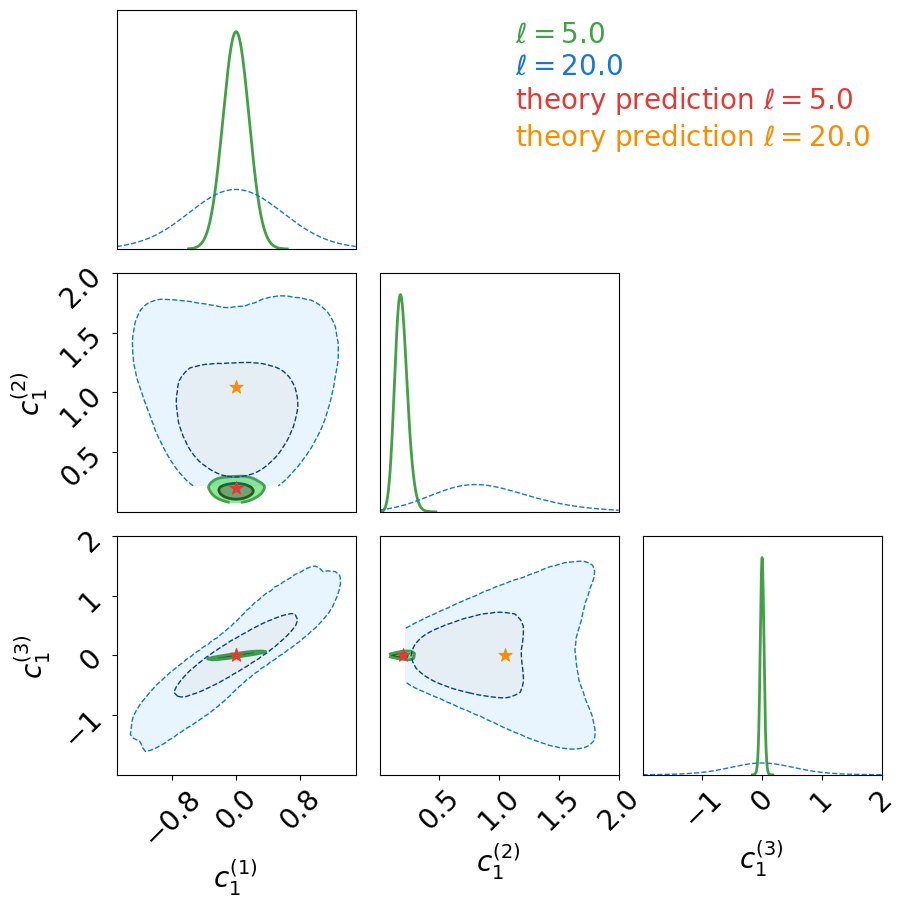

In [44]:
extent = [(-1.5, 1.5), (0, 2.0), (-2.0, 2.0)]
#extent = [(-6e-3, 6e-3), (1.8e-4, 3.2e-4), (-1.5e-6, 2.5e-6), [1e-8, 4e-8]]
fig = c.plotter.plot(figsize=(9, 9), legend=True, extents=extent, filename='paper_plot/corner_plots_grf_lognormal_up_to_c4_test.png')

In [40]:
min(correlation_lambda2[:,3])

-0.696254

In [ ]:
x_decision = β_αs[:, 2][-1]
y_decision = β_αs[:, 4][-1]
intercep_decision = β_αs_intercept[-1]
x = np.linspace(-4, 4, 100)
y = -x_decision/y_decision*x - intercep_decision/y_decision
plt.figure(figsize=(10, 6))
hist1 = plt.hexbin(train_cαs_A_norm[:,2], train_cαs_A_norm[:,4], gridsize=30, cmap='Reds', mincnt=10, alpha=1.0, label='Gaussian random field')
hist2 = plt.hexbin(train_cαs_B_norm[:,2], train_cαs_B_norm[:,4], gridsize=30, cmap='Blues', mincnt=10, alpha=0.5, label='Log-normal random field')
plt.plot(x, y, linestyle='--', color='black', lw=2.0, label='decision boundary')
plt.colorbar(hist1, orientation='vertical', label='Gaussian random field')
plt.colorbar(hist2, orientation='vertical', label='Log-normal random field')
plt.xlabel(r'$c^{(2)}_1$', fontsize=18)
plt.ylabel(r'$c^{(3)}_1$', fontsize=18)
#plt.legend(fontsize=16)
# plt.margins(0.1) # Uncomment this if hex bins are partially outside of plot limits

plt.show()

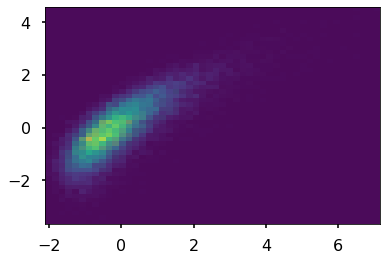

In [54]:
x_rng = [min(train_cαs_A_norm[:,3].min(), train_cαs_B_norm[:,3].min()), max(train_cαs_A_norm[:,3].max(), train_cαs_B_norm[:,3].max())]
y_rng = [min(train_cαs_A_norm[:,1].min(), train_cαs_B_norm[:,1].min()), max(train_cαs_A_norm[:,1].max(), train_cαs_B_norm[:,1].max())]
n1, x_bins1, y_bins1, _ = plt.hist2d(train_cαs_A_norm[:,3], train_cαs_A_norm[:,1], alpha=0.9, bins=50, range=[x_rng, y_rng])
n2, x_bins2, y_bins2, _ = plt.hist2d(train_cαs_B_norm[:,3], train_cαs_B_norm[:,1], alpha=0.6, bins=50, range=[x_rng, y_rng])

In [51]:
intersection = np.minimum(n1, n2)
volume = np.sum(intersection)
print(volume)
#plt.hist(intersection, bins=50, range=[x_rng, y_rng])
#print('The overlapping fraction between 2 classes for this correlation estimator is', area/train_cαs.shape[0])
print('The classification accuracy between 2 classes from this correlation estimator is', 1.0 - volume/train_cαs.shape[0])

5510.0
The classification accuracy between 2 classes from this correlation estimator is 0.6938548727636404


In [48]:
import itertools

two_point_weights = np.zeros((1, filter_size, filter_size, 1, filter_size, filter_size))
# An iterator which iterates over all *pairs* of pixels in the filter
pix_iter = itertools.product(
    range(1), range(filter_size), range(filter_size),
    range(1), range(filter_size), range(filter_size))

In [49]:
# Figure out which filter is the "active" one
active_filt_num = int(filters[1].max() > filters[0].max())
active_filt = filters[active_filt_num]

# Calculate the weight on each two-point correlator
for (ichan, ix, iy, jchan, jx, jy) in pix_iter:
    # Matrix is symmetric -- only compute upper triangle
    if (ichan, ix, iy) > (jchan, jx, jy):
        two_point_weights[ichan, ix, iy, jchan, jx, jy] = active_filt[ichan, ix, iy] * active_filt[jchan, jx, jy]

In [50]:
# Sort, collect the eight largest correlators measured (You can change this number!)
num_corr = 8
corr_idxs = np.argsort(two_point_weights.flatten())[-num_corr:][::-1]
corr_idxs = np.stack(np.unravel_index(corr_idxs, two_point_weights.shape), axis=1)
# Rescale correlators such that the largest has weight 1.0
two_point_weights /= two_point_weights.max()

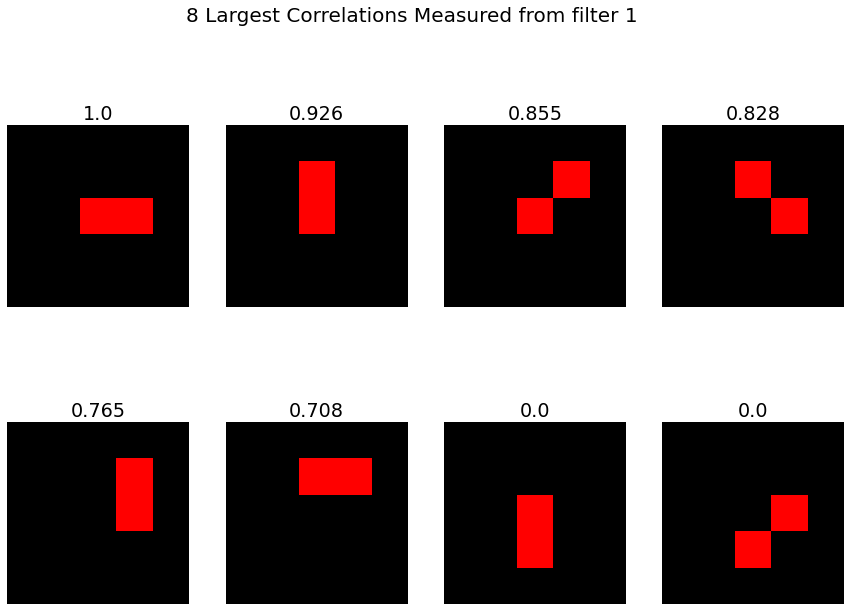

In [51]:
# Plot these!
fig, axs = plt.subplots(2, int(np.ceil(num_corr/2)), gridspec_kw={'wspace': 0.2}, figsize=(15, 10))
axs = axs.flatten()
fig.suptitle("{} Largest Correlations Measured from filter {}".format(num_corr, active_filt_num), y=1.0, fontsize=20)
for n, corr_idx in enumerate(corr_idxs):
    ichan, ix, iy, jchan, jx, jy = corr_idx
    corr_img = np.zeros((filter_size, filter_size, 3))
    icolor = [1.0, 0.0, 0.0] if ichan == 0 else [0.0, 0.0, 1.0]
    #iarrow = "↑" if ichan == 0 else "↓"
    jcolor = [1.0, 0.0, 0.0] if jchan == 0 else [0.0, 0.0, 1.0]
    #jarrow = "↑" if jchan == 0 else "↓"
    corr_img[ix, iy] = icolor
    corr_img[jx, jy] = jcolor
    axs[n].imshow(corr_img)
    #axs[n].text(iy, ix, iarrow, ha="center", va="center", fontsize=30)
    #axs[n].text(jy, jx, jarrow, ha="center", va="center", fontsize=30)
    axs[n].axis('off')
    axs[n].set_title(np.round(two_point_weights[ichan, ix, iy, jchan, jx, jy], decimals=3))
# Turn off axes of plots we're not using
for n in range(num_corr, 2 * int(np.ceil(num_corr/2))):
    axs[n].axis('off')
    
plt.show()

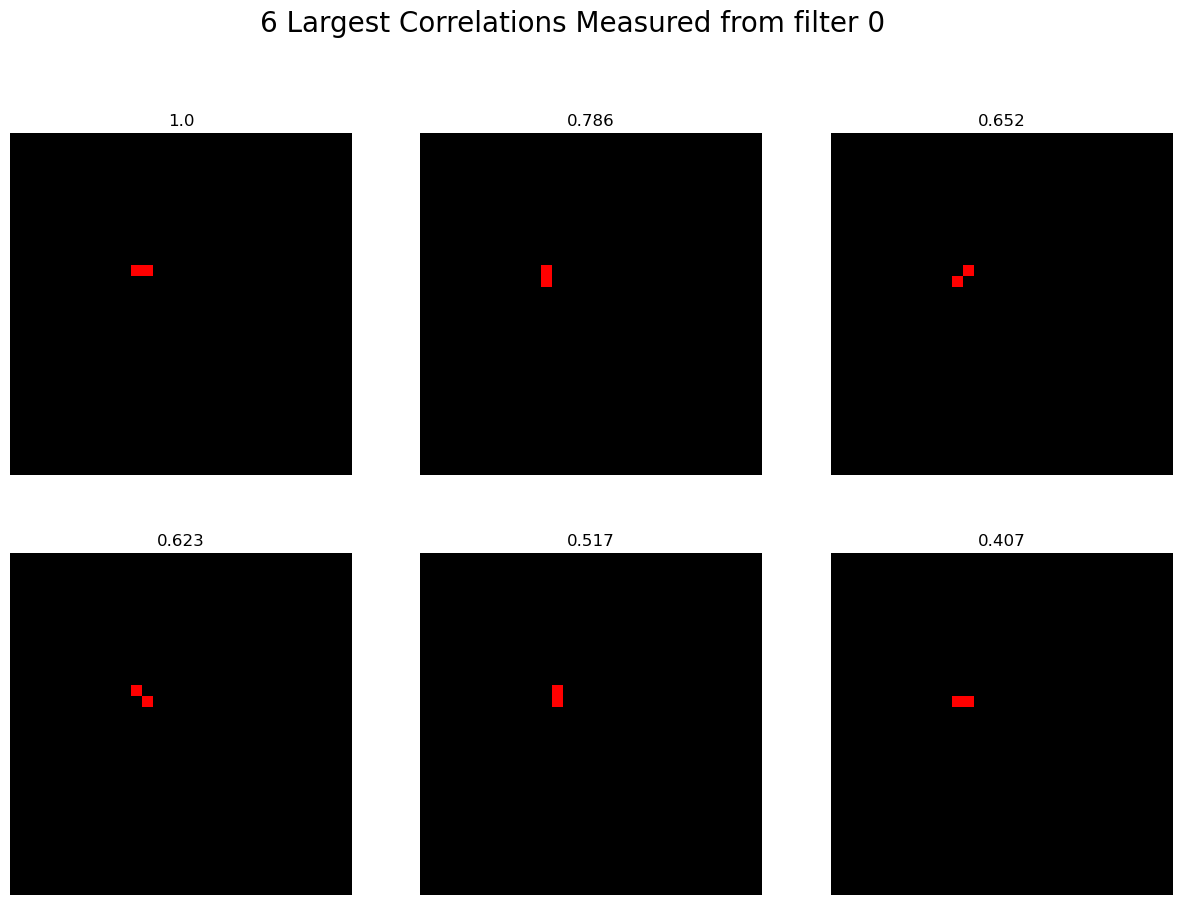

In [61]:
import itertools
active_filt_num = 0
active_filt = filters[active_filt_num]
filter_size = 31

two_point_weights = np.zeros((1, filter_size, filter_size, 1, filter_size, filter_size))
# An iterator which iterates over all *pairs* of pixels in the filter
pix_iter = itertools.product(
    range(1), range(filter_size), range(filter_size),
    range(1), range(filter_size), range(filter_size))
# Calculate the weight on each two-point correlator
for (ichan, ix, iy, jchan, jx, jy) in pix_iter:
    # Matrix is symmetric -- only compute upper triangle
    if (ichan, ix, iy) > (jchan, jx, jy):
        two_point_weights[ichan, ix, iy, jchan, jx, jy] = active_filt[ichan, ix, iy] * active_filt[jchan, jx, jy]
        
# Sort, collect the eight largest correlators measured (You can change this number!)
num_corr = 6
corr_idxs = np.argsort(two_point_weights.flatten())[-num_corr:][::-1]
corr_idxs = np.stack(np.unravel_index(corr_idxs, two_point_weights.shape), axis=1)
# Rescale correlators such that the largest has weight 1.0
two_point_weights /= two_point_weights.max()

# Plot these!
fig, axs = plt.subplots(2, int(np.ceil(num_corr/2)), gridspec_kw={'wspace': 0.2}, figsize=(15, 10))
axs = axs.flatten()
fig.suptitle("{} Largest Correlations Measured from filter {}".format(num_corr, active_filt_num), y=1.0, fontsize=20)
for n, corr_idx in enumerate(corr_idxs):
    ichan, ix, iy, jchan, jx, jy = corr_idx
    corr_img = np.zeros((filter_size, filter_size, 3))
    icolor = [1.0, 0.0, 0.0] if ichan == 0 else [0.0, 0.0, 1.0]
    #iarrow = "↑" if ichan == 0 else "↓"
    jcolor = [1.0, 0.0, 0.0] if jchan == 0 else [0.0, 0.0, 1.0]
    #jarrow = "↑" if jchan == 0 else "↓"
    corr_img[ix, iy] = icolor
    corr_img[jx, jy] = jcolor
    axs[n].imshow(corr_img)
    #axs[n].text(iy, ix, iarrow, ha="center", va="center", fontsize=30)
    #axs[n].text(jy, jx, jarrow, ha="center", va="center", fontsize=30)
    axs[n].axis('off')
    axs[n].set_title(np.round(two_point_weights[ichan, ix, iy, jchan, jx, jy], decimals=3))
# Turn off axes of plots we're not using
for n in range(num_corr, 2 * int(np.ceil(num_corr/2))):
    axs[n].axis('off')
    
plt.show()

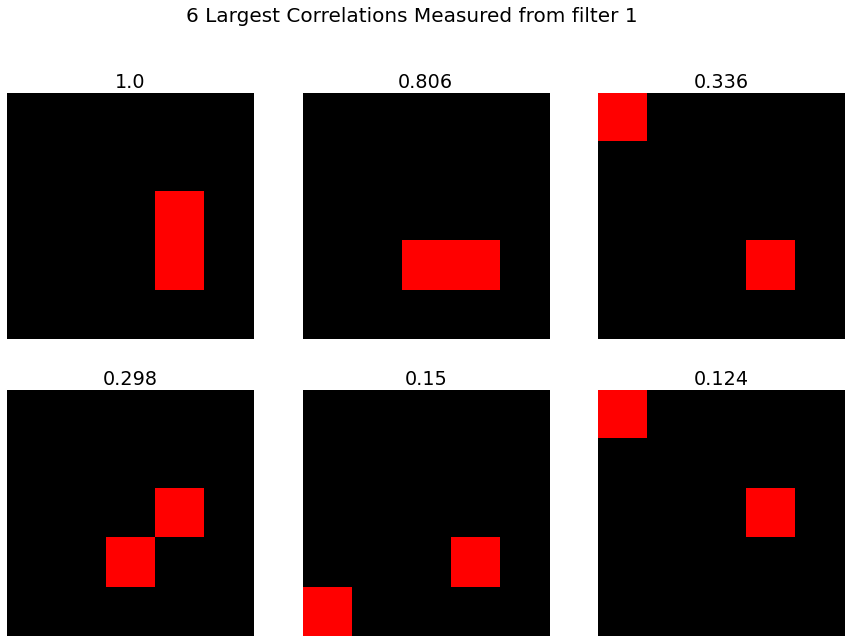

In [28]:
active_filt_num = 1
active_filt = filters[active_filt_num]

two_point_weights = np.zeros((1, filter_size, filter_size, 1, filter_size, filter_size))
# An iterator which iterates over all *pairs* of pixels in the filter
pix_iter = itertools.product(
    range(1), range(filter_size), range(filter_size),
    range(1), range(filter_size), range(filter_size))
# Calculate the weight on each two-point correlator
for (ichan, ix, iy, jchan, jx, jy) in pix_iter:
    # Matrix is symmetric -- only compute upper triangle
    if (ichan, ix, iy) > (jchan, jx, jy):
        two_point_weights[ichan, ix, iy, jchan, jx, jy] = active_filt[ichan, ix, iy] * active_filt[jchan, jx, jy]
        
# Sort, collect the eight largest correlators measured (You can change this number!)
num_corr = 6
corr_idxs = np.argsort(two_point_weights.flatten())[-num_corr:][::-1]
corr_idxs = np.stack(np.unravel_index(corr_idxs, two_point_weights.shape), axis=1)
# Rescale correlators such that the largest has weight 1.0
two_point_weights /= two_point_weights.max()

# Plot these!
fig, axs = plt.subplots(2, int(np.ceil(num_corr/2)), gridspec_kw={'wspace': 0.2}, figsize=(15, 10))
axs = axs.flatten()
fig.suptitle("{} Largest Correlations Measured from filter {}".format(num_corr, active_filt_num), y=1.0, fontsize=20)
for n, corr_idx in enumerate(corr_idxs):
    ichan, ix, iy, jchan, jx, jy = corr_idx
    corr_img = np.zeros((filter_size, filter_size, 3))
    icolor = [1.0, 0.0, 0.0] if ichan == 0 else [0.0, 0.0, 1.0]
    #iarrow = "↑" if ichan == 0 else "↓"
    jcolor = [1.0, 0.0, 0.0] if jchan == 0 else [0.0, 0.0, 1.0]
    #jarrow = "↑" if jchan == 0 else "↓"
    corr_img[ix, iy] = icolor
    corr_img[jx, jy] = jcolor
    axs[n].imshow(corr_img)
    #axs[n].text(iy, ix, iarrow, ha="center", va="center", fontsize=30)
    #axs[n].text(jy, jx, jarrow, ha="center", va="center", fontsize=30)
    axs[n].axis('off')
    axs[n].set_title(np.round(two_point_weights[ichan, ix, iy, jchan, jx, jy], decimals=3))
# Turn off axes of plots we're not using
for n in range(num_corr, 2 * int(np.ceil(num_corr/2))):
    axs[n].axis('off')
    
plt.show()